# Hybrid Stock Market Forecasting with ARIMA, SARIMA, GARCH, LSTM and N-BEATS

**A leakage-free, multi-horizon, multi-asset evaluation of statistical, deep-learning and hybrid models on 18 years of daily data for Indian and US equity markets (2008 to 2026), with statistical, directional and economic evaluation**

*Rajarshi Chakraborty · Final-Year Project*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/therajarshichakraborty/Final-Year-Project/blob/main/app/final_stock_market.ipynb)

---

> **Abstract.** Stock prices are among the hardest series to forecast: the efficient-market hypothesis predicts that publicly available information is already in the price, so daily returns should be close to unpredictable, while their *volatility* is strongly predictable. This notebook tests both claims rigorously. Eight forecasters of the daily closing price are compared under one protocol: a random walk, a random walk with drift, **ARIMA**, **SARIMA** with a weekly trading cycle, a multi-feature **LSTM** ensemble, the modern deep-learning baseline **N-BEATS**, and two **hybrids**. Hybrid-R is a SARIMA model whose errors are learned by an LSTM and carried forward with SARIMA's own impulse response; Hybrid-E is a per-horizon optimally weighted SARIMA and LSTM ensemble. A **GARCH(1,1)** model forecasts volatility; it scales the neural networks' targets, so that calm and turbulent years carry comparable weight in training, and it scales distribution-free (conformal) 95 % prediction intervals, so the intervals widen in turbulent markets and narrow in calm ones. The primary market is the **NIFTY 50** index, with 12 training years (2008 to 2019), two validation years (2020 and 2021, including the COVID-19 crash) and an untouched **test period from January 2022 to November 2026**. Every model is scored at every horizon from 1 to 20 trading days with price-level errors (RMSE, MAE, MAPE, R²), return-level errors, the out-of-sample R² against the random walk, directional accuracy with the Pesaran-Timmermann test, Diebold-Mariano significance tests, a trading back-test with transaction costs, year-wise and volatility-regime analysis, and interval calibration. The full pipeline is repeated for **NIFTY Bank, Reliance Industries, Tata Consultancy Services and the S&P 500** to test whether the conclusions generalise. The notebook ends with a 20-trading-day forecast beyond the last observation and a research summary written from the numbers computed in the run.

### Contents

| Section | Title | What happens |
|:-:|---|---|
| 1 | Setup | libraries, configuration, reproducibility, figure style |
| 2 | Data acquisition | daily prices for five assets and two volatility indices, frozen snapshot with live fallback |
| 3 | Data quality and preprocessing | duplicates, missing and invalid prices, OHLC consistency, dividend and split adjustment, technical features |
| 4 | Exploratory analysis | 18-year overview, stylised facts of returns, feature correlations |
| 5 | Time-series diagnostics | ADF and KPSS tests on prices and returns |
| 6 | Experimental design | chronological split, rolling-origin protocol, price, return, directional and economic metrics, baselines |
| 7 | ARIMA | AIC order search, exact multi-horizon forecasts |
| 8 | SARIMA | weekly seasonal ARMA, orders chosen on the validation years |
| 9 | GARCH | volatility model for prediction intervals and risk |
| 10 | LSTM | per-asset hyperparameter search, multi-feature seed ensemble, direct 20-day output |
| 11 | N-BEATS | modern deep-learning baseline with direct 20-day output |
| 12 | Hybrid models | SARIMA plus LSTM residual learner, optimal-weight ensemble |
| 13 | Evaluation | price and return errors with confidence intervals, significance, improvement over every competitor, horizons, trading back-test, years, regimes, residuals, ablation study, computational cost |
| 14 | Uncertainty and risk | GARCH-scaled conformal intervals, volatility forecast evaluation |
| 15 | Multi-asset generalisation | the same pipeline for NIFTY Bank, Reliance, TCS and the S&P 500 |
| 16 | 20-day future forecast | out-of-sample outlook with prediction intervals |
| 17 | Research summary | methodology, results, contributions, limitations, references |
| 18 | Export | 300-dpi figures, CSV tables, trained models |

**How to run.** In Google Colab choose *Runtime, Run all* with a GPU runtime. Nothing needs to be uploaded and no API key is needed: a frozen data snapshot loads from the project's GitHub repository, with the free Yahoo Finance chart API as fallback. With the default search budget the run takes roughly 30 to 60 minutes on a Colab T4 GPU. Every number in the closing summary is computed in the same run, so the text always matches the results.

**Methodology at a glance**
```
 Daily OHLCV, 2008-03-03 to 2026-11-06 (about 4 600 trading days per asset, 5 assets) + India VIX / CBOE VIX
   └─ clean: duplicates · missing prices · OHLC consistency · dividend and split adjustment · VIX alignment
      └─ features (causal only): returns, momentum, realised volatility, range, gap, RSI, MACD, Bollinger, ATR, VIX
         └─ chronological split:  2008 to 2019 train  │  2020 to 2021 validation  │  2022 to 2026 test
            ├─ baselines ........ random walk · random walk with drift
            ├─ statistical ...... ARIMA (AIC search) · SARIMA (weekly cycle, AIC search) · GARCH(1,1) volatility
            ├─ deep learning .... multi-feature LSTM ensemble · N-BEATS ensemble (both tuned per asset)
            └─ hybrids .......... Hybrid-R = SARIMA + LSTM residual learner (ψ-weight propagation)
                                  Hybrid-E = optimal per-horizon SARIMA/LSTM weights
               └─ rolling-origin evaluation, horizons 1 to 20 trading days, every test day at every lead
                  └─ price errors · R²_OS · direction · Diebold-Mariano · back-test · regimes · intervals
                     └─ repeat for 4 more assets · 20-day outlook beyond the data
```

### Research questions

* **RQ1 Accuracy.** Do hybrid and deep-learning models forecast prices and returns more accurately than the random walk and the classical ARIMA family, and is any difference statistically significant?
* **RQ2 Direction and value.** Do the forecasts predict the *direction* of the next move better than chance, and does that translate into a profitable trading rule after transaction costs?
* **RQ3 Horizon.** How does skill change from 1 to 20 trading days ahead?
* **RQ4 Uncertainty.** Are volatility-scaled 95 % prediction intervals calibrated, and how well does GARCH forecast risk?
* **RQ5 Generalisation.** Do the conclusions hold across test years, volatility regimes and five different assets?

*Project context.* This study applies the forecasting framework of the companion weather project (rolling origins, frozen parameters, significance tests, conformal intervals, multi-site replication) to financial markets, where the central scientific question is different: not *how accurate* a forecast is, but whether it beats the random walk at all.

## 1 · Setup
All libraries used here are pre-installed on Google Colab. The configuration cell (1.2) is the only place where settings need to change.

**1.1 Libraries.** NumPy, pandas, SciPy, statsmodels, scikit-learn, TensorFlow and Keras. TensorFlow's start-up log messages are silenced so the output stays readable.

In [1]:
import os, io, gc, sys, json, time, shutil, logging, warnings, itertools, urllib.request, urllib.parse, urllib.error
from pathlib import Path
from types import SimpleNamespace

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
logging.getLogger().addHandler(logging.NullHandler())
logging.getLogger("tensorflow").setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.collections import PolyCollection
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import seaborn as sns
from scipy import stats
from scipy.signal import lfilter
from scipy.optimize import minimize
from IPython.display import display, Markdown

import statsmodels
import statsmodels.api as sm
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.arima_process import arma2ma
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
from joblib import Parallel, delayed
from joblib.externals.loky import get_reusable_executor

import tensorflow as tf
from tensorflow import keras

warnings.filterwarnings("ignore")
tf.get_logger().setLevel("ERROR")
NOTEBOOK_START = time.time()
gpus = tf.config.list_physical_devices("GPU")
print(f"Python {sys.version.split()[0]} · NumPy {np.__version__} · pandas {pd.__version__} · "
      f"statsmodels {statsmodels.__version__} · TensorFlow {tf.__version__}")
print(f"Accelerator: {'GPU (' + gpus[0].name + ')' if gpus else 'CPU (sufficient, a GPU runtime is only faster)'}")

Python 3.13.16 · NumPy 2.4.6 · pandas 2.2.3 · statsmodels 0.15.0 · TensorFlow 2.21.0
Accelerator: GPU (/physical_device:GPU:0)


**1.2 Configuration.** The study period, the five assets, the chronological split and every model setting. `PRIMARY_ASSET` is analysed in full detail in Sections 4 to 14 and 16; the other assets go through the identical pipeline in Section 15. Each asset is listed with its Yahoo Finance ticker, the file name of its data snapshot and the volatility index of its market (India VIX for Indian assets, CBOE VIX for the S&P 500).

No neural hyperparameter is fixed by hand: for every asset, `LSTM_TRIALS` configurations are drawn from `LSTM_SPACE` and `NBEATS_TRIALS` from `NBEATS_SPACE`, and the best is chosen on that asset's validation years. `COST` is the transaction cost charged in the back-test for every unit of position change (0.05 % per trade). `N_JOBS = -1` fits the statistical candidate models in parallel on all CPU cores. `N_BOOT` moving-block bootstrap resamples of `BOOT_BLOCK` consecutive trading days give 95 % confidence intervals for the errors and for every improvement (Section 13), and `COST_LOG` records the size and run time of every model.

In [2]:
SEED = 42
DATA_DIR = Path("data") / "market"
OUT_DIR = Path("outputs")
FIG_DIR = OUT_DIR / "figures"

ASSETS = {
    "NIFTY 50": ("^NSEI", "nifty50", "indiavix"),
    "NIFTY Bank": ("^NSEBANK", "niftybank", "indiavix"),
    "Reliance": ("RELIANCE.NS", "reliance", "indiavix"),
    "TCS": ("TCS.NS", "tcs", "indiavix"),
    "S&P 500": ("^GSPC", "sp500", "vix"),
}
VOL_INDICES = {"indiavix": "^INDIAVIX", "vix": "^VIX"}
PRIMARY_ASSET = "NIFTY 50"
START_DATE = "2008-03-03"
END_DATE = "2026-11-06"
TRAIN_END = "2019-12-31"
VAL_END = "2021-12-31"

FORECAST_HORIZON = 20
LEAD_CHECKPOINTS = (1, 2, 5, 10, 20)
TRADING_DAYS = 252
COST = 0.0005
N_ENSEMBLE = 3
MAX_EPOCHS = 200
LSTM_SPACE = {"lookback": (10, 20, 60), "units": ((32, 16), (64, 32), (128, 64)), "dropout": (0.2, 0.3, 0.5),
              "learning_rate": (1e-4, 3e-4, 1e-3), "batch_size": (32, 64, 128)}
LSTM_DEFAULT = {"lookback": 20, "units": (64, 32), "dropout": 0.3, "learning_rate": 3e-4, "batch_size": 64}
LSTM_TRIALS = 10
NBEATS_SPACE = {"lookback": (20, 60, 120), "dropout": (0.1, 0.3), "learning_rate": (1e-4, 3e-4)}
NBEATS_DEFAULT = {"lookback": 60, "dropout": 0.1, "learning_rate": 1e-4}
NBEATS_TRIALS = 5
NB_BLOCKS = 3
NB_UNITS = 128
ARMA_MAX = 3
SARIMA_MAX = 2
SEASONAL_PERIOD = 5
ALPHA = 0.05
N_JOBS = -1
N_BOOT = 1000
BOOT_BLOCK = 10

assert PRIMARY_ASSET in ASSETS
H = FORECAST_HORIZON
LEADS = np.arange(1, H + 1)
for folder in (DATA_DIR, FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)
keras.utils.set_random_seed(SEED)
COST_LOG = {}

**1.3 Figure style.** Every model keeps one fixed, colour-blind-safe colour in every figure. Baselines are neutral greys and observations are near-black, so the eye goes to the competing models. `finish` numbers and saves each figure as a 300-dpi PNG for the report and paper; `show_table` numbers each table and highlights the best value in bold.

In [3]:
SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
MODEL_ORDER = ["Random walk", "Drift", "ARIMA", "SARIMA", "LSTM", "N-BEATS", "Hybrid-R", "Hybrid-E"]
LEARNED = ["ARIMA", "SARIMA", "LSTM", "N-BEATS", "Hybrid-R", "Hybrid-E"]
FAMILY = {"Random walk": "Baseline", "Drift": "Baseline", "ARIMA": "Statistical", "SARIMA": "Statistical",
          "LSTM": "Deep learning", "N-BEATS": "Deep learning", "Hybrid-R": "Hybrid", "Hybrid-E": "Hybrid"}
COLORS = {"Actual": INK, "Random walk": MUTED, "Drift": INK_2, "Hybrid-R": "#2a78d6", "SARIMA": "#eb6834",
          "LSTM": "#1baf7a", "ARIMA": "#eda100", "Hybrid-E": "#e87ba4", "N-BEATS": "#7b5cd6", "Buy and hold": INK_2}
LINESTYLES = {"Random walk": (0, (5, 2)), "Drift": (0, (1, 1.6)), "Buy and hold": (0, (5, 2))}
DIVERGING = LinearSegmentedColormap.from_list("blue_grey_red", ["#2a78d6", "#f0efec", "#e34948"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight", "figure.constrained_layout.use": True,
    "font.size": 10.5, "axes.titlesize": 11.5, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.titlepad": 8, "axes.labelsize": 10, "axes.labelcolor": INK_2, "axes.edgecolor": AXIS,
    "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.7, "grid.linestyle": "-",
    "xtick.color": INK_2, "ytick.color": INK_2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "text.color": INK, "axes.titlecolor": INK, "legend.frameon": False, "legend.fontsize": 9,
    "lines.linewidth": 1.6, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
})

def finish(fig, number, title, filename):
    fig.suptitle(f"Fig. {number} · {title}", x=0.01, ha="left", fontsize=13.5, fontweight="semibold")
    fig.savefig(FIG_DIR / f"fig{number:02d}_{filename}.png")
    plt.show()

def show_table(df, number, caption, fmt=None, low=(), high=(), index=True, axis=0, rows=None, rank_row=None):
    styler = df.style.format(fmt or "{:.3f}", na_rep="n/a").set_caption(f"Table {number} · {caption}")
    bold = "font-weight:bold; color:#0b0b0b;"
    region = (lambda cols: pd.IndexSlice[list(rows), list(cols)]) if rows is not None else list
    if low:
        styler = styler.highlight_min(subset=region(low), props=bold, axis=axis)
    if high:
        styler = styler.highlight_max(subset=region(high), props=bold, axis=axis)
    if rank_row is not None:
        styler = styler.highlight_min(subset=pd.IndexSlice[[rank_row], list(high or low)], props=bold, axis=1)
    if not index:
        styler = styler.hide(axis="index")
    display(styler.set_table_styles([{"selector": "caption",
                                      "props": "caption-side: top; font-weight: 600; font-size: 1.05em; text-align: left;"}]))

## 2 · Data acquisition

**Dataset.** Daily open, high, low, close and volume (OHLCV) data from Yahoo Finance for five assets and two volatility indices, from 3 March 2008 (the first day of the India VIX series) to 6 November 2026 (the last full trading week before the data were frozen):

| Asset | Ticker | Type | Market |
|---|---|---|---|
| **NIFTY 50** | `^NSEI` | index of the 50 largest Indian companies | NSE, India (primary asset) |
| NIFTY Bank | `^NSEBANK` | Indian banking-sector index | NSE, India |
| Reliance Industries | `RELIANCE.NS` | single stock, energy and telecom conglomerate | NSE, India |
| Tata Consultancy Services | `TCS.NS` | single stock, information technology | NSE, India |
| S&P 500 | `^GSPC` | index of 500 large US companies | NYSE and NASDAQ, USA |
| India VIX | `^INDIAVIX` | implied volatility of NIFTY options ("fear index") | feature for Indian assets |
| CBOE VIX | `^VIX` | implied volatility of S&P 500 options | feature for the S&P 500 |

The study period covers the 2008 global financial crisis, the 2013 taper tantrum, demonetisation (2016), the COVID-19 crash and recovery (2020 and 2021) and the 2022 to 2026 period of rate rises and record highs.

**2.1 Data loading with a frozen snapshot.** Free data APIs are rate-limited and their history is occasionally revised, so the project ships a frozen snapshot of the raw data (`app/data/market/<name>.csv`, downloaded on 8 November 2026), which guarantees that every run uses identical data. `fetch_market` tries three sources in order: the local `data/market/` folder, the snapshot in the project's GitHub repository, and finally the live Yahoo Finance chart API. `download_yahoo` reads the API's JSON directly, converts each timestamp to the exchange's local date, and keeps the dividend- and split-adjusted close.

In [4]:
CHART_URL = ("https://query1.finance.yahoo.com/v8/finance/chart/{ticker}?period1={p1}&period2={p2}"
             "&interval=1d&events=div%2Csplit&includeAdjustedClose=true")
MIRROR_URL = "https://raw.githubusercontent.com/therajarshichakraborty/Final-Year-Project/main/app/data/market/{slug}.csv"

def read_snapshot(source):
    raw = pd.read_csv(source, parse_dates=["date"])
    if raw["date"].min() > pd.Timestamp(START_DATE) + pd.Timedelta(days=7) or raw["date"].max() < pd.Timestamp(END_DATE) - pd.Timedelta(days=5):
        raise ValueError("snapshot does not cover the study period")
    return raw

def download_yahoo(ticker):
    p1 = int(pd.Timestamp(START_DATE).timestamp()) - 10 * 86400
    p2 = int(pd.Timestamp(END_DATE).timestamp()) + 3 * 86400
    url = CHART_URL.format(ticker=urllib.parse.quote(ticker), p1=p1, p2=p2)
    result = None
    for attempt in range(4):
        try:
            request = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(request, timeout=60) as response:
                result = json.loads(response.read())["chart"]["result"][0]
            break
        except urllib.error.HTTPError as error:
            if error.code not in (429, 500, 502, 503, 504):
                raise
            time.sleep(20 * (attempt + 1))
        except (urllib.error.URLError, TimeoutError):
            time.sleep(5 * (attempt + 1))
    if result is None:
        raise RuntimeError("the Yahoo Finance API did not respond")
    quote = result["indicators"]["quote"][0]
    adjusted = result["indicators"].get("adjclose", [{}])[0].get("adjclose", quote["close"])
    dates = pd.to_datetime(np.asarray(result["timestamp"]) + result["meta"]["gmtoffset"], unit="s").normalize()
    return pd.DataFrame({"date": dates, "open": quote["open"], "high": quote["high"], "low": quote["low"],
                         "close": quote["close"], "adjclose": adjusted, "volume": quote["volume"]})

def fetch_market(slug, ticker):
    path = DATA_DIR / f"{slug}.csv"
    attempts = [("local snapshot", lambda: read_snapshot(path)),
                ("GitHub snapshot", lambda: read_snapshot(MIRROR_URL.format(slug=slug))),
                ("Yahoo Finance API", lambda: download_yahoo(ticker))]
    problems = []
    for label, load in attempts:
        try:
            raw = load()
        except Exception as error:
            problems.append(f"{label}: {type(error).__name__} {error}")
            continue
        raw = raw.loc[(raw["date"] >= START_DATE) & (raw["date"] <= END_DATE)].reset_index(drop=True)
        if label != "local snapshot":
            raw.to_csv(path, index=False)
        return raw, label
    raise RuntimeError(f"Market data for {ticker} could not be loaded. " + " | ".join(problems))

RAW = {}
for slug, ticker in {**{slug: ticker for ticker, slug, _ in ASSETS.values()}, **VOL_INDICES}.items():
    RAW[slug], source = fetch_market(slug, ticker)
    print(f"{ticker:<12} {len(RAW[slug]):>5,} rows · {RAW[slug]['date'].min():%d %b %Y} to {RAW[slug]['date'].max():%d %b %Y} · "
          f"source: {source}")
RAW[ASSETS[PRIMARY_ASSET][1]].tail()

^NSEI        4,611 rows · 03 Mar 2008 to 06 Nov 2026 · source: GitHub snapshot
^NSEBANK     4,611 rows · 03 Mar 2008 to 06 Nov 2026 · source: GitHub snapshot
RELIANCE.NS  4,611 rows · 03 Mar 2008 to 06 Nov 2026 · source: GitHub snapshot
TCS.NS       4,611 rows · 03 Mar 2008 to 06 Nov 2026 · source: GitHub snapshot
^GSPC        4,702 rows · 03 Mar 2008 to 06 Nov 2026 · source: GitHub snapshot
^INDIAVIX    4,611 rows · 03 Mar 2008 to 06 Nov 2026 · source: GitHub snapshot
^VIX         4,875 rows · 03 Mar 2008 to 06 Nov 2026 · source: GitHub snapshot


,date,open,high,low,close,adjclose,volume
4606,2026-11-02,23222.300781,23440.800781,23207.050781,23440.800781,23440.800781,383400.0
4607,2026-11-03,23582.250000,23810.849609,23482.800781,23810.849609,23810.849609,408400.0
4608,2026-11-04,23742.250000,23960.599609,23696.150391,23960.599609,23960.599609,398400.0
4609,2026-11-05,24378.050781,24579.900391,24296.300781,24536.599609,24536.599609,534600.0
4610,2026-11-06,24538.199219,25030.349609,24388.050781,25030.349609,25030.349609,491000.0


## 3 · Data quality and preprocessing

Raw market data contain several well-known defects. Each step below checks or fixes one of them, and the counts are reported for every asset:

1. **Duplicate dates** are removed, keeping the first record.
2. **Missing prices.** Rows without a complete open, high, low and close (exchange holidays reported as empty rows) are dropped. Markets are closed on weekends and holidays, so the analysis uses **trading days only**; no prices are invented by interpolation.
3. **Invalid prices.** Non-positive prices are dropped.
4. **OHLC consistency.** The high must be the largest and the low the smallest of the four prices; violations are repaired.
5. **Corporate actions.** Dividends and stock splits create artificial price jumps. All four prices are multiplied by the ratio of the adjusted to the raw close, so returns reflect the true investor experience.
6. **Volatility index alignment.** India VIX or CBOE VIX is matched to the asset's trading days and carried forward for at most five days when its own calendar differs.
7. **Extreme moves.** Daily moves larger than 10 % are counted and *kept*: in this period they are genuine market events (the 2008 crisis, the 2009 Indian election result, the March 2020 crash), and removing them would make the models look better than they are.

In [5]:
def clean_market(raw, vol_raw):
    df = raw.copy()
    n_duplicates = int(df["date"].duplicated().sum())
    df = df.drop_duplicates("date").set_index("date").sort_index()
    price_cols = ["open", "high", "low", "close", "adjclose"]
    missing = df[price_cols].isna().any(axis=1)
    n_missing = int(missing.sum())
    df = df.loc[~missing]
    invalid = (df[price_cols] <= 0).any(axis=1)
    n_invalid = int(invalid.sum())
    df = df.loc[~invalid]
    top, bottom = df[["open", "high", "close"]].max(axis=1), df[["open", "low", "close"]].min(axis=1)
    n_ohlc = int(((df["high"] < top - 1e-9) | (df["low"] > bottom + 1e-9)).sum())
    df["high"], df["low"] = top, bottom
    factor = df["adjclose"] / df["close"]
    n_adjusted = int((np.abs(factor - 1) > 1e-4).sum())
    for col in ("open", "high", "low", "close"):
        df[col] = df[col] * factor
    df["volume"] = df["volume"].fillna(0)
    vol = vol_raw.drop_duplicates("date").set_index("date").sort_index()["close"]
    vol = vol[vol > 0]
    aligned = vol.reindex(df.index)
    n_vol_filled = int(aligned.isna().sum())
    df["vix"] = aligned.ffill(limit=5).bfill(limit=5)
    n_no_vix = int(df["vix"].isna().sum())
    df = df.loc[df["vix"].notna()]
    n_extreme = int((np.log(df["close"]).diff().abs() > 0.10).sum())
    quality = pd.DataFrame([
        ("Duplicate dates", f"{n_duplicates:,}", "removed (first record kept)"),
        ("Rows with missing prices", f"{n_missing:,}", "dropped (non-trading days)"),
        ("Non-positive prices", f"{n_invalid:,}", "dropped"),
        ("OHLC inconsistencies", f"{n_ohlc:,}", "high and low repaired"),
        ("Days adjusted for dividends or splits", f"{n_adjusted:,}", "prices multiplied by adjusted / raw close"),
        ("Volatility-index gaps", f"{n_vol_filled:,}", f"carried forward (≤ 5 days); {n_no_vix} days without VIX dropped"),
        ("Daily moves above 10 %", f"{n_extreme:,}", "kept (genuine market events)"),
        ("Analysis-ready series", f"{len(df):,} trading days · {df.index[0]:%d %b %Y} to {df.index[-1]:%d %b %Y}",
         "0 missing values"),
    ], columns=["Check", "Finding", "Action"])
    return df[["open", "high", "low", "close", "volume", "vix"]], quality

CLEAN, QUALITY = {}, {}
for name, (ticker, slug, vol_slug) in ASSETS.items():
    CLEAN[name], QUALITY[name] = clean_market(RAW[slug], RAW[vol_slug])
show_table(QUALITY[PRIMARY_ASSET], 1, f"Data-quality audit for {PRIMARY_ASSET}", fmt="{}", index=False)
audit = pd.DataFrame({name: q.set_index("Check")["Finding"] for name, q in QUALITY.items()}).T
show_table(audit, 2, "Data-quality audit for all five assets", fmt="{}")

Check,Finding,Action
Duplicate dates,0,removed (first record kept)
Rows with missing prices,31,dropped (non-trading days)
Non-positive prices,0,dropped
OHLC inconsistencies,0,high and low repaired
Days adjusted for dividends or splits,0,prices multiplied by adjusted / raw close
Volatility-index gaps,19,carried forward (≤ 5 days); 0 days without VIX dropped
Daily moves above 10 %,3,kept (genuine market events)
Analysis-ready series,"4,580 trading days · 03 Mar 2008 to 06 Nov 2026",0 missing values


Check,Duplicate dates,Rows with missing prices,Non-positive prices,OHLC inconsistencies,Days adjusted for dividends or splits,Volatility-index gaps,Daily moves above 10 %,Analysis-ready series
NIFTY 50,0,31,0,0,0,19,3,"4,580 trading days · 03 Mar 2008 to 06 Nov 2026"
NIFTY Bank,0,16,0,0,0,18,4,"4,595 trading days · 03 Mar 2008 to 06 Nov 2026"
Reliance,0,7,0,0,"4,497",27,13,"4,604 trading days · 03 Mar 2008 to 06 Nov 2026"
TCS,0,7,0,0,"4,587",27,6,"4,604 trading days · 03 Mar 2008 to 06 Nov 2026"
S&P 500,0,0,0,0,0,0,3,"4,702 trading days · 03 Mar 2008 to 06 Nov 2026"


**3.1 Feature engineering.** The neural networks receive technical features that traders and the finance literature use routinely. Every feature at day $t$ uses **only prices up to and including day $t$** (rolling windows look backwards), so no future information can leak into the inputs:

| Feature | Definition | Captures |
|---|---|---|
| `ret` | $r_t = \ln(P_t / P_{t-1})$, the daily log return | the series being forecast |
| `ret_5`, `ret_21` | sum of the last 5 and 21 log returns | weekly and monthly momentum |
| `vol_5`, `vol_21` | standard deviation of the last 5 and 21 returns | realised volatility |
| `range` | $\ln(\text{High}_t / \text{Low}_t)$ | intraday volatility |
| `body`, `gap` | $\ln(\text{Close}_t/\text{Open}_t)$, $\ln(\text{Open}_t/\text{Close}_{t-1})$ | intraday and overnight moves |
| `rsi` | 14-day Relative Strength Index (Wilder, 1978) | overbought and oversold conditions |
| `macd_hist` | MACD (12, 26) minus its 9-day signal line, divided by price | trend changes |
| `bb_pctb` | position inside the 20-day Bollinger bands | mean reversion |
| `atr` | 14-day Average True Range divided by price | volatility including gaps |
| `ma50_gap` | $\ln(P_t / \text{MA}_{50})$ | distance from the medium-term trend |
| `vix`, `vix_chg` | log volatility index and its daily change | market fear and its changes |
| `volume_chg`, `volume_z` | change and 21-day z-score of log volume | trading activity (only if volume is reported for at least 95 % of training days) |

Index volumes are missing for many early years on Yahoo Finance, so the volume features are used only where the data support them. The first 50 trading days, which the longest window needs as warm-up, are dropped.

In [6]:
def make_features(df, use_volume):
    close = df["close"]
    r = np.log(close).diff()
    f = pd.DataFrame(index=df.index)
    f["ret"] = r
    f["ret_5"], f["ret_21"] = r.rolling(5).sum(), r.rolling(21).sum()
    f["vol_5"], f["vol_21"] = r.rolling(5).std(), r.rolling(21).std()
    f["range"] = np.log(df["high"] / df["low"])
    f["body"] = np.log(close / df["open"])
    f["gap"] = np.log(df["open"] / close.shift(1))
    change = close.diff()
    gain = change.clip(lower=0).ewm(alpha=1 / 14, adjust=False).mean()
    loss = (-change.clip(upper=0)).ewm(alpha=1 / 14, adjust=False).mean()
    f["rsi"] = 100 - 100 / (1 + gain / loss)
    macd = (close.ewm(span=12, adjust=False).mean() - close.ewm(span=26, adjust=False).mean()) / close
    f["macd_hist"] = macd - macd.ewm(span=9, adjust=False).mean()
    middle, spread = close.rolling(20).mean(), close.rolling(20).std()
    f["bb_pctb"] = (close - (middle - 2 * spread)) / (4 * spread)
    true_range = pd.concat([df["high"] - df["low"], (df["high"] - close.shift(1)).abs(), (df["low"] - close.shift(1)).abs()], axis=1).max(axis=1)
    f["atr"] = true_range.ewm(alpha=1 / 14, adjust=False).mean() / close
    f["ma50_gap"] = np.log(close / close.rolling(50).mean())
    f["vix"] = np.log(df["vix"])
    f["vix_chg"] = f["vix"].diff()
    if use_volume:
        log_volume = np.log(df["volume"].where(df["volume"] > 0)).ffill()
        f["volume_chg"] = log_volume.diff()
        f["volume_z"] = (log_volume - log_volume.rolling(21).mean()) / log_volume.rolling(21).std()
    return f.replace([np.inf, -np.inf], np.nan)

def build_dataset(df):
    use_volume = bool((df.loc[df.index <= TRAIN_END, "volume"] > 0).mean() >= 0.95)
    feats = make_features(df, use_volume)
    first = int(np.argmax(feats.notna().all(axis=1).to_numpy()))
    df, feats = df.iloc[first:], feats.iloc[first:].ffill()
    assert feats.notna().all().all(), "unexpected missing feature values"
    return df, feats, use_volume

DATA = {name: build_dataset(CLEAN[name]) for name in ASSETS}
prices, feats, use_volume = DATA[PRIMARY_ASSET]
FEATURE_LABELS = {"ret": "Daily return", "ret_5": "5-day momentum", "ret_21": "21-day momentum", "vol_5": "5-day volatility",
                  "vol_21": "21-day volatility", "range": "High-low range", "body": "Close-open move", "gap": "Overnight gap",
                  "rsi": "RSI (14)", "macd_hist": "MACD histogram", "bb_pctb": "Bollinger %B", "atr": "ATR (14)",
                  "ma50_gap": "Gap to 50-day MA", "vix": "Volatility index", "vix_chg": "VIX change",
                  "volume_chg": "Volume change", "volume_z": "Volume z-score"}
for name, (df, f, vol_used) in DATA.items():
    print(f"{name:<11} {len(df):,} trading days from {df.index[0]:%d %b %Y} · {f.shape[1]} features · "
          f"volume features {'used' if vol_used else 'not used (volume missing on many training days)'}")

NIFTY 50    4,531 trading days from 20 May 2008 · 15 features · volume features not used (volume missing on many training days)
NIFTY Bank  4,546 trading days from 20 May 2008 · 15 features · volume features not used (volume missing on many training days)
Reliance    4,555 trading days from 20 May 2008 · 17 features · volume features used
TCS         4,555 trading days from 20 May 2008 · 17 features · volume features used
S&P 500     4,653 trading days from 12 May 2008 · 17 features · volume features used


## 4 · Exploratory data analysis

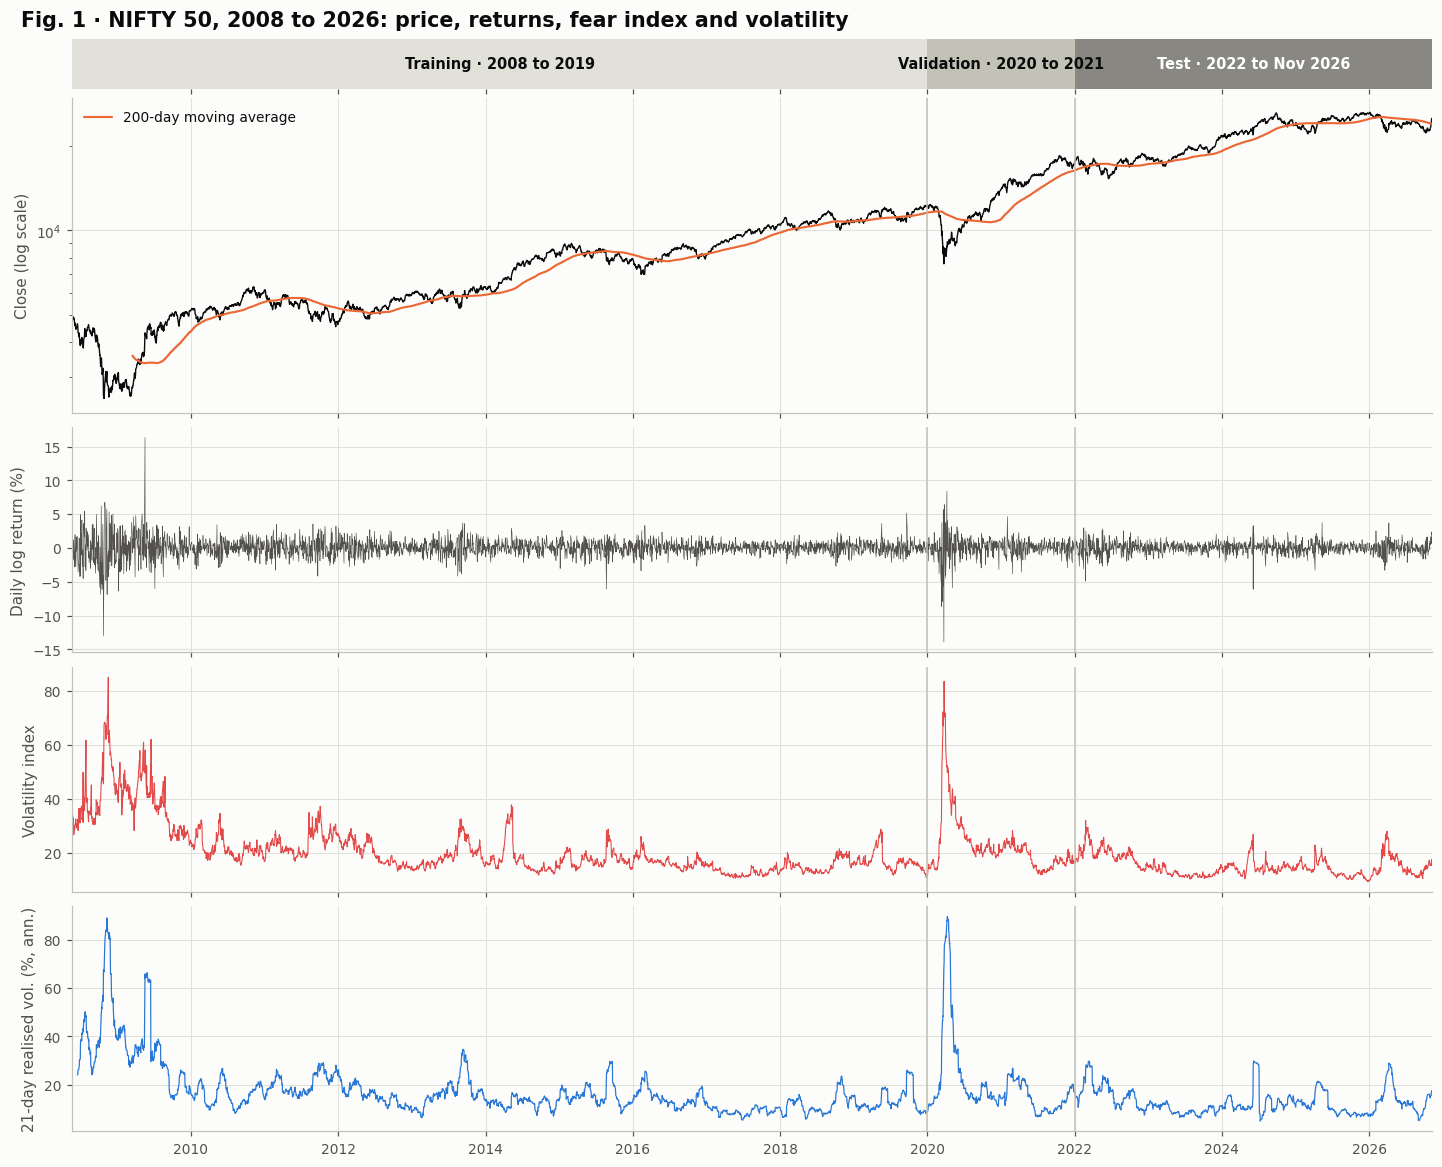

In [7]:
split_edges = [prices.index[0], pd.Timestamp(TRAIN_END) + pd.Timedelta(days=1),
               pd.Timestamp(VAL_END) + pd.Timedelta(days=1), prices.index[-1] + pd.Timedelta(days=1)]
split_names = [f"Training · {split_edges[0]:%Y} to {pd.Timestamp(TRAIN_END):%Y}",
               f"Validation · {split_edges[1]:%Y} to {pd.Timestamp(VAL_END):%Y}",
               f"Test · {split_edges[2]:%Y} to {prices.index[-1]:%b %Y}"]
returns_pct = 100 * feats["ret"]
realised = feats["ret"].rolling(21).std() * np.sqrt(TRADING_DAYS) * 100

fig, axes = plt.subplots(5, 1, figsize=(13, 10.5), sharex=True, gridspec_kw={"height_ratios": [0.22, 1.4, 1, 1, 1]})
ribbon = axes[0]
for (start, end), label, shade in zip(zip(split_edges[:-1], split_edges[1:]), split_names, [GRID, AXIS, MUTED]):
    ribbon.axvspan(start, end, color=shade, lw=0)
    ribbon.text(start + (end - start) / 2, 0.5, label, ha="center", va="center", fontsize=9.5,
                color=INK if shade != MUTED else "white", fontweight="semibold")
ribbon.set_yticks([])
ribbon.grid(False)
for side in ribbon.spines.values():
    side.set_visible(False)
axes[1].plot(prices.index, prices["close"], color=INK, lw=0.9)
axes[1].plot(prices["close"].rolling(200).mean(), color=COLORS["SARIMA"], lw=1.4, label="200-day moving average")
axes[1].set_yscale("log")
axes[1].set_ylabel("Close (log scale)")
axes[1].legend(loc="upper left")
axes[2].plot(returns_pct.index, returns_pct, color=INK_2, lw=0.4)
axes[2].set_ylabel("Daily log return (%)")
axes[3].plot(prices.index, prices["vix"], color="#e34948", lw=0.7)
axes[3].set_ylabel("Volatility index")
axes[4].plot(realised.index, realised, color="#2a78d6", lw=0.8)
axes[4].set_ylabel("21-day realised vol. (%, ann.)")
for ax in axes[1:]:
    for edge in split_edges[1:-1]:
        ax.axvline(edge, color=AXIS, lw=1)
axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[-1].set_xlim(split_edges[0], split_edges[-1])
finish(fig, 1, f"{PRIMARY_ASSET}, {prices.index[0]:%Y} to {prices.index[-1]:%Y}: price, returns, fear index and volatility",
       "market_overview")

**Reading Fig. 1.** The price (log scale, so equal vertical distances mean equal percentage moves) shows long upward trends interrupted by sharp crashes. Daily returns, by contrast, fluctuate around zero with no visible trend, which is why the models forecast returns rather than prices (Section 5). Returns and realised volatility show **volatility clustering**: calm periods and turbulent periods each persist for weeks or months, and the volatility index rises sharply in every crash. Volatility is therefore far more predictable than the direction of the next move, the main motivation for the GARCH model in Section 9.

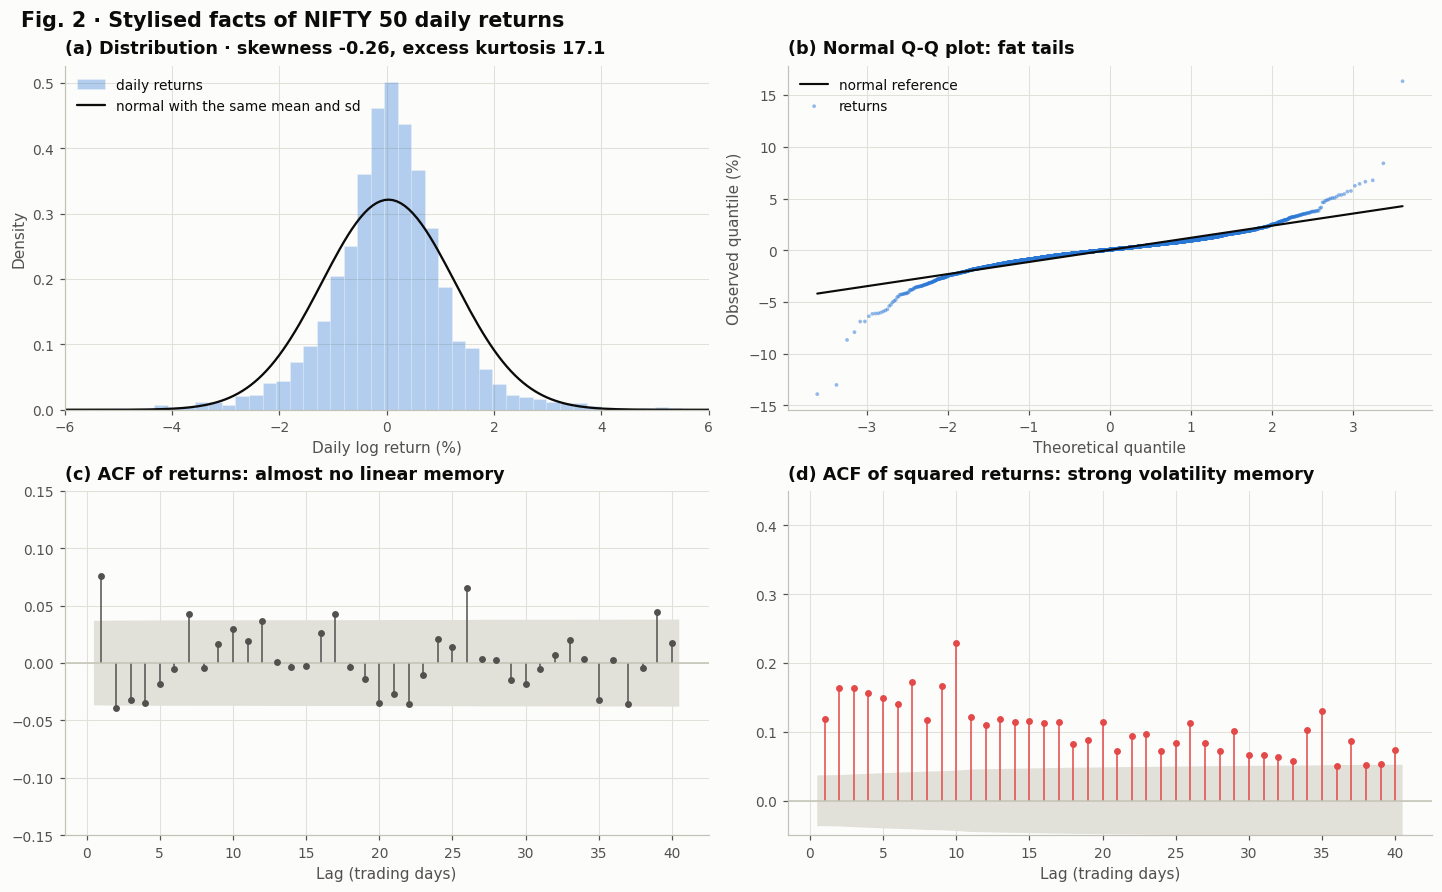

Jarque-Bera normality test: statistic 55,045, p = 0.00e+00
Ljung-Box Q(10) on training returns: 36.6 (p = 0.0001) · on squared returns: 736.6 (p = 8.78e-152)


In [8]:
r = feats["ret"]
train_r = r.loc[:TRAIN_END]
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
ax = axes[0, 0]
ax.hist(100 * r, bins=120, density=True, color="#2a78d6", alpha=0.35, edgecolor=SURFACE, linewidth=0.5, label="daily returns")
grid_x = np.linspace(100 * r.min(), 100 * r.max(), 400)
ax.plot(grid_x, stats.norm.pdf(grid_x, 100 * r.mean(), 100 * r.std()), color=INK, lw=1.5, label="normal with the same mean and sd")
ax.set_xlim(-6, 6)
ax.set_xlabel("Daily log return (%)")
ax.set_ylabel("Density")
ax.set_title(f"(a) Distribution · skewness {stats.skew(r):+.2f}, excess kurtosis {stats.kurtosis(r):.1f}")
ax.legend(loc="upper left")
ax = axes[0, 1]
(osm, osr), (slope, intercept, _) = stats.probplot(100 * r, dist="norm")
ax.plot(osm, slope * osm + intercept, color=INK, lw=1.4, label="normal reference")
ax.scatter(osm, osr, s=6, color="#2a78d6", alpha=0.5, edgecolors="none", label="returns")
ax.set_title("(b) Normal Q-Q plot: fat tails")
ax.set_xlabel("Theoretical quantile")
ax.set_ylabel("Observed quantile (%)")
ax.legend(loc="upper left")

def tidy_correlogram(ax, title, color=INK_2, markersize=3.5):
    for artist in ax.collections:
        if isinstance(artist, PolyCollection):
            artist.set_facecolor(GRID)
            artist.set_alpha(1.0)
            artist.set_zorder(0.5)
    for line in ax.lines:
        if line.get_marker() not in (None, "None", ""):
            line.set_color(color)
            line.set_markersize(markersize)
        else:
            line.set_color(AXIS)
            line.set_linewidth(1)
    ax.set_title(title)
    ax.set_xlabel("Lag (trading days)")

plot_acf(train_r, lags=40, ax=axes[1, 0], zero=False, vlines_kwargs={"colors": INK_2, "lw": 1})
tidy_correlogram(axes[1, 0], "(c) ACF of returns: almost no linear memory")
axes[1, 0].set_ylim(-0.15, 0.15)
plot_acf(train_r ** 2, lags=40, ax=axes[1, 1], zero=False, vlines_kwargs={"colors": "#e34948", "lw": 1})
tidy_correlogram(axes[1, 1], "(d) ACF of squared returns: strong volatility memory", color="#e34948")
axes[1, 1].set_ylim(-0.05, 0.45)
finish(fig, 2, f"Stylised facts of {PRIMARY_ASSET} daily returns", "stylised_facts")

jb_stat, jb_p = stats.jarque_bera(r)
lb_r = acorr_ljungbox(train_r, lags=[10])
lb_r2 = acorr_ljungbox(train_r ** 2, lags=[10])
print(f"Jarque-Bera normality test: statistic {jb_stat:,.0f}, p = {jb_p:.2e}")
print(f"Ljung-Box Q(10) on training returns: {float(lb_r['lb_stat'].iloc[0]):.1f} (p = {float(lb_r['lb_pvalue'].iloc[0]):.4f}) · "
      f"on squared returns: {float(lb_r2['lb_stat'].iloc[0]):.1f} (p = {float(lb_r2['lb_pvalue'].iloc[0]):.2e})")

**Reading Fig. 2.** These are the *stylised facts* of financial returns (Cont, 2001), and they shape every modelling choice in this notebook. (a, b) Returns have **fat tails**: extreme days are far more frequent than a normal distribution allows, so Gaussian prediction intervals would be too narrow in crises. (c) The autocorrelations of returns are tiny, so linear models such as ARIMA have very little to work with and the random walk is a strong benchmark. (d) The autocorrelations of *squared* returns are large and decay slowly: volatility has long memory, which GARCH exploits.

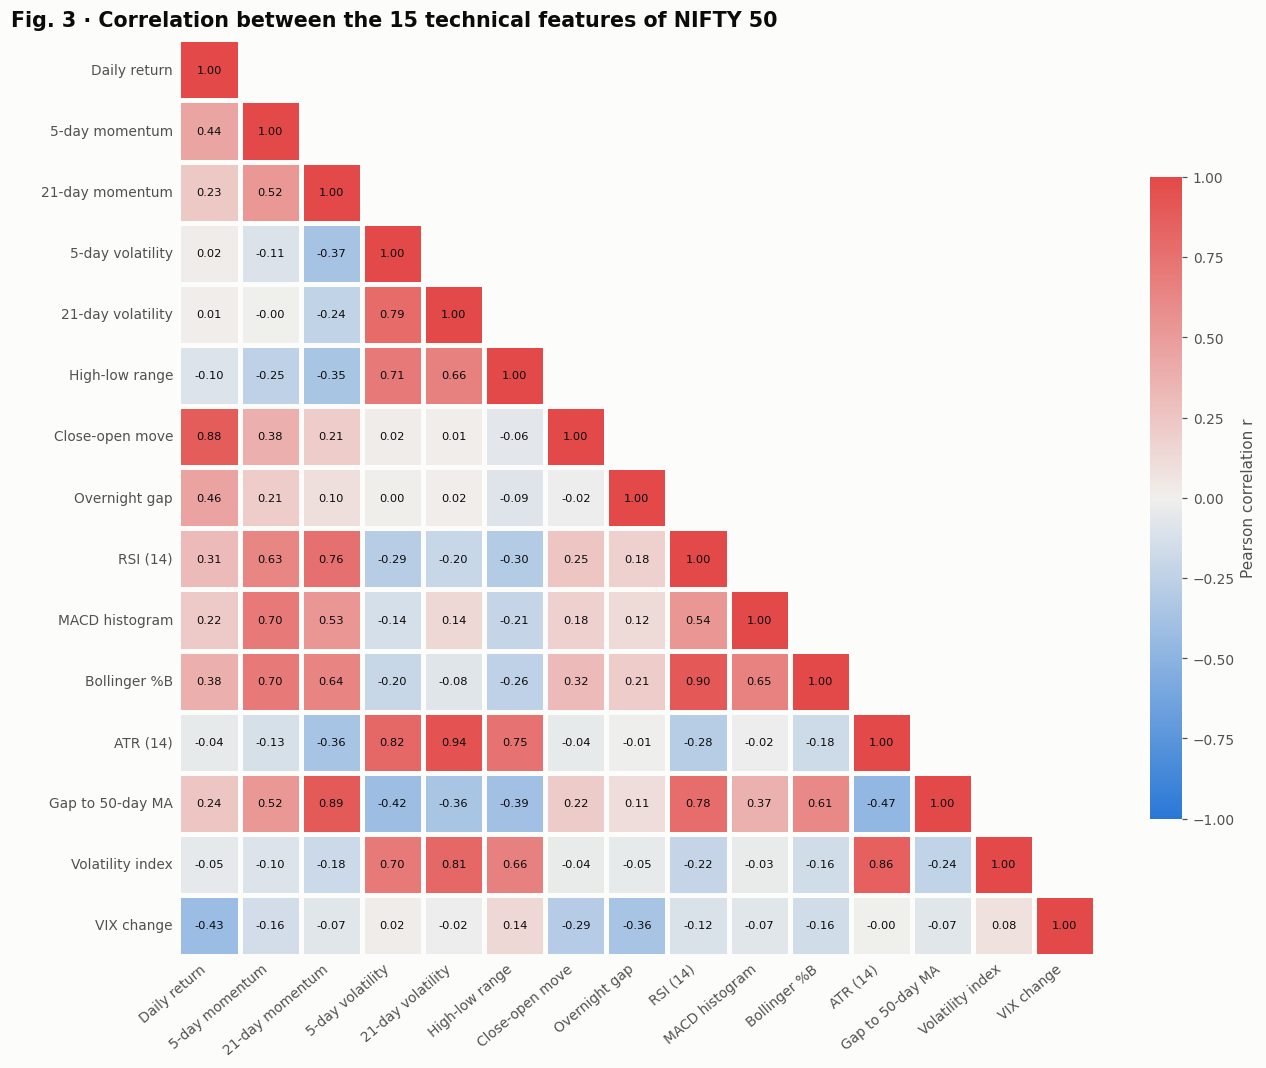

,Trading days,Mean daily return (%),Daily volatility (%),Annualised return (%),Annualised volatility (%),Skewness,Excess kurtosis,Worst day (%),Best day (%)
NIFTY 50,"4,531",0.03,1.24,8.79,19.69,-0.26,17.07,-13.90,16.33
NIFTY Bank,"4,546",0.04,1.66,11.34,26.38,-0.18,10.65,-18.31,17.24
Reliance,"4,555",0.04,1.93,8.89,30.62,0.05,9.39,-17.76,19.37
TCS,"4,555",0.06,1.79,15.15,28.35,0.17,6.11,-10.49,14.41
S&P 500,"4,653",0.04,1.25,9.05,19.80,-0.50,13.06,-12.77,10.96


In [9]:
corr = feats.corr()
names = [FEATURE_LABELS[c] for c in feats.columns]
fig, ax = plt.subplots(figsize=(11.5, 9.6))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), cmap=DIVERGING, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 7.5, "color": INK}, square=True, linewidths=2,
            linecolor=SURFACE, cbar_kws={"shrink": 0.7, "label": "Pearson correlation r"},
            xticklabels=names, yticklabels=names, ax=ax)
ax.grid(False)
ax.tick_params(length=0)
plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
finish(fig, 3, f"Correlation between the {feats.shape[1]} technical features of {PRIMARY_ASSET}", "feature_correlation")

describe = pd.DataFrame({name: {"Trading days": len(f), "Mean daily return (%)": 100 * f["ret"].mean(),
                                "Daily volatility (%)": 100 * f["ret"].std(),
                                "Annualised return (%)": 100 * f["ret"].mean() * TRADING_DAYS,
                                "Annualised volatility (%)": 100 * f["ret"].std() * np.sqrt(TRADING_DAYS),
                                "Skewness": stats.skew(f["ret"]), "Excess kurtosis": stats.kurtosis(f["ret"]),
                                "Worst day (%)": 100 * f["ret"].min(), "Best day (%)": 100 * f["ret"].max()}
                         for name, (df, f, _) in DATA.items()}).T
show_table(describe, 3, "Descriptive statistics of daily log returns for all five assets",
           fmt={col: ("{:,.0f}" if col == "Trading days" else "{:.2f}") for col in describe.columns})

**Reading Fig. 3.** Features from the same family are strongly correlated: the volatility measures (5-day and 21-day volatility, range, ATR and the volatility index) move together, and so do the trend measures (momentum, MACD, RSI, Bollinger %B and the gap to the moving average). The daily return itself is only weakly correlated with yesterday's features, which is what an efficient market implies. Correlated inputs are not a problem for regularised neural networks, but they explain why adding more technical indicators rarely adds much forecasting power.

## 5 · Time-series diagnostics

ARIMA-type models require a stationary series. The ADF test (H₀: *unit root*) and the KPSS test (H₀: *stationary*) are run on the training years for the log price and for the daily log return. A non-stationary log price combined with stationary returns is the classic random-walk signature: the price must be differenced once ($d = 1$), which is exactly what modelling the **returns** does. All models in this notebook therefore forecast returns, and price forecasts are rebuilt as $\hat P_{t+h} = P_t \exp(\hat R_{t,h})$, where $\hat R_{t,h}$ is the forecast cumulative log return over the next $h$ days.

In [10]:
def stationarity(series):
    adf_stat, adf_p, *_ = adfuller(series, autolag="AIC")
    kpss_c, kpss_c_p, *_ = kpss(series, regression="c", nlags="auto")
    kpss_t, kpss_t_p, *_ = kpss(series, regression="ct", nlags="auto")
    if adf_p < 0.05 and kpss_c_p > 0.05:
        verdict = "Stationary"
    elif adf_p < 0.05:
        verdict = "No unit root (ADF); KPSS rejects"
    elif min(kpss_c_p, kpss_t_p) <= 0.05:
        verdict = "Unit root, difference once"
    else:
        verdict = "Inconclusive"
    return {"ADF statistic": adf_stat, "ADF p": adf_p, "KPSS level": kpss_c, "KPSS level p": kpss_c_p,
            "KPSS trend": kpss_t, "KPSS trend p": kpss_t_p, "Verdict": verdict}

stationarity_table = pd.DataFrame({
    "Log price ln P": stationarity(np.log(prices["close"].loc[:TRAIN_END])),
    "Daily log return r": stationarity(train_r),
    "Squared return r²": stationarity(train_r ** 2),
}).T
show_table(stationarity_table, 4, f"Stationarity tests on the training years ({train_r.index[0]:%Y} to {train_r.index[-1]:%Y})",
           fmt={c: "{:.3f}" for c in stationarity_table.columns if c != "Verdict"})
print("KPSS p-values are interpolated from a look-up table and are capped to the interval [0.01, 0.10].")

,ADF statistic,ADF p,KPSS level,KPSS level p,KPSS trend,KPSS trend p,Verdict
Log price ln P,-0.476,0.897,8.043,0.010,0.168,0.032,"Unit root, difference once"
Daily log return r,-28.100,0.000,0.088,0.100,0.052,0.100,Stationary
Squared return r²,-8.840,0.000,2.520,0.010,0.564,0.010,No unit root (ADF); KPSS rejects


KPSS p-values are interpolated from a look-up table and are capped to the interval [0.01, 0.10].


## 6 · Experimental design

**Rolling-origin protocol.** Every trading day of the evaluation period is a forecast *target* at every lead $h = 1, \dots, H$ with $H = 20$ trading days (about one month). The forecast of day $j$ at lead $h$ is issued at the close of day $j - h$, using only information available then. Model **parameters are estimated once on the training years and then frozen**; as new days arrive, models only update their *state* (the Kalman filter for ARIMA and SARIMA, the GARCH variance recursion, the input window for the networks). Because **every lead is scored on exactly the same test days**, differences between leads reflect the lead alone.

**Safeguards against data leakage**
* The split is chronological: no shuffling across time, and the test period is used exactly once.
* Every feature uses past prices only, and the feature scaler and every model parameter are estimated from **training data only**.
* The validation years (2020 and 2021) are used only for hyperparameter selection, early stopping, hybrid weights and interval calibration.
* Neural-network training windows have their whole 20-day target inside the training years.

**Metrics.** Price forecasts are judged on the price level and on returns, because the two tell very different stories. A price forecast that simply repeats today's close already has an $R^2$ above 0.99, since tomorrow's price is close to today's; price-level metrics therefore cannot separate a useful model from a trivial one. The scientifically meaningful comparison is on **returns**:

| Metric | Definition | Why |
|---|---|---|
| Price RMSE, MAE, MAPE, R² | errors of $\hat P_{t+h}$ in index points or rupees | intuitive, but dominated by persistence |
| Return RMSE, MAE | errors of the cumulative log return $\hat R_{t,h}$, in % | the forecastable part of the price change |
| $R^2_{OS}$ | $1 - \sum (R - \hat R)^2 / \sum R^2$ | out-of-sample R² against the random walk (Campbell & Thompson, 2008); **above 0 beats the random walk** |
| Directional accuracy | share of days on which $\operatorname{sign}(\hat R) = \operatorname{sign}(R)$ | what a trader needs; 50 % is a coin flip |
| Pesaran-Timmermann test | test of directional accuracy against independence (1992) | is the hit rate better than chance? |
| Diebold-Mariano test | equal squared-error accuracy of two models (1995, HLN-corrected) | is a difference in RMSE real? |
| Sharpe ratio, CAGR, drawdown | performance of a long-or-cash trading rule after costs | economic value of the forecasts |

**Baselines.**
* **Random walk:** $\hat P_{t+h} = P_t$, the efficient-market benchmark. It is notoriously hard to beat (Meese & Rogoff, 1983).
* **Drift:** $\hat P_{t+h} = P_t \exp(h\,\bar r)$, the random walk with the average training-period return.

**6.1 The forecasting context.** Every asset's data, split indices, forecasts and fitted models are kept in one context object `c`, so the identical pipeline can be re-run for any asset in Section 15. Forecasts are stored as **log prices of target days**: row $j$, column $h$ of `c.FC[model]["test"]` holds the forecast of $\ln P_j$ issued $h$ days earlier. `c.R` holds the realised cumulative log returns $R_{t,h} = \ln P_{t+h} - \ln P_t$. The neural networks receive them divided by GARCH's forecast volatility (Section 10).

In [11]:
def make_context(name):
    df, feats, use_volume = DATA[name]
    c = SimpleNamespace(name=name, df=df, feats=feats, use_volume=use_volume)
    c.dates = df.index
    c.close = df["close"].to_numpy()
    c.p = np.log(c.close)
    c.r = feats["ret"].to_numpy()
    c.n = len(c.p)
    c.n_train = int((c.dates <= TRAIN_END).sum())
    c.n_val = int(((c.dates > TRAIN_END) & (c.dates <= VAL_END)).sum())
    c.val_targets = np.arange(c.n_train, c.n_train + c.n_val)
    c.test_targets = np.arange(c.n_train + c.n_val, c.n)
    c.origins = np.arange(c.n_train - H, c.n - 1)
    c.test_dates = c.dates[c.test_targets]
    c.future_index = pd.bdate_range(c.dates[-1] + pd.Timedelta(days=1), periods=H)
    c.mu = float(c.r[:c.n_train].mean())
    c.sigma = float(c.r[:c.n_train].std())
    ahead = np.arange(c.n)[:, None] + LEADS[None, :]
    c.R = np.where(ahead < c.n, c.p[np.minimum(ahead, c.n - 1)] - c.p[:, None], np.nan)
    c.nn_val = np.arange(c.n_train - 1, c.n_train + c.n_val - H)
    c.FC = {}
    return c

def by_target(c, paths, targets):
    rows = targets[:, None] - LEADS[None, :] - c.origins[0]
    return paths[rows, LEADS - 1]

def register(c, name, origin_paths, future_path):
    c.FC[name] = {"val": by_target(c, origin_paths, c.val_targets), "test": by_target(c, origin_paths, c.test_targets),
                  "future": np.asarray(future_path, dtype=float)}

ctx = make_context(PRIMARY_ASSET)
split_table = pd.DataFrame({
    "Period": [f"{ctx.dates[0]:%d %b %Y} to {ctx.dates[ctx.n_train - 1]:%d %b %Y}",
               f"{ctx.dates[ctx.n_train]:%d %b %Y} to {ctx.dates[ctx.n_train + ctx.n_val - 1]:%d %b %Y}",
               f"{ctx.test_dates[0]:%d %b %Y} to {ctx.test_dates[-1]:%d %b %Y}"],
    "Trading days": [ctx.n_train, ctx.n_val, len(ctx.test_targets)],
    "Used for": ["estimating every model parameter",
                 "hyperparameter selection · early stopping · hybrid weights · interval calibration",
                 "final, one-time evaluation: every day is a target at every lead"]},
    index=["Training", "Validation", "Test"])
show_table(split_table, 5, "Chronological data split", fmt={"Trading days": "{:,}"})

,Period,Trading days,Used for
Training,20 May 2008 to 31 Dec 2019,"2,836",estimating every model parameter
Validation,01 Jan 2020 to 31 Dec 2021,498,hyperparameter selection · early stopping · hybrid weights · interval calibration
Test,03 Jan 2022 to 06 Nov 2026,"1,197","final, one-time evaluation: every day is a target at every lead"


**6.2 Metric functions.** `forecast_returns` turns stored log-price forecasts into cumulative-return forecasts at a given lead, `price_metrics` and `return_metrics` compute the measures in the table above, and `pesaran_timmermann` tests whether the direction of the forecasts is related to the direction of the market. A model that never forecasts a move (the random walk) has no defined direction, so its directional accuracy is reported as n/a.

In [12]:
def forecast_returns(c, F, targets, h):
    return F[:, h - 1] - c.p[targets - h]

def actual_returns(c, targets, h):
    return c.p[targets] - c.p[targets - h]

def pesaran_timmermann(actual, predicted):
    a, f = actual > 0, predicted > 0
    n = len(a)
    p_hat, py, px = np.mean(a == f), a.mean(), f.mean()
    p_star = py * px + (1 - py) * (1 - px)
    v_hat = p_star * (1 - p_star) / n
    v_star = ((2 * py - 1) ** 2 * px * (1 - px) + (2 * px - 1) ** 2 * py * (1 - py)) / n + 4 * py * px * (1 - py) * (1 - px) / n ** 2
    if v_hat - v_star <= 1e-15:
        return np.nan
    return float(stats.norm.sf((p_hat - p_star) / np.sqrt(v_hat - v_star)))

def price_metrics(true_logp, pred_logp):
    t, p = np.exp(true_logp), np.exp(pred_logp)
    e = t - p
    return {"Price RMSE": np.sqrt(np.mean(e ** 2)), "Price MAE": np.mean(np.abs(e)), "Price MAPE (%)": 100 * np.mean(np.abs(e) / t),
            "Price R²": r2_score(t, p)}

def return_metrics(actual, predicted):
    e = actual - predicted
    out = {"Return RMSE (%)": 100 * np.sqrt(np.mean(e ** 2)), "Return MAE (%)": 100 * np.mean(np.abs(e)),
           "R²_OS vs random walk (%)": 100 * (1 - np.sum(e ** 2) / np.sum(actual ** 2))}
    moving = predicted != 0
    if moving.mean() > 0.5:
        out["Directional accuracy (%)"] = 100 * np.mean(np.sign(predicted[moving]) == np.sign(actual[moving]))
        out["Pesaran-Timmermann p"] = pesaran_timmermann(actual[moving], predicted[moving])
    else:
        out["Directional accuracy (%)"], out["Pesaran-Timmermann p"] = np.nan, np.nan
    return out

def model_returns(c, name, h, split="test"):
    targets = c.test_targets if split == "test" else c.val_targets
    return actual_returns(c, targets, h), forecast_returns(c, c.FC[name][split], targets, h)

**6.3 Baselines.** The random walk repeats the last log price at every lead; the drift model adds $h$ times the average daily training return.

In [13]:
def fit_baselines(c):
    register(c, "Random walk", np.repeat(c.p[c.origins][:, None], H, axis=1), np.full(H, c.p[-1]))
    register(c, "Drift", c.p[c.origins][:, None] + c.mu * LEADS[None, :], c.p[-1] + c.mu * LEADS)

t0 = time.time()
fit_baselines(ctx)
COST_LOG["Random walk"] = {"Parameters": 0, "Wall-clock time (s)": 0.0}
COST_LOG["Drift"] = {"Parameters": 1, "Wall-clock time (s)": time.time() - t0}
print(f"Average daily training return {100 * ctx.mu:+.4f} % ({100 * ctx.mu * TRADING_DAYS:+.1f} % a year) · "
      f"daily volatility {100 * ctx.sigma:.3f} %")

Average daily training return +0.0303 % (+7.6 % a year) · daily volatility 1.303 %


## 7 · ARIMA

An ARIMA$(p,1,q)$ model for the log price is an ARMA$(p,q)$ model for the daily return $r_t$:

$$\phi(B)\,(r_t - \mu) = \theta(B)\,\varepsilon_t,$$

with $\phi(B) = 1-\phi_1B-\dots-\phi_pB^p$ and $\theta(B) = 1+\theta_1B+\dots+\theta_qB^q$. The orders $p, q \in \{0,\dots,3\}$ are chosen by the **Akaike Information Criterion** $\text{AIC} = 2k - 2\ln\hat L$. ARIMA$(0,1,0)$ with a mean is exactly the drift model, so ARIMA can only improve on it if returns have exploitable linear memory.

**Exact forecasts from every origin, in one pass.** The model is written in state-space form and the Kalman filter runs over the full series once, with parameters frozen. The one-step-ahead state at each origin is propagated with the transition matrix, $a_{i+h|i} = T^{h-1} a_{i+1|i}$, giving the return forecasts $\hat r_{i+h|i}$; their cumulative sum gives the log-price forecast. The result is identical to statsmodels' own `get_forecast()` (verified below) and orders of magnitude faster than refitting at every origin.

**7.1 Shared helpers for state-space models.** `fit_many` fits a list of candidate models in parallel on all CPU cores; `aic_search` ranks them by AIC (converged fits first). `state_space_paths` implements the one-pass forecast, and `verify_paths` re-computes one origin with statsmodels' native routine and asserts that both agree to machine precision.

In [14]:
def fit_candidate(endog, exog, order, seasonal_order):
    warnings.filterwarnings("ignore")
    return SARIMAX(endog, exog=exog, order=order, seasonal_order=seasonal_order, trend="n").fit(disp=False)

def fit_many(endog, exog, specs):
    return Parallel(n_jobs=N_JOBS, max_nbytes=None)(delayed(fit_candidate)(endog, exog, order, seasonal) for order, seasonal in specs)

def aic_search(endog, exog, specs):
    rows = []
    for (order, seasonal), res in zip(specs, fit_many(endog, exog, specs)):
        rows.append({"p": order[0], "q": order[2], "P": seasonal[0], "Q": seasonal[2], "AIC": res.aic, "BIC": res.bic,
                     "converged": bool(res.mle_retvals.get("converged", True)), "result": res})
    table = pd.DataFrame(rows).sort_values(["converged", "AIC"], ascending=[False, True]).reset_index(drop=True)
    table.insert(6, "ΔAIC", table["AIC"] - table["AIC"].iloc[0])
    return table

def state_space_paths(res, endog, exog, exog_future):
    full = res.apply(endog, exog=exog)
    fr = full.filter_results
    Z, T, c0 = fr.design[:, :, 0], fr.transition[:, :, 0], fr.state_intercept[:, 0]
    m = len(endog)
    A = fr.predicted_state[:, 1:m + 1].copy()
    beta = res.params[list(exog.columns)].to_numpy()
    xb = np.vstack([exog.to_numpy(), exog_future.to_numpy()]) @ beta
    paths = np.empty((m, H))
    for h in range(H):
        paths[:, h] = xb[np.arange(m) + h + 1] + (Z @ A)[0]
        A = T @ A + c0[:, None]
    return paths, full

def verify_paths(c, res, paths, endog, exog, exog_future):
    origin = c.test_targets[len(c.test_targets) // 2]
    exog_all = pd.concat([exog, exog_future])
    partial = res.apply(endog.iloc[:origin + 1], exog=exog.iloc[:origin + 1])
    reference = partial.get_forecast(H, exog=exog_all.iloc[origin + 1:origin + 1 + H])
    gap = float(np.max(np.abs(reference.predicted_mean.to_numpy() - paths[origin])))
    assert gap < 1e-8, f"state-space paths disagree with statsmodels (max gap {gap:.2e})"
    return gap

def parameter_table(res):
    return pd.DataFrame({"estimate": res.params, "std. error": res.bse, "z": res.tvalues, "p-value": res.pvalues})

def statistical_setup(c):
    c.y = pd.Series(c.r)
    mean_term = pd.DataFrame({"mean": np.ones(c.n + H)})
    c.exog, c.exog_future = mean_term.iloc[:c.n], mean_term.iloc[c.n:]

def register_returns_model(c, name, return_paths):
    logp_paths = c.p[:, None] + np.cumsum(return_paths, axis=1)
    register(c, name, logp_paths[c.origins], logp_paths[c.n - 1])
    return logp_paths

**7.2 Order selection, estimation and forecasts.**

In [15]:
def fit_arima(c):
    statistical_setup(c)
    specs = [((p, 0, q), (0, 0, 0, 0)) for p in range(ARMA_MAX + 1) for q in range(ARMA_MAX + 1)]
    search = aic_search(c.y.iloc[:c.n_train], c.exog.iloc[:c.n_train], specs)
    c.arima_res = search.loc[0, "result"]
    c.arima_order = (int(search.loc[0, "p"]), 1, int(search.loc[0, "q"]))
    search = search.drop(columns="result")
    c.F_arima, c.arima_full = state_space_paths(c.arima_res, c.y, c.exog, c.exog_future)
    c.arima_gap = verify_paths(c, c.arima_res, c.F_arima, c.y, c.exog, c.exog_future)
    register_returns_model(c, "ARIMA", c.F_arima)
    return search

t0 = time.time()
arima_search = fit_arima(ctx)
COST_LOG["ARIMA"] = {"Parameters": len(ctx.arima_res.params), "Wall-clock time (s)": time.time() - t0}
print(f"Searched {len(arima_search)} candidate models in {time.time() - t0:.1f} s, ARIMA{ctx.arima_order} selected")
print(f"Vectorised forecasts match statsmodels get_forecast() exactly (max |difference| = {ctx.arima_gap:.1e})")
show_table(arima_search.drop(columns=["P", "Q"]).head(5), 6, "ARIMA candidates for daily returns ranked by AIC (top 5)",
           fmt={"AIC": "{:.1f}", "ΔAIC": "{:.1f}", "BIC": "{:.1f}"}, index=False)
show_table(parameter_table(ctx.arima_res), 7, f"ARIMA{ctx.arima_order} parameter estimates (training years)", fmt="{:.5f}")

Searched 16 candidate models in 15.5 s, ARIMA(2, 1, 1) selected
Vectorised forecasts match statsmodels get_forecast() exactly (max |difference| = 0.0e+00)


p,q,AIC,BIC,ΔAIC,converged
2,1,-16587.2,-16557.4,0.0,True
2,0,-16585.5,-16561.7,1.7,True
3,0,-16585.3,-16555.5,1.9,True
0,3,-16585.1,-16555.3,2.1,True
0,2,-16584.8,-16561.0,2.4,True


,estimate,std. error,z,p-value
mean,0.00030,0.00025,1.20324,0.22889
ar.L1,0.63395,0.13399,4.73146,0.00000
ar.L2,-0.08818,0.01203,-7.33289,0.00000
ma.L1,-0.55542,0.13492,-4.11671,0.00004
sigma2,0.00017,0.00000,103.64280,0.00000


## 8 · SARIMA with a weekly trading cycle

Calendar effects such as the *day-of-the-week effect* (French, 1980) suggest that returns might depend on the position in the trading week. SARIMA tests this with seasonal ARMA terms at a period of $s = 5$ trading days:

$$\phi(B)\,\Phi(B^5)\,(r_t - \mu) = \theta(B)\,\Theta(B^5)\,\varepsilon_t .$$

The orders $p, q \in \{0, 1, 2\}$ and $P, Q \in \{0, 1\}$ (at least one seasonal term) are fitted on the training years and then **selected by their one-step forecast RMSE on the validation years**, with parameters frozen, rather than by AIC. AIC rewards in-sample fit, and the small autocorrelations of daily returns that it detects in 2008 to 2019 need not persist out of sample, a well-known trap in return forecasting (Campbell & Thompson, 2008). Selecting on the validation years is the same rule used for every neural hyperparameter and keeps the test period untouched. ARIMA keeps the classical AIC selection, so the two procedures can be compared directly in the results. Holidays make the trading week slightly irregular, so $s = 5$ is an approximation. If the weekly terms carry no information, SARIMA will be no better than ARIMA, which is itself a useful finding.

**SARIMA is the linear base of the whole system**, as in the companion weather study: its one-step errors feed the GARCH volatility model (Section 9) and the residual learner of Hybrid-R, and it is the statistical partner in Hybrid-E (Section 12). Its impulse response $\psi_k$, the effect of today's shock on the return $k$ days later, is computed from the full lag polynomials $\phi(B)\Phi(B^5)$ and $\theta(B)\Theta(B^5)$, so the weekly terms are included.

In [16]:
def lag_polynomial(params, period, sign):
    poly = np.zeros(len(params) * period + 1)
    poly[0] = 1.0
    poly[period * np.arange(1, len(params) + 1)] = sign * np.asarray(params)
    return poly

def fit_sarima(c):
    specs = [((p, 0, q), (P, 0, Q, SEASONAL_PERIOD)) for p in range(SARIMA_MAX + 1) for q in range(SARIMA_MAX + 1)
             for P in (0, 1) for Q in (0, 1) if P + Q > 0]
    search = aic_search(c.y.iloc[:c.n_train], c.exog.iloc[:c.n_train], specs)
    val = slice(c.n_train, c.n_train + c.n_val)
    search["Validation RMSE (%)"] = [100 * np.sqrt(np.mean((c.r[val] - res.apply(c.y, exog=c.exog).fittedvalues.to_numpy()[val]) ** 2))
                                     for res in search["result"]]
    search = search.sort_values(["converged", "Validation RMSE (%)"], ascending=[False, True]).reset_index(drop=True)
    c.sarima_res = search.loc[0, "result"]
    c.sarima_order = (int(search.loc[0, "p"]), 1, int(search.loc[0, "q"]))
    search = search.drop(columns="result")
    c.seasonal_order = (int(search.loc[0, "P"]), 0, int(search.loc[0, "Q"]), SEASONAL_PERIOD)
    c.F_sarima, c.sarima_full = state_space_paths(c.sarima_res, c.y, c.exog, c.exog_future)
    c.sarima_gap = verify_paths(c, c.sarima_res, c.F_sarima, c.y, c.exog, c.exog_future)
    c.sarima_logp = register_returns_model(c, "SARIMA", c.F_sarima)
    res = c.sarima_res
    ar = np.convolve(lag_polynomial(res.arparams, 1, -1), lag_polynomial(res.seasonalarparams, SEASONAL_PERIOD, -1))
    ma = np.convolve(lag_polynomial(res.maparams, 1, 1), lag_polynomial(res.seasonalmaparams, SEASONAL_PERIOD, 1))
    c.psi = arma2ma(ar, ma, lags=H)
    c.cum_psi = np.cumsum(c.psi)
    c.innovations = c.sarima_full.resid.to_numpy()
    return search

t0 = time.time()
sarima_search = fit_sarima(ctx)
COST_LOG["SARIMA"] = {"Parameters": len(ctx.sarima_res.params), "Wall-clock time (s)": time.time() - t0}
print(f"Searched {len(sarima_search)} candidate models in {time.time() - t0:.1f} s, SARIMA{ctx.sarima_order}{ctx.seasonal_order} selected")
print(f"Vectorised forecasts match statsmodels get_forecast() exactly (max |difference| = {ctx.sarima_gap:.1e})")
print(f"AIC: ARIMA {ctx.arima_res.aic:.1f} · SARIMA {ctx.sarima_res.aic:.1f} · difference {ctx.sarima_res.aic - ctx.arima_res.aic:+.1f} "
      f"({'the weekly terms improve the fit' if ctx.sarima_res.aic < ctx.arima_res.aic - 2 else 'no meaningful weekly effect'})")
aic_best = sarima_search.loc[sarima_search["AIC"].idxmin()]
print(f"One-step validation RMSE: selected SARIMA {sarima_search.loc[0, 'Validation RMSE (%)']:.4f} % · "
      f"AIC-best SARIMA candidate {aic_best['Validation RMSE (%)']:.4f} %")
show_table(sarima_search.head(5), 8, "SARIMA candidates ranked by one-step RMSE on the validation years (top 5; AIC shown for reference)",
           fmt={"AIC": "{:.1f}", "ΔAIC": "{:.1f}", "BIC": "{:.1f}", "Validation RMSE (%)": "{:.4f}"}, index=False)
show_table(parameter_table(ctx.sarima_res), 9, "SARIMA parameter estimates (training years)", fmt="{:.5f}")

Searched 27 candidate models in 33.8 s, SARIMA(0, 1, 0)(1, 0, 1, 5) selected
Vectorised forecasts match statsmodels get_forecast() exactly (max |difference| = 0.0e+00)
AIC: ARIMA -16587.2 · SARIMA -16564.4 · difference +22.8 (no meaningful weekly effect)
One-step validation RMSE: selected SARIMA 1.5851 % · AIC-best SARIMA candidate 1.6110 %


p,q,P,Q,AIC,BIC,ΔAIC,converged,Validation RMSE (%)
0,0,1,1,-16564.4,-16540.6,20.5,True,1.5851
0,0,1,0,-16566.1,-16548.2,18.9,True,1.5855
0,0,0,1,-16566.0,-16548.1,18.9,True,1.5855
2,2,1,0,-16577.5,-16535.9,7.4,True,1.5996
1,0,1,1,-16578.5,-16548.8,6.4,True,1.6011


,estimate,std. error,z,p-value
mean,0.00030,0.00025,1.20965,0.22641
ar.S.L5,-0.14862,0.54268,-0.27387,0.78419
ma.S.L5,0.13060,0.54327,0.24039,0.81003
sigma2,0.00017,0.00000,97.46195,0.00000


## 9 · GARCH(1,1): forecasting volatility

The mean forecasts above say where the price is expected to go; GARCH (Bollerslev, 1986) says **how uncertain** that is. The one-step forecast errors (innovations) $\varepsilon_t$ of SARIMA are modelled as $\varepsilon_t = \sigma_t z_t$ with

$$\sigma_t^2 = \omega + \alpha\,\varepsilon_{t-1}^2 + \beta\,\sigma_{t-1}^2 ,$$

so today's variance rises after a large surprise ($\alpha$) and decays slowly ($\beta$). The persistence $\alpha + \beta$ controls how long turbulence lasts. The parameters are estimated by Gaussian quasi-maximum likelihood on the training years, and the $h$-step variance forecast follows in closed form:

$$\sigma^2_{t+h|t} = \bar\sigma^2 + (\alpha+\beta)^{h-1}\left(\sigma^2_{t+1|t} - \bar\sigma^2\right), \qquad \bar\sigma^2 = \frac{\omega}{1-\alpha-\beta}.$$

The variance of the cumulative return over $h$ days is approximately $\sum_{k=1}^{h}\sigma^2_{t+k|t}$, because daily returns are nearly uncorrelated. Its square root, `c.garch_cumsd`, plays two roles: it scales the neural networks' targets (Sections 10 to 12), and it scales the prediction intervals in Section 14, so the intervals widen in turbulent markets and narrow in calm ones. The parameters are reparameterised so that $\omega > 0$, $\alpha, \beta \ge 0$ and $\alpha + \beta < 1$ always hold, and the variance recursion is computed with a linear filter (`lfilter`), which is fast enough to evaluate the likelihood thousands of times.

,estimate
ω,1.07223e-06
α (reaction to news),0.0727235
β (memory),0.921263
persistence α + β,0.993987
half-life of a shock (days),114.92
"long-run volatility (%, annualised)",21.1974


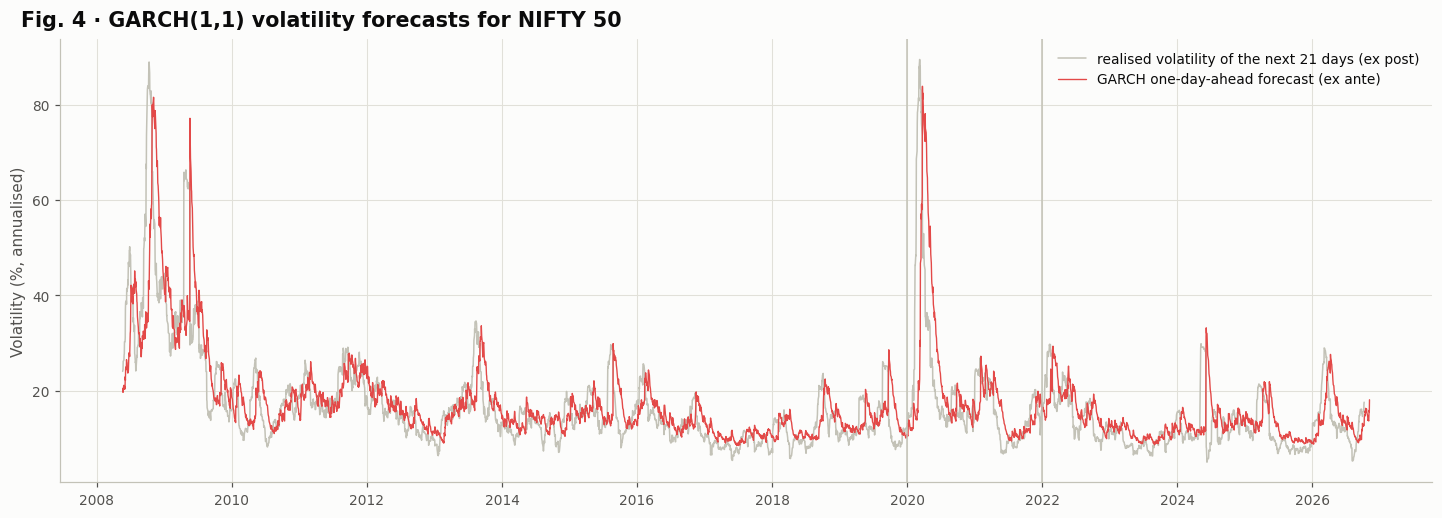

In [17]:
def garch_filter(e, omega, alpha, beta, s0):
    x = np.empty(len(e))
    x[0] = s0
    x[1:] = omega + alpha * e[:-1] ** 2
    return lfilter([1.0], [1.0, -beta], x)

def garch_params(theta):
    omega = np.exp(theta[0])
    persistence = 1 / (1 + np.exp(-theta[1]))
    share = 1 / (1 + np.exp(-theta[2]))
    return omega, persistence * share, persistence * (1 - share)

def fit_garch(c):
    e = np.nan_to_num(c.innovations)
    train = e[1:c.n_train]
    s0 = float(train.var())

    def negative_loglik(theta):
        omega, alpha, beta = garch_params(theta)
        s2 = garch_filter(train, omega, alpha, beta, s0)
        return 0.5 * np.sum(np.log(s2) + train ** 2 / s2)

    start = np.array([np.log(s0 * 0.03), np.log(0.97 / 0.03), np.log((0.08 / 0.97) / (1 - 0.08 / 0.97))])
    result = minimize(negative_loglik, start, method="Nelder-Mead", options={"maxiter": 5000, "xatol": 1e-8, "fatol": 1e-8})
    omega, alpha, beta = garch_params(result.x)
    s2 = garch_filter(e, omega, alpha, beta, s0)
    c.garch = {"omega": omega, "alpha": alpha, "beta": beta, "converged": bool(result.success)}
    c.garch_s2 = s2
    c.garch_v1 = omega + alpha * e ** 2 + beta * s2
    long_run = omega / (1 - alpha - beta)
    variance = long_run + (alpha + beta) ** (LEADS - 1)[None, :] * (c.garch_v1[:, None] - long_run)
    c.garch_cumsd = np.sqrt(np.cumsum(variance, axis=1))
    return pd.DataFrame({"estimate": [omega, alpha, beta, alpha + beta, np.log(0.5) / np.log(alpha + beta),
                                      100 * np.sqrt(TRADING_DAYS * long_run)]},
                        index=["ω", "α (reaction to news)", "β (memory)", "persistence α + β", "half-life of a shock (days)",
                               "long-run volatility (%, annualised)"])

t0 = time.time()
garch_table = fit_garch(ctx)
COST_LOG["GARCH(1,1)"] = {"Parameters": 3, "Wall-clock time (s)": time.time() - t0}
show_table(garch_table, 10, f"GARCH(1,1) estimates on SARIMA innovations (training years, converged: {ctx.garch['converged']})",
           fmt="{:.6g}")

garch_vol = pd.Series(100 * np.sqrt(TRADING_DAYS * ctx.garch_v1[:-1]), index=ctx.dates[1:])
realised_ahead = pd.Series(100 * np.sqrt(TRADING_DAYS) * pd.Series(ctx.r).rolling(21).std().shift(-20).to_numpy(), index=ctx.dates)
fig, ax = plt.subplots(figsize=(13, 4.6))
ax.plot(realised_ahead.index, realised_ahead, color=AXIS, lw=1.0, label="realised volatility of the next 21 days (ex post)")
ax.plot(garch_vol.index, garch_vol, color="#e34948", lw=0.9, label="GARCH one-day-ahead forecast (ex ante)")
for edge in split_edges[1:-1]:
    ax.axvline(edge, color=AXIS, lw=1)
ax.set_ylabel("Volatility (%, annualised)")
ax.legend(loc="upper right")
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
finish(fig, 4, f"GARCH(1,1) volatility forecasts for {PRIMARY_ASSET}", "garch_volatility")

**Reading Fig. 4.** The GARCH forecast, made each evening for the next day, rises within days of every market shock and decays as calm returns, closely tracking the volatility that is realised afterwards. Persistence close to 1 means a shock's effect on volatility fades slowly (see the half-life in Table 10). This is the predictable part of the market, and Section 14 evaluates it formally.

## 10 · LSTM: a multi-feature recurrent network

**Why an LSTM.** A Long Short-Term Memory network (Hochreiter & Schmidhuber, 1997) reads a sequence one day at a time and carries a *cell state* updated through learned gates:

$$f_t=\sigma(W_f[h_{t-1},x_t]+b_f),\quad i_t=\sigma(W_i[h_{t-1},x_t]+b_i),\quad o_t=\sigma(W_o[h_{t-1},x_t]+b_o)$$
$$c_t = f_t\odot c_{t-1} + i_t\odot\tanh(W_c[h_{t-1},x_t]+b_c),\qquad h_t = o_t\odot\tanh(c_t).$$

It can learn non-linear interactions between momentum, volatility and market fear that a linear SARIMA cannot represent.

**Design decisions**

| Choice | Rationale |
|---|---|
| **Inputs:** a window of past days × all technical features of Section 3.1 | the network sees trend, volatility, fear and activity together |
| **Direct multi-horizon output:** the 20 cumulative returns $R_{t,1}, \dots, R_{t,20}$ at once | features such as the VIX cannot be forecast, so recursive forecasting is impossible; a direct output also avoids error accumulation |
| **Volatility-scaled targets:** each cumulative return $R_{t,h}$ is divided by GARCH's forecast standard deviation $\hat s_{t,h}$ | every target has roughly unit variance, so short and long leads, and calm years and crashes (the validation years contain the 2020 COVID-19 crash), carry comparable weight in the loss; forecasts are multiplied back by $\hat s_{t,h}$ |
| **Random-walk start:** the output layer is initialised to zero | before training the network forecasts no move, exactly the random walk; training moves it away from the random walk only as far as the data support |
| **Hyperparameters optimised per asset on the validation years** | look-back, layer sizes, dropout, learning rate and batch size are chosen by random search on each asset's validation years, never by test results |
| **Seed ensemble** of $N$ networks, averaged | reduces variance and makes results reproducible (Lakshminarayanan et al., 2017) |
| **Regularisation:** tuned dropout, early stopping on the validation years, learning-rate decay | returns are noisy, so a network over-fits within a few epochs without these guards |

```
 input window  (L days × F features)
      └─ LSTM · u₁ units, returns the full sequence ─ Dropout p
          └─ LSTM · u₂ units, returns the last state ─ Dropout p
              └─ Dense · 32 units, ReLU
                  └─ Dense · 20 units, linear  →  scaled cumulative returns for leads 1 to 20
```

**10.1 Features, scaling and training windows.** The scaler is fitted on the training days only, and the targets are the GARCH-scaled cumulative returns `c.R_scaled`. `windows` stacks the `lookback` days that end at each origin into a tensor of shape (origins, lookback, features). Training origins start at the largest look-back in the search space and end 20 days before the last training day, so every target lies inside the training years.

In [18]:
def windows(X, origins, lookback):
    view = np.lib.stride_tricks.sliding_window_view(X, lookback, axis=0)
    return np.ascontiguousarray(view[np.asarray(origins) - lookback + 1].transpose(0, 2, 1), dtype="float32")

def prepare_features(c):
    scaler = StandardScaler().fit(c.feats.iloc[:c.n_train])
    c.X_all = scaler.transform(c.feats).astype("float32")
    c.nn_train = np.arange(max(LSTM_SPACE["lookback"]) - 1, c.n_train - H)
    c.R_scaled = (c.R / c.garch_cumsd).astype("float32")

prepare_features(ctx)
print(f"Training windows {len(ctx.nn_train):,} · validation windows {len(ctx.nn_val):,} · features {ctx.X_all.shape[1]} · outputs {H}")

Training windows 2,757 · validation windows 479 · features 15 · outputs 20


**10.2 Architecture and training.** `build_lstm` creates the network from a configuration dictionary `cfg`; `fit_network` trains it with early stopping on the validation years (the best weights are restored) and halves the learning rate when the validation loss stalls. `mse_ratio` measures a forecast's validation error relative to the random walk, averaged over all 20 leads: below 1 beats the random walk. Each training history also stores the random walk's loss on the training and validation windows (`rw_loss`, `rw_val_loss`), so the learning curves in Fig. 5 can be drawn on the same scale.

In [19]:
def build_lstm(n_features, n_outputs, cfg, seed, name):
    keras.utils.set_random_seed(seed)
    inputs = keras.Input(shape=(cfg["lookback"], n_features), name="market_window")
    x = keras.layers.LSTM(cfg["units"][0], return_sequences=True, name="lstm_1")(inputs)
    x = keras.layers.Dropout(cfg["dropout"], name="dropout_1")(x)
    x = keras.layers.LSTM(cfg["units"][1], name="lstm_2")(x)
    x = keras.layers.Dropout(cfg["dropout"], name="dropout_2")(x)
    x = keras.layers.Dense(32, activation="relu", name="dense_32")(x)
    outputs = keras.layers.Dense(n_outputs, kernel_initializer="zeros", bias_initializer="zeros", name="scaled_returns")(x)
    model = keras.Model(inputs, outputs, name=name)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=cfg["learning_rate"]), loss="mse")
    return model

def fit_network(c, X, target_fn, cfg, seed, name, patience=15):
    X_tr, Y_tr = windows(X, c.nn_train, cfg["lookback"]), target_fn(c.nn_train)
    X_va, Y_va = windows(X, c.nn_val, cfg["lookback"]), target_fn(c.nn_val)
    model = build_lstm(X.shape[1], Y_tr.shape[1], cfg, seed, name)
    history = model.fit(X_tr, Y_tr, validation_data=(X_va, Y_va), epochs=MAX_EPOCHS, batch_size=cfg["batch_size"], verbose=0,
                        callbacks=[keras.callbacks.EarlyStopping(patience=patience, restore_best_weights=True),
                                   keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=5, min_lr=1e-5)]).history
    history["rw_loss"], history["rw_val_loss"] = float(np.mean(Y_tr ** 2)), float(np.mean(Y_va ** 2))
    return model, history

def mse_ratio(truth_scaled, pred_scaled):
    return float(np.mean(np.mean((truth_scaled - pred_scaled) ** 2, axis=0) / np.mean(truth_scaled ** 2, axis=0)))

def lstm_targets(c, origins):
    return c.R_scaled[origins]

**10.3 Hyperparameter optimisation on the validation years.** A full grid over five hyperparameters would need 243 networks per asset. Random search finds configurations as good as a grid with a small fraction of the trials, because only a few hyperparameters usually matter (Bergstra & Bengio, 2012). `sample_configs` draws `LSTM_TRIALS` distinct configurations; the first trial is always `LSTM_DEFAULT`, so the search can never end up worse than the default. Each trial trains one network (same seed) and is scored by its **validation MSE ratio against the random walk**, averaged over the 20 leads. The test period plays no part. The search is repeated on each asset's own validation years in Section 15.

In [20]:
def sample_configs(space, n_trials, default, seed):
    keys = list(space)
    combos = list(itertools.product(*[range(len(space[k])) for k in keys]))
    configs = [dict(default)]
    for i in np.random.default_rng(seed).permutation(len(combos)):
        cfg = {k: space[k][j] for k, j in zip(keys, combos[i])}
        if cfg not in configs:
            configs.append(cfg)
        if len(configs) >= n_trials:
            break
    return configs

def format_cfg(cfg):
    return {key: (" / ".join(map(str, value)) if isinstance(value, tuple) else value) for key, value in cfg.items()}

def tune_lstm(c, verbose=True):
    configs = sample_configs(LSTM_SPACE, LSTM_TRIALS, LSTM_DEFAULT, SEED)
    truth = lstm_targets(c, c.nn_val)
    rows = []
    for i, cfg in enumerate(configs):
        start = time.time()
        model, hist = fit_network(c, c.X_all, lambda o: lstm_targets(c, o), cfg, SEED, f"lstm_trial_{i + 1}", patience=10)
        pred = np.asarray(model.predict(windows(c.X_all, c.nn_val, cfg["lookback"]), verbose=0, batch_size=2048))
        rows.append({"Trial": i + 1, **format_cfg(cfg), "Epochs": len(hist["loss"]),
                     "Validation MSE ratio vs random walk": mse_ratio(truth, pred), "Time (s)": time.time() - start})
        del model
        gc.collect()
        if verbose:
            print(f"  trial {i + 1:>2}/{len(configs)} · {format_cfg(cfg)} · MSE ratio {rows[-1]['Validation MSE ratio vs random walk']:.4f}")
    table = pd.DataFrame(rows)
    c.lstm_cfg = configs[int(table["Validation MSE ratio vs random walk"].idxmin())]
    return table.sort_values("Validation MSE ratio vs random walk").reset_index(drop=True)

t0 = time.time()
lstm_tuning = tune_lstm(ctx)
lstm_search_time = time.time() - t0
print(f"{len(lstm_tuning)} configurations trained in {time.time() - t0:.0f} s, selected: {format_cfg(ctx.lstm_cfg)}")
show_table(lstm_tuning, 11, "LSTM random search on the validation years, best first (one seed each)",
           fmt={"Validation MSE ratio vs random walk": "{:.4f}", "Time (s)": "{:.0f}", "dropout": "{:.1f}",
                "learning_rate": "{:.0e}", "lookback": "{}", "units": "{}", "batch_size": "{}", "Trial": "{}", "Epochs": "{}"},
           low=["Validation MSE ratio vs random walk"], index=False)

  trial  1/10 · {'lookback': 20, 'units': '64 / 32', 'dropout': 0.3, 'learning_rate': 0.0003, 'batch_size': 64} · MSE ratio 0.9991
  trial  2/10 · {'lookback': 20, 'units': '128 / 64', 'dropout': 0.3, 'learning_rate': 0.0001, 'batch_size': 64} · MSE ratio 0.9937
  trial  3/10 · {'lookback': 20, 'units': '128 / 64', 'dropout': 0.2, 'learning_rate': 0.0003, 'batch_size': 32} · MSE ratio 1.0097
  trial  4/10 · {'lookback': 10, 'units': '64 / 32', 'dropout': 0.5, 'learning_rate': 0.001, 'batch_size': 32} · MSE ratio 1.0045
  trial  5/10 · {'lookback': 20, 'units': '128 / 64', 'dropout': 0.5, 'learning_rate': 0.0003, 'batch_size': 128} · MSE ratio 0.9966
  trial  6/10 · {'lookback': 60, 'units': '32 / 16', 'dropout': 0.3, 'learning_rate': 0.0001, 'batch_size': 128} · MSE ratio 0.9954
  trial  7/10 · {'lookback': 10, 'units': '32 / 16', 'dropout': 0.2, 'learning_rate': 0.0003, 'batch_size': 32} · MSE ratio 0.9962
  trial  8/10 · {'lookback': 20, 'units': '64 / 32', 'dropout': 0.5, 'learning_

Trial,lookback,units,dropout,learning_rate,batch_size,Epochs,Validation MSE ratio vs random walk,Time (s)
2,20,128 / 64,0.3,1e-04,64,13,0.9937,9
6,60,32 / 16,0.3,1e-04,128,15,0.9954,7
7,10,32 / 16,0.2,3e-04,32,11,0.9962,11
5,20,128 / 64,0.5,3e-04,128,12,0.9966,11
8,20,64 / 32,0.5,1e-03,128,11,0.9982,6
10,60,128 / 64,0.5,1e-04,32,11,0.9987,17
1,20,64 / 32,0.3,3e-04,64,11,0.9991,13
4,10,64 / 32,0.5,1e-03,32,13,1.0045,13
9,60,32 / 16,0.2,1e-03,64,11,1.0083,8
3,20,128 / 64,0.2,3e-04,32,12,1.0097,13


**10.4 Ensemble training and forecasts.** `train_ensemble` trains `N_ENSEMBLE` independently seeded networks with the selected configuration. The ensemble's scaled outputs are multiplied by GARCH's forecast standard deviation and converted back to log-price forecasts with $\ln \hat P_{t+h} = \ln P_t + \hat R_{t,h}$.

In [21]:
def train_ensemble(c, X, target_fn, name, verbose=True):
    members, histories = [], []
    for k in range(N_ENSEMBLE):
        start = time.time()
        model, history = fit_network(c, X, target_fn, c.lstm_cfg, SEED + k, f"{name}_{k + 1}")
        members.append(model)
        histories.append(history)
        if verbose:
            best = int(np.argmin(history["val_loss"]))
            print(f"  {name} · member {k + 1}/{N_ENSEMBLE}: best epoch {best + 1:>3} of {len(history['loss'])}, "
                  f"validation loss {history['val_loss'][best]:.4f}  ({time.time() - start:.0f} s)")
    return members, histories

def ensemble_predict(members, X, origins, lookback):
    window = windows(X, origins, lookback)
    return np.mean([np.asarray(m.predict(window, verbose=0, batch_size=2048)) for m in members], axis=0)

def fit_lstm(c, verbose=True):
    c.lstm_members, c.lstm_histories = train_ensemble(c, c.X_all, lambda o: lstm_targets(c, o), "lstm", verbose)
    all_origins = np.append(c.origins, c.n - 1)
    scaled = ensemble_predict(c.lstm_members, c.X_all, all_origins, c.lstm_cfg["lookback"])
    paths = c.p[all_origins][:, None] + scaled * c.garch_cumsd[all_origins]
    register(c, "LSTM", paths[:-1], paths[-1])

t0 = time.time()
fit_lstm(ctx)
COST_LOG["LSTM"] = {"Parameters": sum(m.count_params() for m in ctx.lstm_members),
                    "Wall-clock time (s)": lstm_search_time + time.time() - t0}
ctx.lstm_members[0].summary()
print(f"Trained and forecast from {len(ctx.origins) + 1:,} origins in {time.time() - t0:.0f} s")

  lstm · member 1/3: best epoch   3 of 18, validation loss 1.8381  (11 s)
  lstm · member 2/3: best epoch   1 of 16, validation loss 1.8499  (9 s)
  lstm · member 3/3: best epoch   1 of 16, validation loss 1.8494  (10 s)


Model: "lstm_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ market_window (InputLayer)      │ (None, 20, 15)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 20, 128)        │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 20, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ scaled_returns (Dense)          │ (None, 20)             │           660 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 377,630 (1.44 MB)

 Trainable params: 125,876 (491.70 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 251,754 (983.42 KB)

Trained and forecast from 1,715 origins in 30 s


## 11 · N-BEATS: a modern deep-learning baseline

A fair comparison needs a strong, recent neural forecaster, not only a recurrent network. **N-BEATS** (Oreshkin et al., 2020) outperformed the winner of the M4 forecasting competition using a pure deep-learning architecture. It is a stack of fully connected blocks with *doubly residual* connections: each block reads the part of the input the previous blocks could not explain and contributes a partial forecast; the final forecast is the sum of all partial forecasts:

$$x^{(b+1)} = x^{(b)} - \hat x^{(b)}_{\text{back}}, \qquad \hat y = \sum_{b=1}^{B} \hat y^{(b)}_{\text{fore}}$$

This implementation uses the *generic* architecture with 3 blocks of 4 dense layers of 128 ReLU units. It is univariate: the input is a window of past daily returns, each divided by GARCH's volatility for that day (so the input is free of volatility clustering), and the output is the same 20 GARCH-scaled cumulative returns as the LSTM, so both networks are trained on an identical target. The forecast heads are initialised to zero, so N-BEATS also starts from the random walk. Look-back, dropout and learning rate are chosen per asset by random search on the validation years, and the final model is an ensemble of `N_ENSEMBLE` seeds.

In [22]:
def build_nbeats(cfg, seed, name):
    keras.utils.set_random_seed(seed)
    inputs = keras.Input(shape=(cfg["lookback"],), name="return_history")
    residual, forecast = inputs, None
    for b in range(NB_BLOCKS):
        x = residual
        for layer in range(4):
            x = keras.layers.Dense(NB_UNITS, activation="relu", name=f"block{b + 1}_fc{layer + 1}")(x)
            x = keras.layers.Dropout(cfg["dropout"], name=f"block{b + 1}_dropout{layer + 1}")(x)
        backcast = keras.layers.Dense(cfg["lookback"], name=f"block{b + 1}_backcast")(x)
        block_forecast = keras.layers.Dense(H, kernel_initializer="zeros", bias_initializer="zeros", name=f"block{b + 1}_forecast")(x)
        residual = keras.layers.Subtract(name=f"block{b + 1}_residual")([residual, backcast])
        forecast = block_forecast if forecast is None else keras.layers.Add(name=f"block{b + 1}_sum")([forecast, block_forecast])
    model = keras.Model(inputs, forecast, name=name)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=cfg["learning_rate"]), loss="mse")
    return model

def prepare_nbeats(c):
    c.r_scaled = (c.r / np.sqrt(c.garch_s2)).astype("float32")
    c.nb_train = np.arange(max(NBEATS_SPACE["lookback"]) - 1, c.n_train - H)

def nbeats_inputs(c, origins, lookback):
    return np.lib.stride_tricks.sliding_window_view(c.r_scaled, lookback)[np.asarray(origins) - lookback + 1]

def train_nbeats(c, cfg, seed, name, patience=15):
    model = build_nbeats(cfg, seed, name)
    history = model.fit(nbeats_inputs(c, c.nb_train, cfg["lookback"]), c.R_scaled[c.nb_train],
                        validation_data=(nbeats_inputs(c, c.nn_val, cfg["lookback"]), c.R_scaled[c.nn_val]),
                        epochs=MAX_EPOCHS, batch_size=128, verbose=0,
                        callbacks=[keras.callbacks.EarlyStopping(patience=patience, restore_best_weights=True),
                                   keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=5, min_lr=1e-5)]).history
    history["rw_loss"] = float(np.mean(c.R_scaled[c.nb_train] ** 2))
    history["rw_val_loss"] = float(np.mean(c.R_scaled[c.nn_val] ** 2))
    return model, history

def tune_nbeats(c, verbose=True):
    configs = sample_configs(NBEATS_SPACE, NBEATS_TRIALS, NBEATS_DEFAULT, SEED)
    truth = c.R_scaled[c.nn_val]
    rows = []
    for i, cfg in enumerate(configs):
        start = time.time()
        model, hist = train_nbeats(c, cfg, SEED, f"nbeats_trial_{i + 1}", patience=10)
        pred = np.asarray(model.predict(nbeats_inputs(c, c.nn_val, cfg["lookback"]), verbose=0, batch_size=2048))
        rows.append({"Trial": i + 1, **cfg, "Epochs": len(hist["loss"]), "Validation MSE ratio vs random walk": mse_ratio(truth, pred),
                     "Time (s)": time.time() - start})
        del model
        gc.collect()
        if verbose:
            print(f"  trial {i + 1}/{len(configs)} · {cfg} · MSE ratio {rows[-1]['Validation MSE ratio vs random walk']:.4f}")
    table = pd.DataFrame(rows)
    c.nbeats_cfg = configs[int(table["Validation MSE ratio vs random walk"].idxmin())]
    return table.sort_values("Validation MSE ratio vs random walk").reset_index(drop=True)

def fit_nbeats(c, verbose=True):
    all_origins = np.append(c.origins, c.n - 1)
    c.nbeats_members, c.nbeats_histories, runs = [], [], []
    for k in range(N_ENSEMBLE):
        start = time.time()
        model, history = train_nbeats(c, c.nbeats_cfg, SEED + k, f"nbeats_{k + 1}")
        c.nbeats_members.append(model)
        c.nbeats_histories.append(history)
        runs.append(np.asarray(model.predict(nbeats_inputs(c, all_origins, c.nbeats_cfg["lookback"]), verbose=0, batch_size=2048)))
        if verbose:
            best = int(np.argmin(history["val_loss"]))
            print(f"  nbeats · member {k + 1}/{N_ENSEMBLE}: best epoch {best + 1:>3} of {len(history['loss'])}, "
                  f"validation loss {history['val_loss'][best]:.4f}  ({time.time() - start:.0f} s)")
    paths = c.p[all_origins][:, None] + np.mean(runs, axis=0) * c.garch_cumsd[all_origins]
    register(c, "N-BEATS", paths[:-1], paths[-1])

prepare_nbeats(ctx)
t0 = time.time()
nbeats_tuning = tune_nbeats(ctx)
nbeats_search_time = time.time() - t0
print(f"{len(nbeats_tuning)} configurations trained in {time.time() - t0:.0f} s, selected: {ctx.nbeats_cfg}")
show_table(nbeats_tuning, 12, "N-BEATS random search on the validation years, best first (one seed each)",
           fmt={"Validation MSE ratio vs random walk": "{:.4f}", "Time (s)": "{:.0f}", "dropout": "{:.1f}",
                "learning_rate": "{:.0e}", "lookback": "{}", "Trial": "{}", "Epochs": "{}"},
           low=["Validation MSE ratio vs random walk"], index=False)

  trial 1/5 · {'lookback': 60, 'dropout': 0.1, 'learning_rate': 0.0001} · MSE ratio 0.9901
  trial 2/5 · {'lookback': 20, 'dropout': 0.1, 'learning_rate': 0.0001} · MSE ratio 0.9948
  trial 3/5 · {'lookback': 60, 'dropout': 0.3, 'learning_rate': 0.0003} · MSE ratio 0.9905
  trial 4/5 · {'lookback': 60, 'dropout': 0.3, 'learning_rate': 0.0001} · MSE ratio 0.9910
  trial 5/5 · {'lookback': 120, 'dropout': 0.1, 'learning_rate': 0.0003} · MSE ratio 0.9870
5 configurations trained in 102 s, selected: {'lookback': 120, 'dropout': 0.1, 'learning_rate': 0.0003}


Trial,lookback,dropout,learning_rate,Epochs,Validation MSE ratio vs random walk,Time (s)
5,120,0.1,3e-04,11,0.9870,20
1,60,0.1,1e-04,12,0.9901,22
3,60,0.3,3e-04,11,0.9905,19
4,60,0.3,1e-04,12,0.9910,19
2,20,0.1,1e-04,12,0.9948,20


In [23]:
t0 = time.time()
fit_nbeats(ctx)
COST_LOG["N-BEATS"] = {"Parameters": sum(m.count_params() for m in ctx.nbeats_members),
                       "Wall-clock time (s)": nbeats_search_time + time.time() - t0}
print(f"N-BEATS ensemble trained and forecast in {time.time() - t0:.0f} s · {ctx.nbeats_members[0].count_params():,} parameters per member")

  nbeats · member 1/3: best epoch   1 of 16, validation loss 1.8268  (20 s)
  nbeats · member 2/3: best epoch   1 of 16, validation loss 1.8219  (20 s)
  nbeats · member 3/3: best epoch   1 of 16, validation loss 1.8278  (20 s)
N-BEATS ensemble trained and forecast in 60 s · 233,772 parameters per member


## 12 · Hybrid models

Zhang (2003) argued that a real series is the sum of a **linear** part and a **non-linear** part, and that no single model class captures both. His ARIMA plus neural-network hybrid was originally demonstrated on financial series. Here the linear component is SARIMA (Section 8), as in the companion weather study. Two hybridisation strategies are compared.

### 12.1 Hybrid-R: SARIMA plus an LSTM residual learner

1. SARIMA explains the linear part of the return dynamics, including any weekly pattern. Its one-step forecast error $e_{t+1} = r_{t+1} - \hat r^{\,\text{SARIMA}}_{t+1\mid t}$ contains whatever the linear model missed.
2. An LSTM with the configuration selected in Section 10 learns to **predict that error**, divided by GARCH's forecast volatility, from the feature window plus SARIMA's recent volatility-scaled errors. Because these errors are almost pure noise, a network trained on them alone easily learns nothing. The other 19 outputs are therefore kept as *auxiliary tasks* (the scaled cumulative returns at leads 2 to 20), which gives the network a dense training signal (multi-task learning).
3. **Day-ahead:** $\hat r^{\,\text{HR}}_{t+1} = \hat r^{\,\text{SARIMA}}_{t+1\mid t} + \hat e_{t+1}$, where the predicted error is multiplied back by GARCH's volatility.
4. **Multi-step:** the correction is treated as tomorrow's "news" and propagated through SARIMA's own impulse response $\psi_k$. A shock to tomorrow's return changes the return $k$ days later by $\psi_k$, so the log-price forecast changes by the cumulative sum:

$$\ln \hat P^{\,\text{HR}}_{t+h\mid t} = \ln \hat P^{\,\text{SARIMA}}_{t+h\mid t} + \hat e_{t+1}\sum_{k=0}^{h-1}\psi_k .$$

The hybrid can therefore never drift away from SARIMA at long leads.

In [24]:
def fit_hybrid_r(c, verbose=True):
    z = (np.nan_to_num(c.innovations) / np.sqrt(c.garch_s2)).astype("float32")
    c.X_res = np.concatenate([c.X_all, z[:, None]], axis=1).astype("float32")

    def residual_targets(origins):
        targets = c.R_scaled[origins].copy()
        targets[:, 0] = z[origins + 1]
        return targets.astype("float32")

    c.residual_members, c.residual_histories = train_ensemble(c, c.X_res, residual_targets, "residual_lstm", verbose)
    all_origins = np.append(c.origins, c.n - 1)
    correction = ensemble_predict(c.residual_members, c.X_res, all_origins, c.lstm_cfg["lookback"])[:, 0] * np.sqrt(c.garch_v1[all_origins])
    c.hybrid_correction = correction
    paths = c.sarima_logp[all_origins] + correction[:, None] * c.cum_psi[None, :]
    register(c, "Hybrid-R", paths[:-1], paths[-1])

t0 = time.time()
fit_hybrid_r(ctx)
COST_LOG["Hybrid-R"] = {"Parameters": COST_LOG["SARIMA"]["Parameters"] + 3 + sum(m.count_params() for m in ctx.residual_members),
                        "Wall-clock time (s)": COST_LOG["SARIMA"]["Wall-clock time (s)"] + COST_LOG["GARCH(1,1)"]["Wall-clock time (s)"]
                        + time.time() - t0}

  residual_lstm · member 1/3: best epoch   3 of 18, validation loss 1.8447  (11 s)
  residual_lstm · member 2/3: best epoch   6 of 21, validation loss 1.8476  (12 s)
  residual_lstm · member 3/3: best epoch   1 of 16, validation loss 1.8496  (9 s)


**Learning curves.** Fig. 5 shows training and validation loss for every ensemble member of the three neural models, each divided by the loss of the random walk on the same windows. The dashed line at 1 is therefore the random walk: a curve below it beats the random walk on that data, a curve above it is worse.

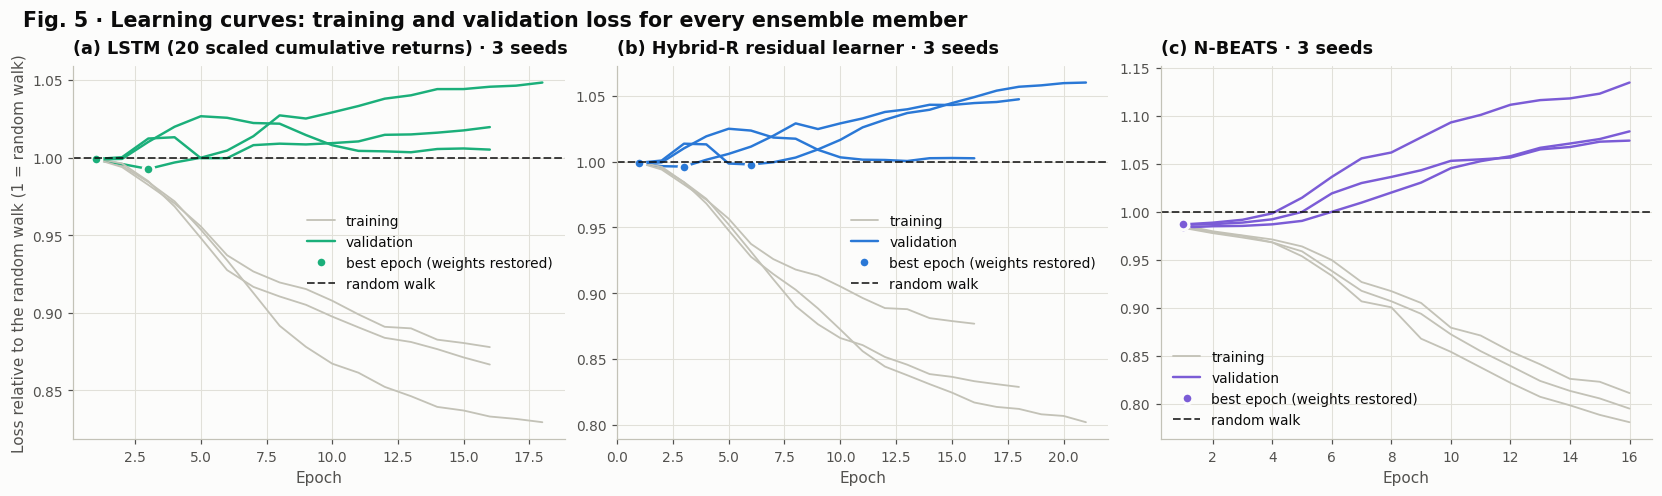

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, histories, model_name, title in [
        (axes[0], ctx.lstm_histories, "LSTM", "(a) LSTM (20 scaled cumulative returns)"),
        (axes[1], ctx.residual_histories, "Hybrid-R", "(b) Hybrid-R residual learner"),
        (axes[2], ctx.nbeats_histories, "N-BEATS", "(c) N-BEATS")]:
    for k, hist in enumerate(histories):
        epochs = np.arange(1, len(hist["loss"]) + 1)
        train_ratio = np.asarray(hist["loss"]) / hist["rw_loss"]
        val_ratio = np.asarray(hist["val_loss"]) / hist["rw_val_loss"]
        best = int(np.argmin(val_ratio))
        ax.plot(epochs, train_ratio, color=AXIS, lw=1.2, label="training" if k == 0 else None)
        ax.plot(epochs, val_ratio, color=COLORS[model_name], lw=1.6, label="validation" if k == 0 else None)
        ax.plot(epochs[best], val_ratio[best], "o", ms=7, color=COLORS[model_name], mec=SURFACE, mew=2,
                label="best epoch (weights restored)" if k == 0 else None)
    ax.axhline(1.0, color=INK, lw=1.0, linestyle=(0, (5, 2)), label="random walk")
    ax.set_title(f"{title} · {len(histories)} seeds")
    ax.set_xlabel("Epoch")
    ax.legend(loc="best")
axes[0].set_ylabel("Loss relative to the random walk (1 = random walk)")
finish(fig, 5, "Learning curves: training and validation loss for every ensemble member", "learning_curves")

**Reading Fig. 5.** Every network starts at the random walk (ratio 1). The training curves fall below 1 as the networks fit the training years. The validation curves show how much of that carries over to unseen years: on market data they stay close to 1, dip slightly below it for a few epochs at best, and then rise as the networks start to memorise noise. Early stopping restores the weights at the validation minimum (the dots), so a network that finds nothing useful stays close to the random walk instead of producing noise. Validation curves that barely go below 1 are a genuine finding, consistent with the efficient-market hypothesis: there is little stable structure in daily returns for a network to learn.

### 12.2 Hybrid-E: optimal per-horizon ensemble
Combining forecasts with error-minimising weights is one of the most robust results in forecasting (Bates & Granger, 1969). For each lead $h$ a convex weight is estimated **on the validation years**:

$$\hat y^{\,\text{HE}}_{t+h} = w_h\,\hat y^{\,\text{SARIMA}}_{t+h} + (1-w_h)\,\hat y^{\,\text{LSTM}}_{t+h},\qquad
w_h=\operatorname{clip}_{[0,1]}\frac{\sum (\hat y^{L}-y)(\hat y^{L}-\hat y^{S})}{\sum(\hat y^{L}-\hat y^{S})^2},$$

the closed-form minimiser of the validation MSE. Because both forecasts start from the same price, the weights are identical whether they are computed on log prices or on returns.

In [26]:
def optimal_weights(S, L, Y):
    d = L - S
    return np.clip(np.sum((L - Y[:, None]) * d, axis=0) / np.maximum(np.sum(d * d, axis=0), 1e-18), 0.0, 1.0)

def fit_hybrid_e(c):
    c.w_sarima = optimal_weights(c.FC["SARIMA"]["val"], c.FC["LSTM"]["val"], c.p[c.val_targets])
    c.FC["Hybrid-E"] = {split: c.w_sarima * c.FC["SARIMA"][split] + (1 - c.w_sarima) * c.FC["LSTM"][split]
                        for split in ("val", "test", "future")}

fit_hybrid_e(ctx)
COST_LOG["Hybrid-E"] = {"Parameters": COST_LOG["SARIMA"]["Parameters"] + COST_LOG["LSTM"]["Parameters"] + H,
                        "Wall-clock time (s)": COST_LOG["SARIMA"]["Wall-clock time (s)"] + COST_LOG["LSTM"]["Wall-clock time (s)"]}
print("Weight on SARIMA by lead: " + ", ".join(f"h={h}: {ctx.w_sarima[h - 1]:.2f}" for h in LEAD_CHECKPOINTS))
for name in MODEL_ORDER:
    actual, predicted = model_returns(ctx, name, 1)
    print(f"{name:<12} day-ahead return RMSE {100 * np.sqrt(np.mean((actual - predicted) ** 2)):.4f} %")

Weight on SARIMA by lead: h=1: 0.00, h=2: 0.00, h=5: 0.00, h=10: 0.00, h=20: 0.24
Random walk  day-ahead return RMSE 0.8733 %
Drift        day-ahead return RMSE 0.8727 %
ARIMA        day-ahead return RMSE 0.8799 %
SARIMA       day-ahead return RMSE 0.8724 %
LSTM         day-ahead return RMSE 0.8726 %
N-BEATS      day-ahead return RMSE 0.8721 %
Hybrid-R     day-ahead return RMSE 0.8717 %
Hybrid-E     day-ahead return RMSE 0.8726 %


## 13 · Evaluation on the untouched test period (2022 to 2026)

### 13.1 Price-level accuracy (h = 1)
The familiar error measures on the price itself. As explained in Section 6, they are dominated by persistence: every sensible model has an $R^2$ above 0.99, so this table shows that the forecasts are well-behaved but cannot show which model is better.

In [27]:
price_table = pd.DataFrame({name: price_metrics(ctx.p[ctx.test_targets], ctx.FC[name]["test"][:, 0]) for name in MODEL_ORDER}).T
price_table.insert(0, "Family", [FAMILY[m] for m in price_table.index])
show_table(price_table, 13, f"Day-ahead price accuracy over all {len(ctx.test_targets):,} test days ({PRIMARY_ASSET}, index points)",
           fmt={"Price RMSE": "{:.2f}", "Price MAE": "{:.2f}", "Price MAPE (%)": "{:.3f}", "Price R²": "{:.5f}"},
           low=["Price RMSE", "Price MAE", "Price MAPE (%)"], high=["Price R²"])

,Family,Price RMSE,Price MAE,Price MAPE (%),Price R²
Random walk,Baseline,185.33,135.41,0.638,0.99664
Drift,Baseline,185.26,135.25,0.637,0.99664
ARIMA,Statistical,186.90,136.08,0.640,0.99658
SARIMA,Statistical,185.15,135.19,0.637,0.99665
LSTM,Deep learning,185.20,135.34,0.638,0.99664
N-BEATS,Deep learning,185.09,135.19,0.637,0.99665
Hybrid-R,Hybrid,185.06,135.19,0.637,0.99665
Hybrid-E,Hybrid,185.20,135.34,0.638,0.99664


### 13.2 Return-level accuracy and direction (h = 1)
The decisive comparison. $R^2_{OS}$ above 0 means a model beats the random walk; a directional accuracy above 50 % with a small Pesaran-Timmermann p-value means it predicts the sign of the next move better than chance. The return RMSE is reported with a 95 % confidence interval from a **moving-block bootstrap** (Künsch, 1989): the test days are resampled in blocks of `BOOT_BLOCK` consecutive trading days, which preserves volatility clustering, the RMSE is recomputed `N_BOOT` times, and the 2.5 % and 97.5 % quantiles form the interval. The intervals of different models overlap heavily because all models face the same unpredictable market moves; the paired comparisons in Sections 13.3 and 13.4 account for this.

In [28]:
def return_table_for(c, h=1):
    return pd.DataFrame({name: return_metrics(*model_returns(c, name, h)) for name in MODEL_ORDER}).T

RETURN_FMT = {"Return RMSE (%)": "{:.4f}", "Return MAE (%)": "{:.4f}", "R²_OS vs random walk (%)": "{:+.2f}",
              "Directional accuracy (%)": "{:.2f}", "Pesaran-Timmermann p": "{:.4f}"}
def block_bootstrap_indices(n, n_boot=N_BOOT, block=BOOT_BLOCK, seed=SEED):
    rng = np.random.default_rng(seed)
    starts = rng.integers(0, n - block + 1, size=(n_boot, int(np.ceil(n / block))))
    return (starts[:, :, None] + np.arange(block)[None, None, :]).reshape(n_boot, -1)[:, :n]

def rmse_interval(errors, idx):
    return np.percentile(np.sqrt(np.mean(errors[idx] ** 2, axis=1)), [2.5, 97.5])

BOOT = block_bootstrap_indices(len(ctx.test_targets))
day_ahead = return_table_for(ctx)
day_ahead.insert(0, "Family", [FAMILY[m] for m in day_ahead.index])
day_ahead.insert(2, "Return RMSE 95 % CI (%)", [" to ".join(f"{100 * v:.4f}" for v in rmse_interval(np.subtract(*model_returns(ctx, m, 1)), BOOT))
                                                for m in day_ahead.index])
show_table(day_ahead, 14, f"Day-ahead return accuracy and direction over all {len(ctx.test_targets):,} test days",
           fmt=RETURN_FMT, low=["Return RMSE (%)", "Return MAE (%)"], high=["R²_OS vs random walk (%)", "Directional accuracy (%)"])

,Family,Return RMSE (%),Return RMSE 95 % CI (%),Return MAE (%),R²_OS vs random walk (%),Directional accuracy (%),Pesaran-Timmermann p
Random walk,Baseline,0.8733,0.7831 to 0.9568,0.6379,+0.00,n/a,n/a
Drift,Baseline,0.8727,0.7823 to 0.9578,0.6370,+0.12,52.46,n/a
ARIMA,Statistical,0.8799,0.7847 to 0.9679,0.6403,-1.51,51.55,0.2826
SARIMA,Statistical,0.8724,0.7815 to 0.9576,0.6368,+0.20,52.55,0.3212
LSTM,Deep learning,0.8726,0.7828 to 0.9568,0.6376,+0.16,52.46,n/a
N-BEATS,Deep learning,0.8721,0.7815 to 0.9561,0.6368,+0.28,52.46,n/a
Hybrid-R,Hybrid,0.8717,0.7816 to 0.9553,0.6367,+0.35,53.22,0.0008
Hybrid-E,Hybrid,0.8726,0.7828 to 0.9568,0.6376,+0.16,52.46,n/a


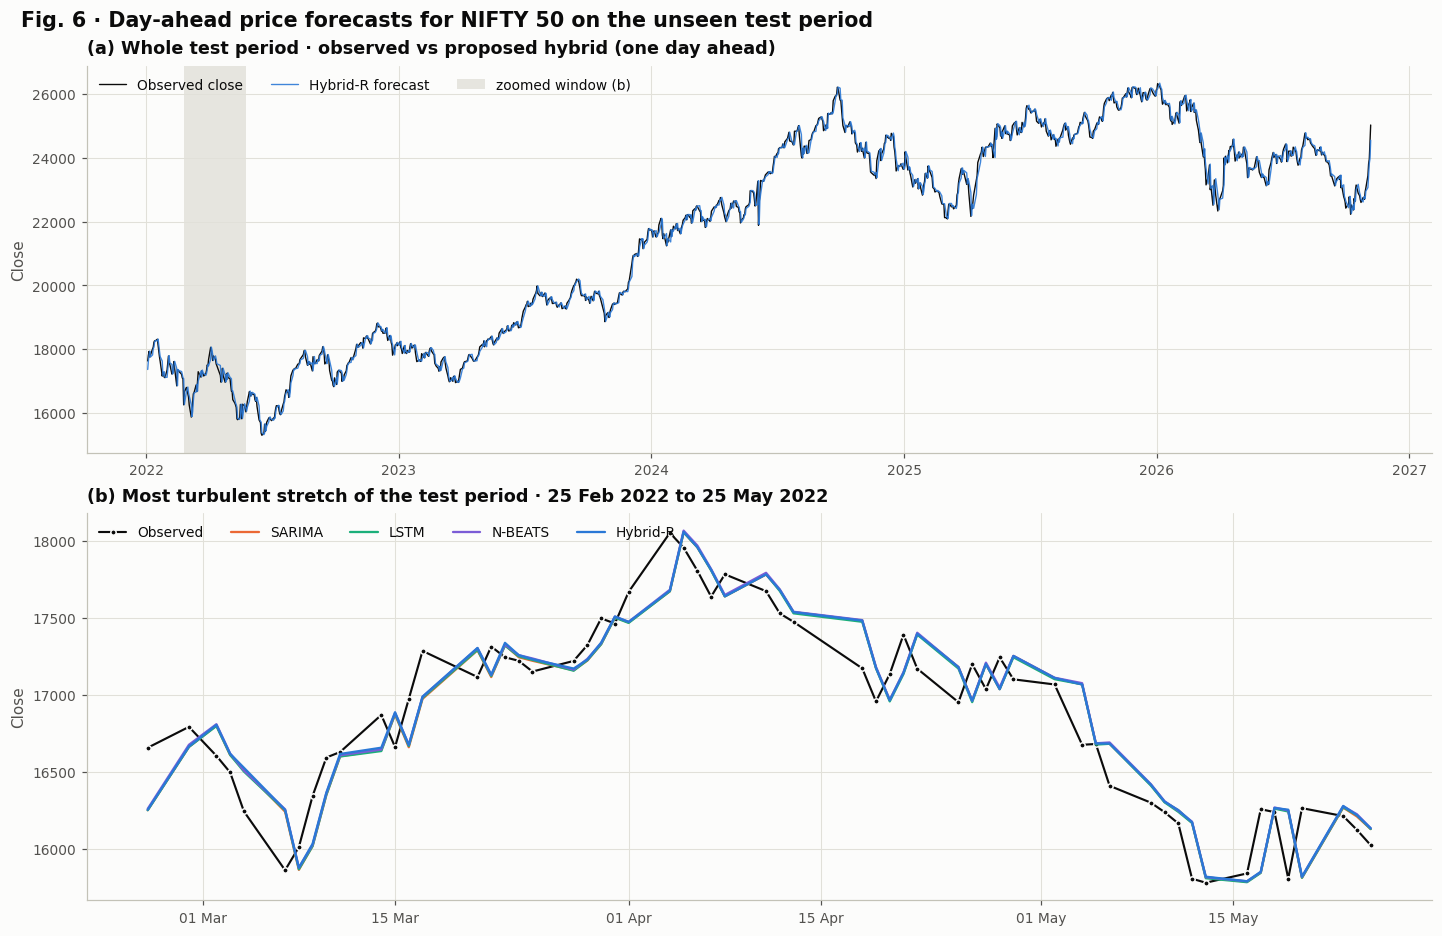

In [29]:
actual_logp = ctx.p[ctx.test_targets]
test_dates = ctx.test_dates
moves = pd.Series(np.abs(np.diff(actual_logp, prepend=actual_logp[0])), index=test_dates).rolling(60).sum()
zoom_end = moves.idxmax()
zoom = (test_dates > zoom_end - pd.Timedelta(days=90)) & (test_dates <= zoom_end)
fig, axes = plt.subplots(2, 1, figsize=(13, 8.4))
ax = axes[0]
ax.plot(test_dates, np.exp(actual_logp), color=INK, lw=0.9, label="Observed close")
ax.plot(test_dates, np.exp(ctx.FC["Hybrid-R"]["test"][:, 0]), color=COLORS["Hybrid-R"], lw=0.9, alpha=0.9, label="Hybrid-R forecast")
ax.axvspan(test_dates[zoom][0], test_dates[zoom][-1], color=GRID, alpha=0.8, lw=0, label="zoomed window (b)")
ax.set_title("(a) Whole test period · observed vs proposed hybrid (one day ahead)")
ax.set_ylabel("Close")
ax.legend(loc="upper left", ncol=3)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax = axes[1]
ax.plot(test_dates[zoom], np.exp(actual_logp[zoom]), color=INK, lw=1.4, marker="o", ms=3.5, mec=SURFACE, mew=1, label="Observed")
for name in ["SARIMA", "LSTM", "N-BEATS", "Hybrid-R"]:
    ax.plot(test_dates[zoom], np.exp(ctx.FC[name]["test"][zoom, 0]), color=COLORS[name], lw=1.5, label=name)
ax.set_title(f"(b) Most turbulent stretch of the test period · {test_dates[zoom][0]:%d %b %Y} to {test_dates[zoom][-1]:%d %b %Y}")
ax.set_ylabel("Close")
ax.legend(loc="upper left", ncol=5)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
finish(fig, 6, f"Day-ahead price forecasts for {PRIMARY_ASSET} on the unseen test period", "test_forecasts")

**Reading Fig. 6.** One day ahead, every forecast lies on top of the observed price, and in the zoomed panel each forecast curve looks like the observed curve shifted one day to the right. This is not a plotting error: it is what an efficient market looks like. The best forecast of tomorrow's price is very close to today's price, so all models largely inherit today's close and can only add a small, mostly unpredictable correction. Visual closeness is therefore not evidence of skill; the return-level tests in Tables 14 and 15 are.

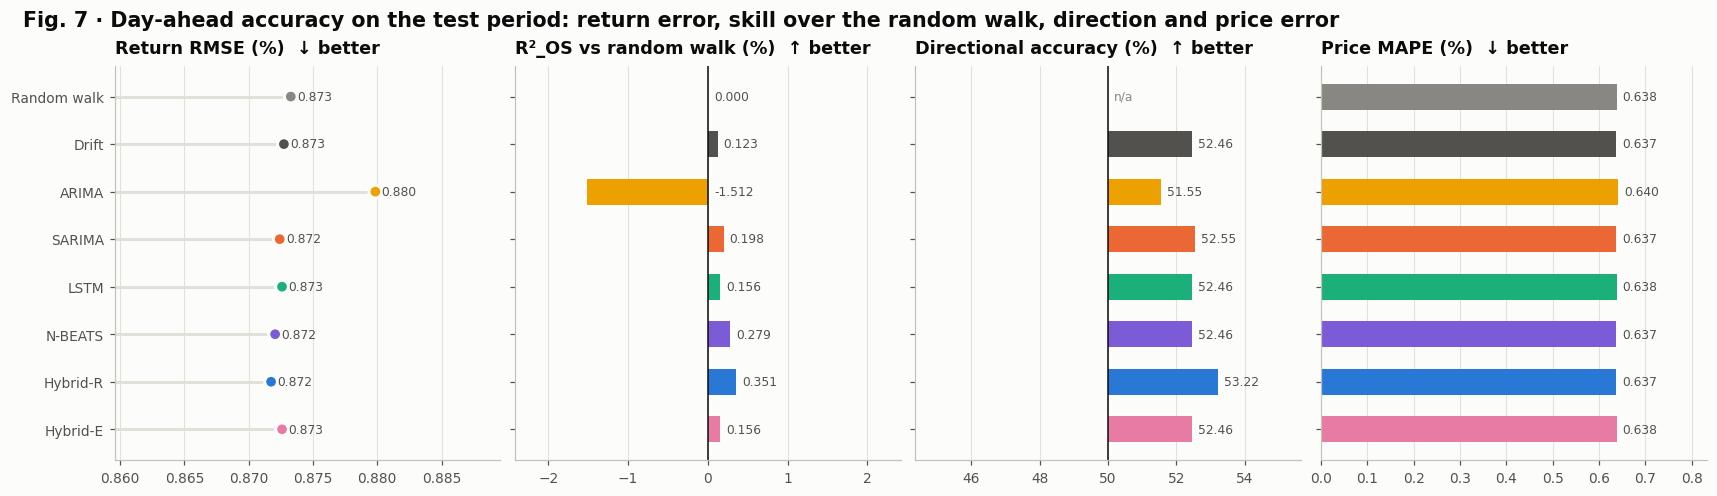

In [30]:
fig, axes = plt.subplots(1, 4, figsize=(15.5, 4.4), sharey=True)
order = MODEL_ORDER[::-1]
ypos = np.arange(len(order))
panels = [("Return RMSE (%)", "↓ better"), ("R²_OS vs random walk (%)", "↑ better"), ("Directional accuracy (%)", "↑ better"),
          ("Price MAPE (%)", "↓ better")]
combined = day_ahead.join(price_table[["Price MAPE (%)"]])
for ax, (metric, note) in zip(axes, panels):
    values = combined.loc[order, metric].astype(float).to_numpy()
    shown = np.nan_to_num(values, nan=0.0)
    if metric == "Directional accuracy (%)":
        shown = np.where(np.isfinite(values), values, 50.0)
    if metric == "Return RMSE (%)":
        span = values.max() - values.min()
        left = values.min() - max(span, 1e-4) * 1.5
        ax.hlines(ypos, left, values, color=GRID, lw=2)
        ax.scatter(values, ypos, s=70, c=[COLORS[m] for m in order], edgecolors=SURFACE, linewidths=2, zorder=3)
        ax.set_xlim(left, values.max() + max(span, 1e-4) * 1.2)
    elif metric == "Directional accuracy (%)":
        ax.barh(ypos, shown - 50, left=50, height=0.55, color=[COLORS[m] for m in order])
        ax.axvline(50, color=INK, lw=1)
        spread = np.nanmax(np.abs(values - 50)) if np.isfinite(values).any() else 1
        ax.set_xlim(50 - spread * 1.6 - 0.5, 50 + spread * 1.6 + 0.5)
    elif metric == "R²_OS vs random walk (%)":
        ax.barh(ypos, shown, height=0.55, color=[COLORS[m] for m in order])
        ax.axvline(0, color=INK, lw=1)
        spread = np.nanmax(np.abs(shown)) if np.nanmax(np.abs(shown)) > 0 else 1
        ax.set_xlim(-spread * 1.6, spread * 1.6)
    else:
        ax.barh(ypos, shown, height=0.55, color=[COLORS[m] for m in order])
        ax.set_xlim(0, values.max() * 1.3)
    for yi, v in zip(ypos, values):
        if np.isfinite(v):
            ax.annotate(f"{v:.3f}" if abs(v) < 10 else f"{v:.2f}", (v if metric != "R²_OS vs random walk (%)" else max(v, 0), yi),
                        xytext=(4, 0), textcoords="offset points", va="center", fontsize=8, color=INK_2)
        else:
            ax.annotate("n/a", (50 if metric == "Directional accuracy (%)" else 0, yi), xytext=(4, 0), textcoords="offset points",
                        va="center", fontsize=8, color=MUTED)
    ax.set_title(f"{metric}  {note}")
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(ypos, order)
finish(fig, 7, "Day-ahead accuracy on the test period: return error, skill over the random walk, direction and price error",
       "metric_comparison")

### 13.3 Is the difference real? Diebold-Mariano tests

The Diebold-Mariano test (1995) with the Harvey-Leybourne-Newbold (1997) correction checks whether two models' squared return errors differ systematically. Its null hypothesis is equal accuracy; a negative statistic means Hybrid-R is the more accurate model.

In [31]:
def diebold_mariano(e1, e2, h=1):
    d = e1 ** 2 - e2 ** 2
    T, d_bar = len(d), d.mean()
    autocov = [np.sum((d[k:] - d_bar) * (d[:T - k] - d_bar)) / T for k in range(h)]
    variance = max((autocov[0] + 2 * sum(autocov[1:])) / T, 1e-30)
    statistic = d_bar / np.sqrt(variance) * np.sqrt((T + 1 - 2 * h + h * (h - 1) / T) / T)
    return statistic, 2 * stats.t.sf(abs(statistic), df=T - 1)

def dm_table_for(c, reference="Hybrid-R", leads=(1, 5)):
    rows = {}
    for other in [m for m in MODEL_ORDER if m != reference]:
        row = {}
        for h in leads:
            actual, ref_pred = model_returns(c, reference, h)
            _, other_pred = model_returns(c, other, h)
            stat, p = diebold_mariano(actual - ref_pred, actual - other_pred, h)
            row[f"DM (h={h})"], row[f"p (h={h})"] = stat, p
        stat, p = row["DM (h=1)"], row["p (h=1)"]
        row["Day-ahead verdict"] = (f"{reference} significantly better" if p < 0.05 and stat < 0 else
                                    f"{reference} significantly worse" if p < 0.05 else "no significant difference")
        rows[other] = row
    return pd.DataFrame(rows).T

dm_table = dm_table_for(ctx)
show_table(dm_table, 15, "Diebold-Mariano tests of Hybrid-R against every other model (squared return errors, 5 % level)",
           fmt={c: ("{:+.2f}" if c.startswith("DM") else "{:.4f}") for c in dm_table.columns if c != "Day-ahead verdict"})

,DM (h=1),p (h=1),DM (h=5),p (h=5),Day-ahead verdict
Random walk,-0.80,0.4216,-0.62,0.5339,no significant difference
Drift,-0.82,0.4119,-0.78,0.4361,no significant difference
ARIMA,-1.96,0.0497,-1.45,0.1461,Hybrid-R significantly better
SARIMA,-0.66,0.5084,-1.06,0.2893,no significant difference
LSTM,-0.55,0.5796,+0.07,0.9455,no significant difference
N-BEATS,-0.38,0.7034,+0.39,0.6981,no significant difference
Hybrid-E,-0.55,0.5796,+0.07,0.9455,no significant difference


### 13.4 How much better? Improvement of the hybrids over every competitor
The headline comparison, answered with uncertainty. For a proposed model $P$ and a competitor $C$ the improvement in day-ahead return error is

$$\text{Improvement}(\%) = 100\left(1 - \frac{\text{RMSE}_P}{\text{RMSE}_C}\right),$$

so **+1 % means that the proposed model's return error is 1 % smaller** and a negative value means it is larger. Because daily returns are almost unpredictable, improvements of a fraction of a percent are typical for stock markets; they matter only when the 95 % interval excludes zero. The interval comes from the same block bootstrap as Section 13.2, applied to both models on the *same* resampled days. The Diebold-Mariano p-values are corrected for comparing against seven competitors at once with the **Holm (1979)** step-down procedure. The table also reports the MAE reduction, the gain in directional accuracy in percentage points and the RMSE reduction averaged over all 20 leads.

In [32]:
def holm_adjust(pvalues):
    names = list(pvalues)
    p = np.array([pvalues[k] for k in names], dtype=float)
    adjusted, running = np.empty(len(p)), 0.0
    for rank, i in enumerate(np.argsort(p)):
        running = max(running, min(1.0, (len(p) - rank) * p[i]))
        adjusted[i] = running
    return dict(zip(names, adjusted))

def improvement_table(c, proposed, idx):
    actual, pred_p = model_returns(c, proposed, 1)
    e_p = actual - pred_p
    lead_rmse = {name: np.mean([np.sqrt(np.mean(np.subtract(*model_returns(c, name, h)) ** 2)) for h in LEADS]) for name in MODEL_ORDER}
    direction_p = return_metrics(actual, pred_p)["Directional accuracy (%)"]
    rows, pvalues = {}, {}
    for other in [m for m in MODEL_ORDER if m != proposed]:
        pred_o = model_returns(c, other, 1)[1]
        e_o = actual - pred_o
        boot = 100 * (1 - np.sqrt(np.mean(e_p[idx] ** 2, axis=1)) / np.sqrt(np.mean(e_o[idx] ** 2, axis=1)))
        low, high = np.percentile(boot, [2.5, 97.5])
        pvalues[other] = diebold_mariano(e_p, e_o, 1)[1]
        rows[other] = {"Return RMSE reduction h = 1 (%)": 100 * (1 - np.sqrt(np.mean(e_p ** 2)) / np.sqrt(np.mean(e_o ** 2))),
                       "95 % CI low": low, "95 % CI high": high,
                       "Return MAE reduction h = 1 (%)": 100 * (1 - np.mean(np.abs(e_p)) / np.mean(np.abs(e_o))),
                       "Direction gain h = 1 (points)": direction_p - return_metrics(actual, pred_o)["Directional accuracy (%)"],
                       f"Return RMSE reduction, mean of leads 1 to {H} (%)": 100 * (1 - lead_rmse[proposed] / lead_rmse[other]),
                       "DM p (h = 1)": pvalues[other]}
    table = pd.DataFrame(rows).T
    holm = holm_adjust(pvalues)
    table["Holm-adjusted p"] = [holm[m] for m in table.index]
    table["Verdict (5 %, Holm)"] = ["significantly better" if p < 0.05 and g > 0 else "significantly worse" if p < 0.05
                                    else "no significant difference"
                                    for p, g in zip(table["Holm-adjusted p"], table["Return RMSE reduction h = 1 (%)"])]
    return table

IMPROVEMENT_FMT = {"Return RMSE reduction h = 1 (%)": "{:+.3f}", "95 % CI low": "{:+.3f}", "95 % CI high": "{:+.3f}",
                   "Return MAE reduction h = 1 (%)": "{:+.3f}", "Direction gain h = 1 (points)": "{:+.2f}",
                   f"Return RMSE reduction, mean of leads 1 to {H} (%)": "{:+.3f}", "DM p (h = 1)": "{:.4f}", "Holm-adjusted p": "{:.4f}"}
improvement = {name: improvement_table(ctx, name, BOOT) for name in ("Hybrid-R", "Hybrid-E")}
show_table(improvement["Hybrid-R"], 16, "How much better is the proposed Hybrid-R? Day-ahead return error reduction against every other model "
           "(positive = Hybrid-R better; 95 % paired block-bootstrap interval; Holm-corrected Diebold-Mariano test)", fmt=IMPROVEMENT_FMT)
show_table(improvement["Hybrid-E"], 17, "How much better is Hybrid-E? Day-ahead return error reduction against every other model "
           "(positive = Hybrid-E better; 95 % paired block-bootstrap interval; Holm-corrected Diebold-Mariano test)", fmt=IMPROVEMENT_FMT)

,Return RMSE reduction h = 1 (%),95 % CI low,95 % CI high,Return MAE reduction h = 1 (%),Direction gain h = 1 (points),"Return RMSE reduction, mean of leads 1 to 20 (%)",DM p (h = 1),Holm-adjusted p,"Verdict (5 %, Holm)"
Random walk,+0.176,-0.248,+0.580,+0.195,n/a,+0.673,0.4216,1.0000,no significant difference
Drift,+0.114,-0.145,+0.370,+0.052,+0.75,+0.128,0.4119,1.0000,no significant difference
ARIMA,+0.922,+0.110,+1.722,+0.565,+1.67,+0.126,0.0497,0.3480,no significant difference
SARIMA,+0.077,-0.151,+0.272,+0.016,+0.67,+0.097,0.5084,1.0000,no significant difference
LSTM,+0.098,-0.241,+0.414,+0.141,+0.75,-0.066,0.5796,1.0000,no significant difference
N-BEATS,+0.036,-0.123,+0.226,+0.030,+0.75,-0.252,0.7034,1.0000,no significant difference
Hybrid-E,+0.098,-0.241,+0.414,+0.141,+0.75,-0.089,0.5796,1.0000,no significant difference


,Return RMSE reduction h = 1 (%),95 % CI low,95 % CI high,Return MAE reduction h = 1 (%),Direction gain h = 1 (points),"Return RMSE reduction, mean of leads 1 to 20 (%)",DM p (h = 1),Holm-adjusted p,"Verdict (5 %, Holm)"
Random walk,+0.078,-0.026,+0.169,+0.054,n/a,+0.761,0.1312,0.7872,no significant difference
Drift,+0.017,-0.116,+0.168,-0.090,+0.00,+0.217,0.8129,1.0000,no significant difference
ARIMA,+0.825,+0.100,+1.582,+0.424,+0.92,+0.215,0.0670,0.4689,no significant difference
SARIMA,-0.021,-0.208,+0.132,-0.126,-0.08,+0.186,0.8256,1.0000,no significant difference
LSTM,+0.000,+0.000,+0.000,+0.000,+0.00,+0.023,1.0000,1.0000,no significant difference
N-BEATS,-0.062,-0.309,+0.196,-0.111,+0.00,-0.163,0.6387,1.0000,no significant difference
Hybrid-R,-0.098,-0.416,+0.241,-0.142,-0.75,+0.089,0.5796,1.0000,no significant difference


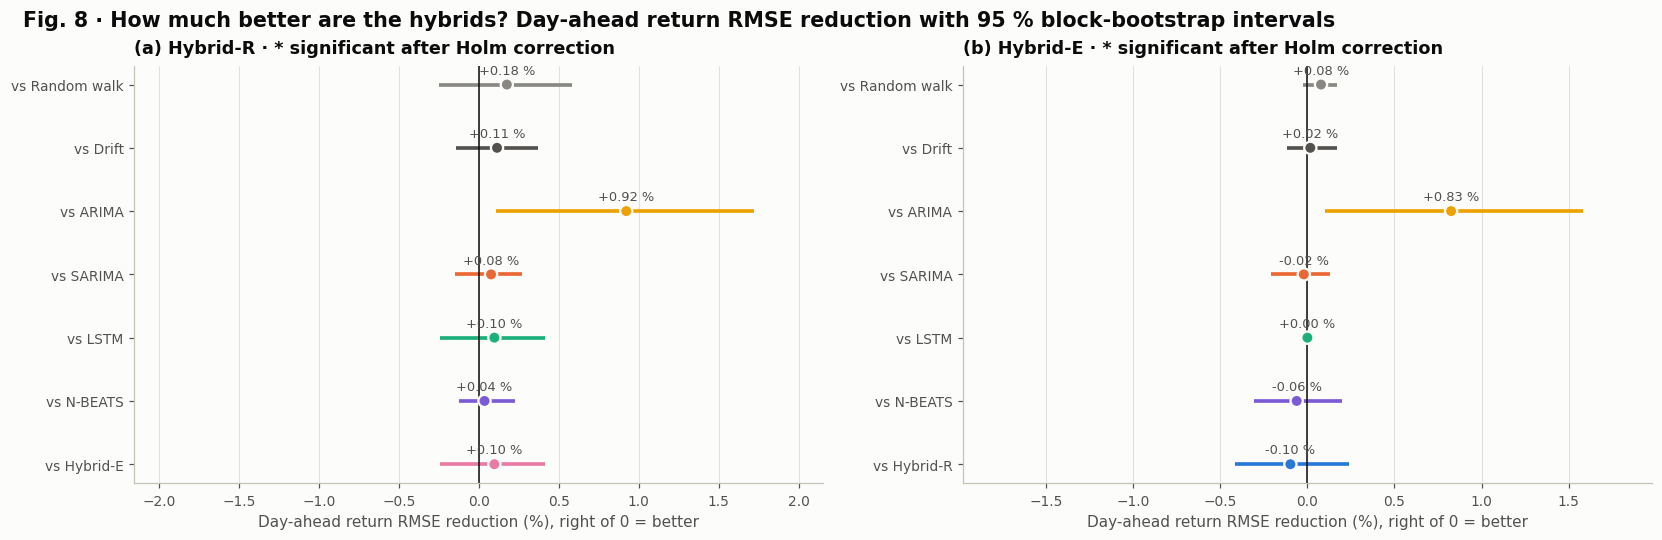

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for panel, (ax, name) in enumerate(zip(axes, ("Hybrid-R", "Hybrid-E"))):
    table = improvement[name].iloc[::-1]
    ypos = np.arange(len(table))
    gain = table["Return RMSE reduction h = 1 (%)"].to_numpy(dtype=float)
    low, high = table["95 % CI low"].to_numpy(dtype=float), table["95 % CI high"].to_numpy(dtype=float)
    colors = [COLORS[m] for m in table.index]
    ax.hlines(ypos, low, high, colors=colors, lw=2.4)
    ax.scatter(gain, ypos, s=64, c=colors, edgecolors=SURFACE, linewidths=1.5, zorder=3)
    ax.axvline(0, color=INK, lw=1)
    for y, g, verdict in zip(ypos, gain, table["Verdict (5 %, Holm)"]):
        ax.annotate(f"{g:+.2f} %{' *' if verdict != 'no significant difference' else ''}", (g, y), xytext=(0, 7),
                    textcoords="offset points", ha="center", fontsize=8.5, color=INK_2)
    span = max(float(np.nanmax(np.abs(np.r_[low, high]))), 0.05)
    ax.set_xlim(-1.25 * span, 1.25 * span)
    ax.set_yticks(ypos, [f"vs {m}" for m in table.index])
    ax.set_xlabel("Day-ahead return RMSE reduction (%), right of 0 = better")
    ax.set_title(f"({'ab'[panel]}) {name} · * significant after Holm correction")
    ax.grid(axis="y", visible=False)
finish(fig, 8, "How much better are the hybrids? Day-ahead return RMSE reduction with 95 % block-bootstrap intervals",
       "improvement_forest")

**Reading Tables 16 and 17 and Fig. 8.** Each row answers one question: *how much smaller is the proposed model's return error than this competitor's?* An interval that lies entirely to the right of zero means the improvement does not depend on which test days happen to be included, and a significant Holm-adjusted p-value means it survives the correction for multiple comparisons. The comparison with the random walk is the efficient-market test; the comparison with SARIMA shows what the neural correction adds to the linear model. Small gains with intervals that straddle zero are the honest, expected outcome for daily stock returns.

### 13.5 How does skill change with the horizon?
Fig. 9 follows every model from 1 to 20 trading days ahead on the same test days. Panel (a) shows $R^2_{OS}$, the skill over the random walk for the cumulative return; panel (b) the directional accuracy; panel (c) how much weight the hybrids give the LSTM at each lead. Over longer horizons, slow-moving effects such as momentum and the market's positive drift become relatively more important than daily noise, so skill may change with the lead.

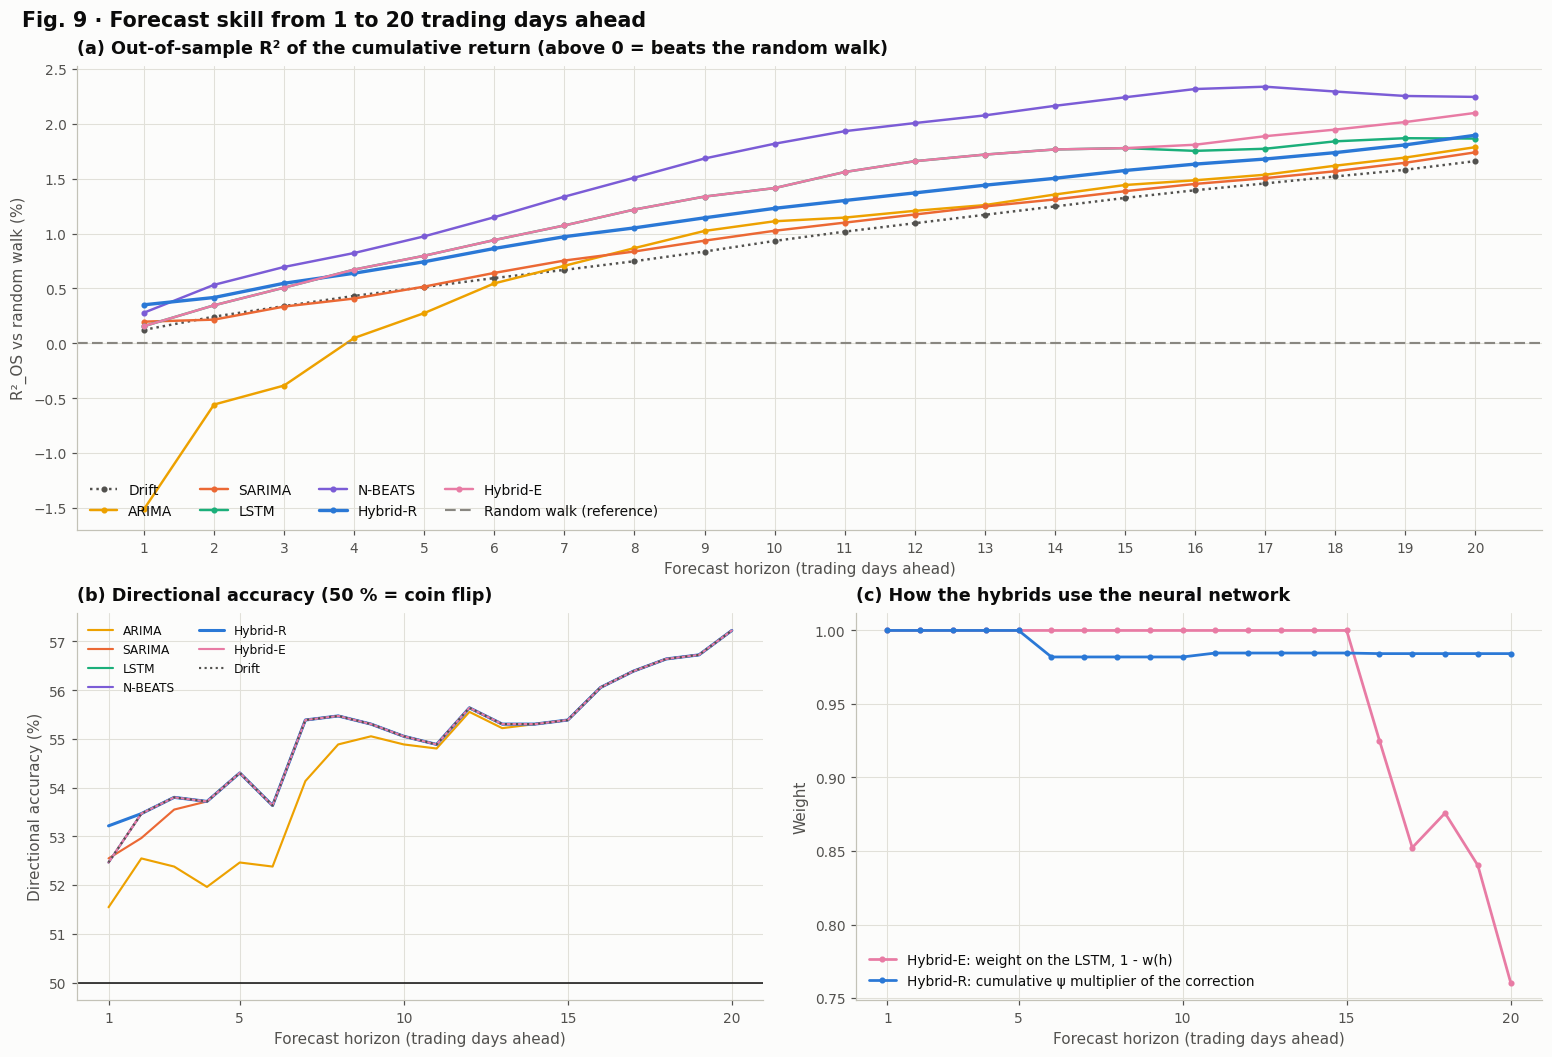

,h = 1,h = 2,h = 5,h = 10,h = 20,Mean 1 to 20
Random walk,+0.00,+0.00,+0.00,+0.00,+0.00,+0.00
Drift,+0.12,+0.24,+0.51,+0.93,+1.66,+0.95
ARIMA,-1.51,-0.56,+0.28,+1.11,+1.79,+0.83
SARIMA,+0.20,+0.22,+0.52,+1.03,+1.74,+1.00
LSTM,+0.16,+0.35,+0.80,+1.41,+1.87,+1.30
N-BEATS,+0.28,+0.53,+0.98,+1.82,+2.25,+1.63
Hybrid-R,+0.35,+0.42,+0.74,+1.23,+1.90,+1.20
Hybrid-E,+0.16,+0.35,+0.80,+1.41,+2.10,+1.34


,h = 1,h = 2,h = 5,h = 10,h = 20,Mean 1 to 20
Random walk,n/a,n/a,n/a,n/a,n/a,n/a
Drift,52.46,53.47,54.30,55.05,57.23,55.11
ARIMA,51.55,52.55,52.46,54.89,57.23,54.58
SARIMA,52.55,52.97,54.30,55.05,57.23,55.08
LSTM,52.46,53.47,54.30,55.05,57.23,55.11
N-BEATS,52.46,53.47,54.30,55.05,57.23,55.11
Hybrid-R,53.22,53.47,54.30,55.05,57.23,55.15
Hybrid-E,52.46,53.47,54.30,55.05,57.23,55.11


In [34]:
def horizon_tables(c):
    r2 = {name: [] for name in MODEL_ORDER}
    da = {name: [] for name in MODEL_ORDER}
    for h in LEADS:
        for name in MODEL_ORDER:
            m = return_metrics(*model_returns(c, name, h))
            r2[name].append(m["R²_OS vs random walk (%)"])
            da[name].append(m["Directional accuracy (%)"])
    return pd.DataFrame(r2, index=LEADS), pd.DataFrame(da, index=LEADS)

r2_h, da_h = horizon_tables(ctx)
fig = plt.figure(figsize=(14, 9.5))
grid = fig.add_gridspec(2, 2, height_ratios=[1.2, 1])
ax = fig.add_subplot(grid[0, :])
for name in MODEL_ORDER:
    if name == "Random walk":
        continue
    ax.plot(LEADS, r2_h[name], color=COLORS[name], lw=2.2 if name == "Hybrid-R" else 1.6, marker="o", ms=3,
            linestyle=LINESTYLES.get(name, "-"), label=name)
ax.axhline(0, color=MUTED, lw=1.4, linestyle=LINESTYLES["Random walk"], label="Random walk (reference)")
ax.set_xticks(LEADS)
ax.set_xlabel("Forecast horizon (trading days ahead)")
ax.set_ylabel("R²_OS vs random walk (%)")
ax.set_title("(a) Out-of-sample R² of the cumulative return (above 0 = beats the random walk)")
ax.legend(loc="lower left", ncol=4)
ax = fig.add_subplot(grid[1, 0])
for name in LEARNED + ["Drift"]:
    ax.plot(LEADS, da_h[name], color=COLORS[name], lw=2.0 if name == "Hybrid-R" else 1.4, linestyle=LINESTYLES.get(name, "-"), label=name)
ax.axhline(50, color=INK, lw=1)
ax.set_xticks([1, 5, 10, 15, 20])
ax.set_xlabel("Forecast horizon (trading days ahead)")
ax.set_ylabel("Directional accuracy (%)")
ax.set_title("(b) Directional accuracy (50 % = coin flip)")
ax.legend(loc="best", ncol=2, fontsize=8)
ax = fig.add_subplot(grid[1, 1])
ax.plot(LEADS, 1 - ctx.w_sarima, color=COLORS["Hybrid-E"], lw=1.8, marker="o", ms=3, label="Hybrid-E: weight on the LSTM, 1 - w(h)")
ax.plot(LEADS, ctx.cum_psi, color=COLORS["Hybrid-R"], lw=1.8, marker="o", ms=3, label="Hybrid-R: cumulative ψ multiplier of the correction")
ax.set_xticks([1, 5, 10, 15, 20])
ax.set_xlabel("Forecast horizon (trading days ahead)")
ax.set_ylabel("Weight")
ax.set_title("(c) How the hybrids use the neural network")
ax.legend(loc="best")
finish(fig, 9, f"Forecast skill from 1 to {H} trading days ahead", "horizon_analysis")

r2_table = r2_h.loc[list(LEAD_CHECKPOINTS)].T
r2_table.columns = [f"h = {h}" for h in LEAD_CHECKPOINTS]
r2_table[f"Mean 1 to {H}"] = r2_h.mean()
show_table(r2_table, 18, "Out-of-sample R² vs the random walk (%) by horizon", fmt="{:+.2f}", high=list(r2_table.columns))
da_table = da_h.loc[list(LEAD_CHECKPOINTS)].T
da_table.columns = [f"h = {h}" for h in LEAD_CHECKPOINTS]
da_table[f"Mean 1 to {H}"] = da_h.mean()
show_table(da_table, 19, "Directional accuracy (%) by horizon", fmt="{:.2f}", high=list(da_table.columns))

### 13.6 Economic value: a trading back-test
Statistical accuracy only matters if it can be used. Each model drives a simple, realistic **long-or-cash** rule: at every close, hold the asset for the next day if the forecast next-day return is positive, otherwise hold cash. Every change of position costs `COST` (0.05 %). The benchmark is **buy and hold**. Performance is measured by the compound annual growth rate (CAGR), annualised volatility, the **Sharpe ratio** (annualised mean over annualised volatility, with a zero risk-free rate for simplicity), the maximum drawdown (the worst peak-to-trough loss) and the share of days invested. The random walk forecasts no move and the drift model is always long, so they are represented by buy and hold.

,CAGR (%),Volatility (%),Sharpe ratio,Max drawdown (%),Final value of 1 unit,Days invested (%),Trades
Buy and hold,+8.00,13.84,0.626,-16.47,1.442,100.0,1
ARIMA,-1.69,10.82,-0.103,-26.11,0.922,65.3,601
SARIMA,+7.26,13.67,0.581,-17.64,1.395,97.2,65
LSTM,+8.00,13.84,0.626,-16.47,1.442,100.0,1
N-BEATS,+8.00,13.84,0.626,-16.47,1.442,100.0,1
Hybrid-R,+8.67,13.82,0.671,-15.77,1.485,99.2,19
Hybrid-E,+8.00,13.84,0.626,-16.47,1.442,100.0,1


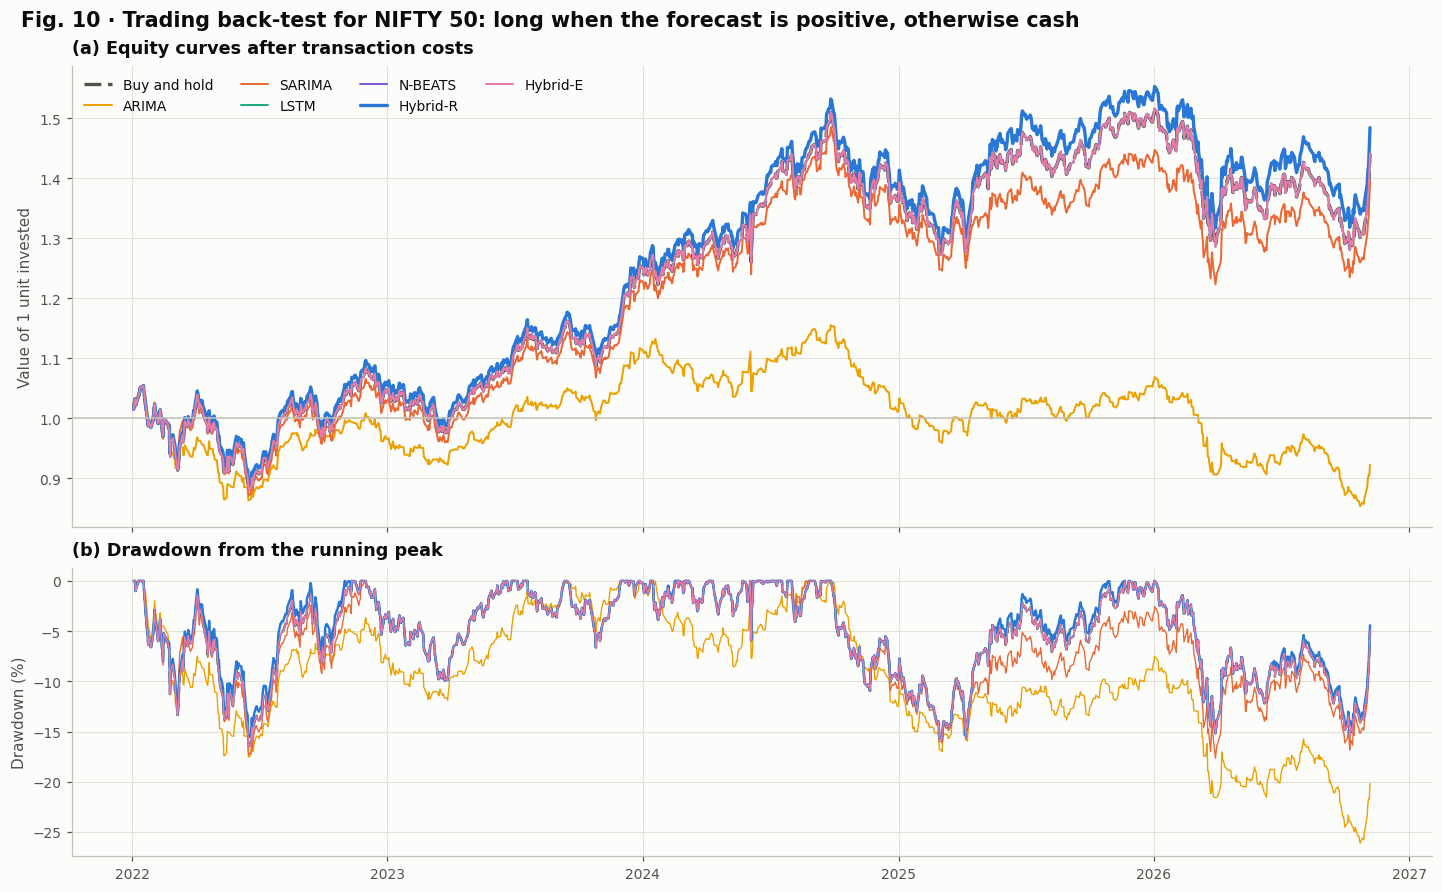

In [35]:
def strategy_returns(c, name):
    actual, predicted = model_returns(c, name, 1)
    position = (predicted > 0).astype(float)
    turnover = np.abs(np.diff(np.r_[0.0, position]))
    return position * np.expm1(actual) - COST * turnover, position

def performance(daily, position=None):
    equity = np.cumprod(1 + daily)
    years = len(daily) / TRADING_DAYS
    sd = daily.std()
    out = {"CAGR (%)": 100 * (equity[-1] ** (1 / years) - 1), "Volatility (%)": 100 * sd * np.sqrt(TRADING_DAYS),
           "Sharpe ratio": daily.mean() / sd * np.sqrt(TRADING_DAYS) if sd > 0 else np.nan,
           "Max drawdown (%)": 100 * (equity / np.maximum.accumulate(equity) - 1).min(), "Final value of 1 unit": equity[-1]}
    out["Days invested (%)"] = 100 * (position.mean() if position is not None else 1.0)
    out["Trades"] = int(np.abs(np.diff(np.r_[0.0, position])).sum()) if position is not None else 1
    return out

def backtest_for(c):
    buy_hold = np.expm1(actual_returns(c, c.test_targets, 1))
    buy_hold[0] -= COST
    results, curves = {"Buy and hold": performance(buy_hold)}, {"Buy and hold": np.cumprod(1 + buy_hold)}
    for name in LEARNED:
        daily, position = strategy_returns(c, name)
        results[name] = performance(daily, position)
        curves[name] = np.cumprod(1 + daily)
    return pd.DataFrame(results).T, curves

backtest_table, equity_curves = backtest_for(ctx)
show_table(backtest_table, 20, f"Long-or-cash trading back-test on the test period, after {100 * COST:.2f} % costs per trade",
           fmt={"CAGR (%)": "{:+.2f}", "Volatility (%)": "{:.2f}", "Sharpe ratio": "{:.3f}", "Max drawdown (%)": "{:.2f}",
                "Final value of 1 unit": "{:.3f}", "Days invested (%)": "{:.1f}", "Trades": "{:,.0f}"},
           high=["CAGR (%)", "Sharpe ratio", "Max drawdown (%)", "Final value of 1 unit"])

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True, gridspec_kw={"height_ratios": [1.6, 1]})
for name, curve in equity_curves.items():
    axes[0].plot(test_dates, curve, color=COLORS[name], lw=2.2 if name in ("Hybrid-R", "Buy and hold") else 1.3,
                 linestyle=LINESTYLES.get(name, "-"), label=name)
    axes[1].plot(test_dates, 100 * (curve / np.maximum.accumulate(curve) - 1), color=COLORS[name],
                 lw=1.6 if name in ("Hybrid-R", "Buy and hold") else 0.9, linestyle=LINESTYLES.get(name, "-"))
axes[0].axhline(1, color=AXIS, lw=1)
axes[0].set_ylabel("Value of 1 unit invested")
axes[0].set_title("(a) Equity curves after transaction costs")
axes[0].legend(loc="upper left", ncol=4)
axes[1].set_ylabel("Drawdown (%)")
axes[1].set_title("(b) Drawdown from the running peak")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
finish(fig, 10, f"Trading back-test for {PRIMARY_ASSET}: long when the forecast is positive, otherwise cash", "backtest")

**Reading Table 20 and Fig. 10.** A forecast is economically useful only if its strategy earns a higher Sharpe ratio than buy and hold *after costs*. In a rising market buy and hold is hard to beat, because any day spent in cash misses part of the upward drift; a timing strategy typically wins, if at all, by cutting drawdowns in falling markets. The table reports the outcome exactly as measured.

### 13.7 Robustness across years and volatility regimes
A single average can hide where a model works and where it fails. The test period is split by calendar year, and by volatility regime using the volatility index: low, medium and high VIX, with the thresholds set at the terciles of the **training** period so that no test information is used.

,2022,2023,2024,2025,2026
Random walk,+0.00,+0.00,+0.00,+0.00,+0.00
Drift,+0.01,+0.93,+0.15,+0.27,-0.24
ARIMA,-0.74,+2.14,-4.13,-0.56,-2.54
SARIMA,-0.27,+1.26,+0.66,+0.42,-0.23
LSTM,+0.18,+0.21,+0.08,+0.13,+0.20
N-BEATS,-0.02,+0.86,+0.67,+0.50,-0.11
Hybrid-R,+0.05,+1.24,+0.78,+0.45,-0.13
Hybrid-E,+0.18,+0.21,+0.08,+0.13,+0.20


,Low VIX: R²_OS (%),Low VIX: direction (%),Medium VIX: R²_OS (%),Medium VIX: direction (%),High VIX: R²_OS (%),High VIX: direction (%)
Random walk,+0.00,n/a,+0.00,n/a,+0.00,n/a
Drift,+0.04,52.98,-0.08,51.65,+0.45,50.50
ARIMA,+0.14,52.25,-0.71,50.92,-4.71,47.52
SARIMA,+0.15,52.61,-0.16,53.48,+0.60,49.50
LSTM,+0.08,52.98,+0.09,51.65,+0.33,50.50
N-BEATS,+0.16,52.98,-0.26,51.65,+0.96,50.50
Hybrid-R,-0.11,53.34,-0.02,53.48,+1.38,51.49
Hybrid-E,+0.08,52.98,+0.09,51.65,+0.33,50.50


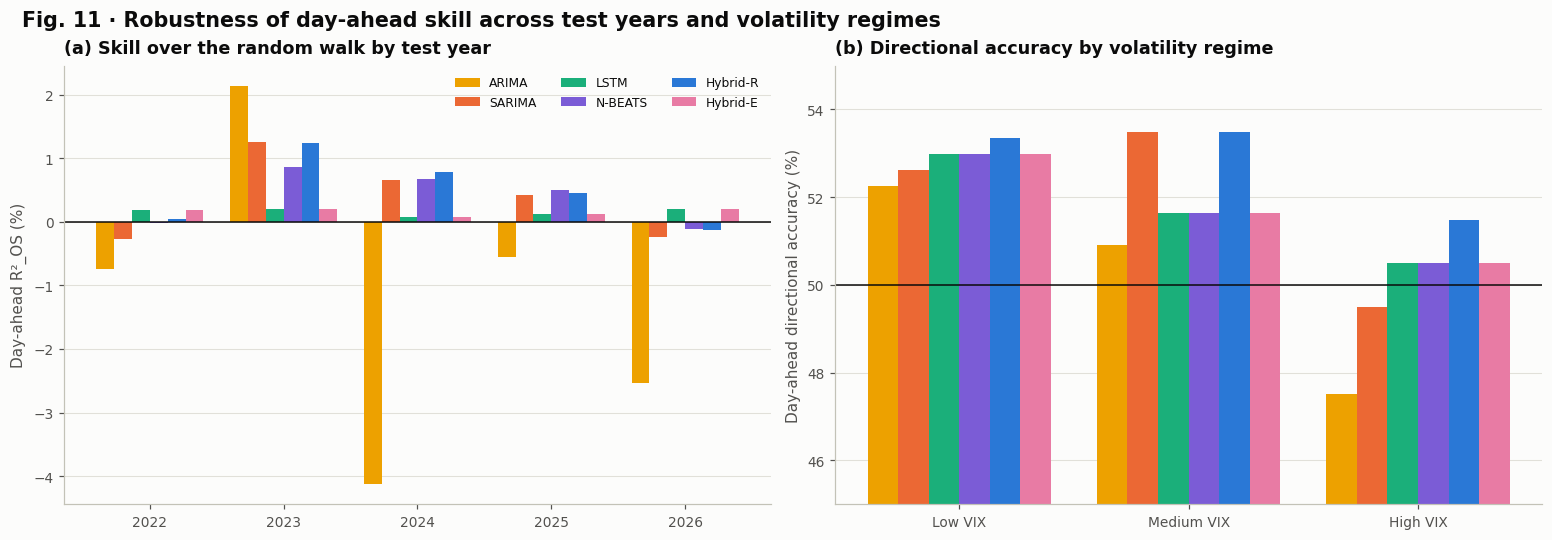

In [36]:
year_of = test_dates.year.to_numpy()
years = np.unique(year_of)
year_r2 = pd.DataFrame({str(y): {name: return_metrics(*(arr[year_of == y] for arr in model_returns(ctx, name, 1)))["R²_OS vs random walk (%)"]
                                 for name in MODEL_ORDER} for y in years})
show_table(year_r2, 21, f"Day-ahead R²_OS vs the random walk (%) by test year ({years[-1]} runs to early November)",
           fmt="{:+.2f}", high=list(year_r2.columns))

vix_origin = ctx.df["vix"].to_numpy()[ctx.test_targets - 1]
low_cut, high_cut = np.quantile(ctx.df["vix"].to_numpy()[:ctx.n_train], [1 / 3, 2 / 3])
regime = np.where(vix_origin <= low_cut, "Low VIX", np.where(vix_origin <= high_cut, "Medium VIX", "High VIX"))
regime_rows = {}
for name in MODEL_ORDER:
    actual, predicted = model_returns(ctx, name, 1)
    row = {}
    for label in ["Low VIX", "Medium VIX", "High VIX"]:
        m = return_metrics(actual[regime == label], predicted[regime == label])
        row[f"{label}: R²_OS (%)"] = m["R²_OS vs random walk (%)"]
        row[f"{label}: direction (%)"] = m["Directional accuracy (%)"]
    regime_rows[name] = row
regime_table = pd.DataFrame(regime_rows).T
counts = pd.Series(regime).value_counts()
show_table(regime_table, 22, f"Day-ahead skill by volatility regime (training terciles {low_cut:.1f} and {high_cut:.1f}; "
           f"test days: low {counts.get('Low VIX', 0)}, medium {counts.get('Medium VIX', 0)}, high {counts.get('High VIX', 0)})",
           fmt={col: ("{:+.2f}" if "R²" in col else "{:.2f}") for col in regime_table.columns},
           high=list(regime_table.columns))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
focus = LEARNED
width = 0.8 / len(focus)
x = np.arange(len(years))
for i, name in enumerate(focus):
    axes[0].bar(x + (i - (len(focus) - 1) / 2) * width, year_r2.loc[name], width=width, color=COLORS[name], label=name)
axes[0].axhline(0, color=INK, lw=1)
axes[0].set_xticks(x, [str(y) for y in years])
axes[0].set_ylabel("Day-ahead R²_OS (%)")
axes[0].set_title("(a) Skill over the random walk by test year")
axes[0].legend(loc="best", ncol=3, fontsize=8)
x = np.arange(3)
for i, name in enumerate(focus):
    axes[1].bar(x + (i - (len(focus) - 1) / 2) * width,
                [regime_table.loc[name, f"{label}: direction (%)"] for label in ["Low VIX", "Medium VIX", "High VIX"]],
                width=width, color=COLORS[name])
axes[1].axhline(50, color=INK, lw=1)
regime_values = regime_table.loc[focus, [f"{label}: direction (%)" for label in ["Low VIX", "Medium VIX", "High VIX"]]].to_numpy(dtype=float)
axes[1].set_ylim(min(45.0, np.nanmin(regime_values) - 1), max(55.0, np.nanmax(regime_values) + 1))
axes[1].set_xticks(x, ["Low VIX", "Medium VIX", "High VIX"])
axes[1].set_ylabel("Day-ahead directional accuracy (%)")
axes[1].set_title("(b) Directional accuracy by volatility regime")
for ax in axes:
    ax.grid(axis="x", visible=False)
finish(fig, 11, "Robustness of day-ahead skill across test years and volatility regimes", "years_regimes")

### 13.8 Residual diagnostics
A well-specified mean model leaves day-ahead errors without autocorrelation. Financial errors, however, keep **volatility clustering**: the Ljung-Box test on the *squared* errors detects it, and it is exactly what the GARCH-scaled intervals in Section 14 account for.

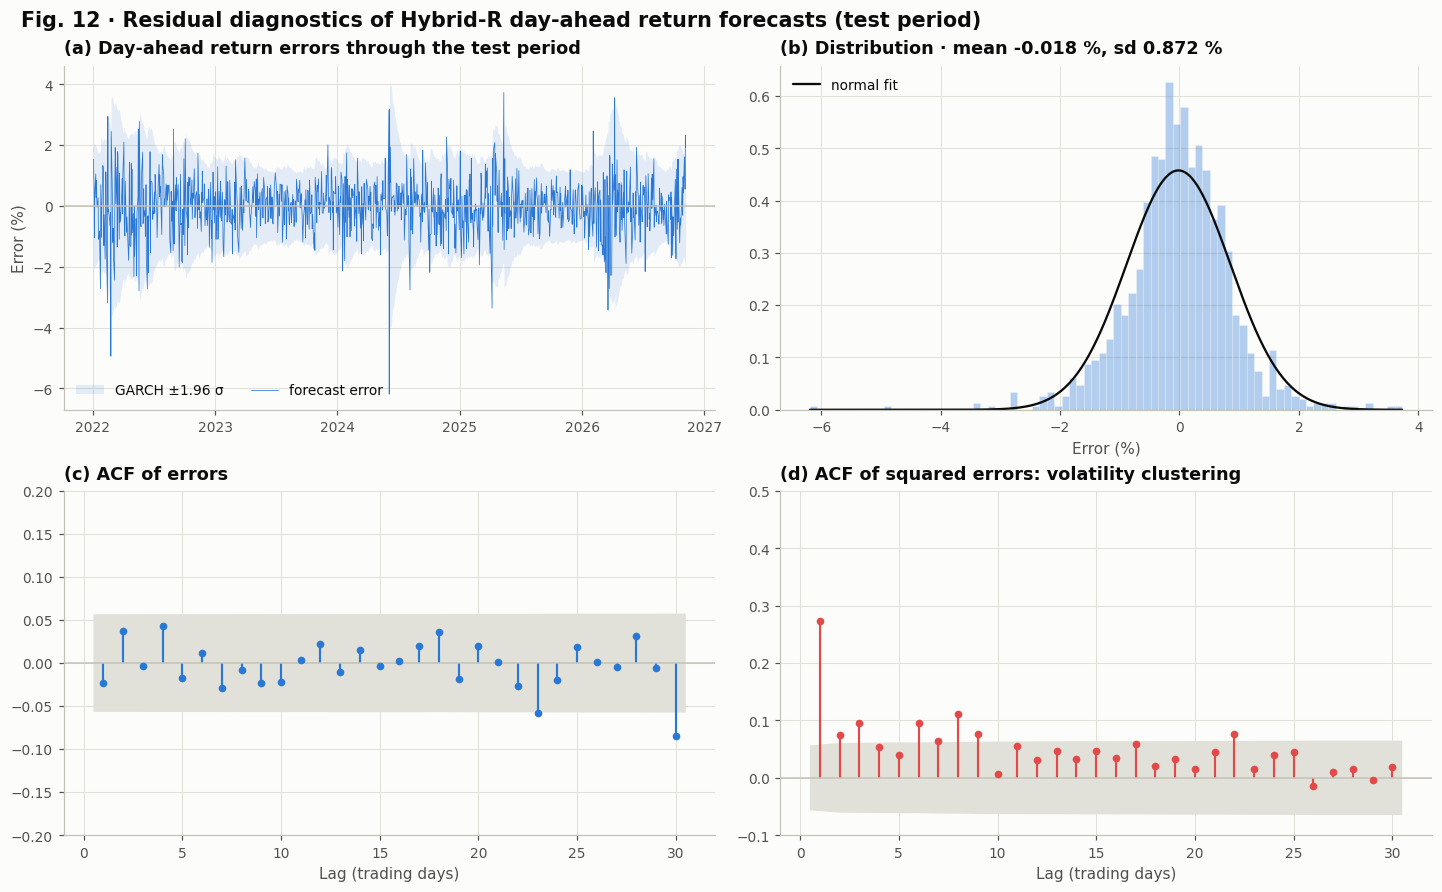

,Bias (bp),Error sd (%),Skewness,Excess kurtosis,"Ljung-Box p, errors","Ljung-Box p, squared errors"
Random walk,+3.06,0.8727,-0.40,4.02,0.5284,1.69e-29
Drift,+0.03,0.8727,-0.40,4.02,0.5284,8.28e-29
ARIMA,+0.02,0.8799,-0.37,4.44,0.0008,6.31e-33
SARIMA,+0.06,0.8724,-0.41,4.04,0.6524,8.46e-29
LSTM,+2.23,0.8723,-0.41,4.03,0.5361,4.00e-29
N-BEATS,-1.00,0.8720,-0.43,4.05,0.5329,1.02e-27
Hybrid-R,-1.75,0.8716,-0.43,4.07,0.6893,2.72e-27
Hybrid-E,+2.23,0.8723,-0.41,4.03,0.5361,4.00e-29


In [37]:
resid = pd.Series(np.subtract(*model_returns(ctx, "Hybrid-R", 1)) * 100, index=test_dates)
sd = resid.std()
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
ax = axes[0, 0]
band = 1.96 * 100 * np.sqrt(ctx.garch_v1[ctx.test_targets - 1])
ax.fill_between(resid.index, -band, band, color=COLORS["Hybrid-R"], alpha=0.12, lw=0, label="GARCH ±1.96 σ")
ax.plot(resid.index, resid, color=COLORS["Hybrid-R"], lw=0.5, label="forecast error")
ax.axhline(0, color=AXIS, lw=1)
ax.set_title("(a) Day-ahead return errors through the test period")
ax.set_ylabel("Error (%)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend(loc="lower left", ncol=2)
ax = axes[0, 1]
ax.hist(resid, bins=80, density=True, color=COLORS["Hybrid-R"], alpha=0.35, edgecolor=SURFACE, linewidth=0.5)
grid_x = np.linspace(resid.min(), resid.max(), 300)
ax.plot(grid_x, stats.norm.pdf(grid_x, resid.mean(), sd), color=INK, lw=1.5, label="normal fit")
ax.set_title(f"(b) Distribution · mean {resid.mean():+.3f} %, sd {sd:.3f} %")
ax.set_xlabel("Error (%)")
ax.legend(loc="upper left")
ax = axes[1, 0]
plot_acf(resid, lags=30, ax=ax, zero=False, vlines_kwargs={"colors": COLORS["Hybrid-R"], "lw": 1.4})
tidy_correlogram(ax, "(c) ACF of errors", color=COLORS["Hybrid-R"], markersize=4)
ax.set_ylim(-0.2, 0.2)
ax = axes[1, 1]
plot_acf(resid ** 2, lags=30, ax=ax, zero=False, vlines_kwargs={"colors": "#e34948", "lw": 1.4})
tidy_correlogram(ax, "(d) ACF of squared errors: volatility clustering", color="#e34948", markersize=4)
ax.set_ylim(-0.1, 0.5)
finish(fig, 12, "Residual diagnostics of Hybrid-R day-ahead return forecasts (test period)", "residual_diagnostics")

diag = {}
for name in MODEL_ORDER:
    actual, predicted = model_returns(ctx, name, 1)
    e = actual - predicted
    lb, lb2 = acorr_ljungbox(e, lags=[10]), acorr_ljungbox(e ** 2, lags=[10])
    diag[name] = {"Bias (bp)": 1e4 * e.mean(), "Error sd (%)": 100 * e.std(), "Skewness": stats.skew(e), "Excess kurtosis": stats.kurtosis(e),
                  "Ljung-Box p, errors": float(lb["lb_pvalue"].iloc[0]), "Ljung-Box p, squared errors": float(lb2["lb_pvalue"].iloc[0])}
diag = pd.DataFrame(diag).T
show_table(diag, 23, "Day-ahead error diagnostics (test period; bp = basis points, 1 bp = 0.01 %)",
           fmt={"Bias (bp)": "{:+.2f}", "Error sd (%)": "{:.4f}", "Skewness": "{:+.2f}", "Excess kurtosis": "{:.2f}",
                "Ljung-Box p, errors": "{:.4f}", "Ljung-Box p, squared errors": "{:.2e}"})

### 13.9 Ablation study: what does each part of Hybrid-R contribute?
An ablation removes one component at a time and measures the damage, the standard way to show that every part of a proposed model is needed. Four reduced versions of Hybrid-R are compared with the full model on the same test days:

| Variant | What is removed |
|---|---|
| SARIMA alone | the whole neural correction |
| Correction to the day-1 return only | the ψ-weight propagation: the correction changes tomorrow's return and nothing after it |
| Correction repeated on every day's return | the decay: tomorrow's correction is added to every future daily return |
| Single-task residual network | the auxiliary targets: a residual LSTM with the same configuration is trained to predict only SARIMA's volatility-scaled error |

Only the single-task variant needs new training (`N_ENSEMBLE` networks); the other variants reuse the full model's correction. Skill is measured by $R^2_{OS}$ against the random walk; a negative change means the reduced model is worse, so the removed component helps.

In [38]:
def single_task_correction(c):
    z = (np.nan_to_num(c.innovations) / np.sqrt(c.garch_s2)).astype("float32")

    def targets(origins):
        return z[origins + 1][:, None]

    members, _ = train_ensemble(c, c.X_res, targets, "residual_single_task", verbose=False)
    all_origins = np.append(c.origins, c.n - 1)
    correction = ensemble_predict(members, c.X_res, all_origins, c.lstm_cfg["lookback"])[:, 0] * np.sqrt(c.garch_v1[all_origins])
    del members
    gc.collect()
    return correction

t0 = time.time()
single_correction = single_task_correction(ctx)
base_paths = ctx.sarima_logp[np.append(ctx.origins, ctx.n - 1)]
variants = {"SARIMA alone (no neural correction)": base_paths,
            "Correction to the day-1 return only (no ψ propagation)": base_paths + ctx.hybrid_correction[:, None],
            "Correction repeated on every day's return": base_paths + ctx.hybrid_correction[:, None] * LEADS[None, :],
            "Single-task residual network (no auxiliary targets)": base_paths + single_correction[:, None] * ctx.cum_psi[None, :],
            "Full Hybrid-R (proposed)": base_paths + ctx.hybrid_correction[:, None] * ctx.cum_psi[None, :]}
ablation_rows = {}
for label, paths in variants.items():
    F = by_target(ctx, paths[:-1], ctx.test_targets)
    skill = [return_metrics(actual_returns(ctx, ctx.test_targets, h), forecast_returns(ctx, F, ctx.test_targets, h))["R²_OS vs random walk (%)"]
             for h in LEADS]
    ablation_rows[label] = {"R²_OS h = 1 (%)": skill[0], "R²_OS h = 5 (%)": skill[4], f"R²_OS h = {H} (%)": skill[H - 1],
                            f"Mean R²_OS 1 to {H} (%)": float(np.mean(skill))}
ablation = pd.DataFrame(ablation_rows).T
full_model = ablation.loc["Full Hybrid-R (proposed)"].copy()
ablation["Change vs full, h = 1 (points)"] = ablation["R²_OS h = 1 (%)"] - full_model["R²_OS h = 1 (%)"]
ablation["Change vs full, mean (points)"] = ablation[f"Mean R²_OS 1 to {H} (%)"] - full_model[f"Mean R²_OS 1 to {H} (%)"]
print(f"Single-task residual ensemble trained and evaluated in {time.time() - t0:.0f} s")
show_table(ablation, 24, "Ablation of Hybrid-R on the test period (R²_OS in %; negative change = the reduced model is worse, so the removed part helps)",
           fmt="{:+.3f}", high=["R²_OS h = 1 (%)", "R²_OS h = 5 (%)", f"R²_OS h = {H} (%)", f"Mean R²_OS 1 to {H} (%)"])

Single-task residual ensemble trained and evaluated in 38 s


,R²_OS h = 1 (%),R²_OS h = 5 (%),R²_OS h = 20 (%),Mean R²_OS 1 to 20 (%),"Change vs full, h = 1 (points)","Change vs full, mean (points)"
SARIMA alone (no neural correction),+0.198,+0.517,+1.740,+1.000,-0.154,-0.195
Correction to the day-1 return only (no ψ propagation),+0.351,+0.744,+1.898,+1.198,+0.000,+0.002
Correction repeated on every day's return,+0.351,+1.309,+3.188,+2.159,+0.000,+0.964
Single-task residual network (no auxiliary targets),+0.361,+0.678,+1.795,+1.120,+0.010,-0.075
Full Hybrid-R (proposed),+0.351,+0.744,+1.896,+1.195,+0.000,+0.000


**Reading Table 24.** Removing the neural correction shows what the LSTM adds to SARIMA. The two propagation variants show why the correction should follow SARIMA's own impulse response rather than stop after one day or be repeated forever. The single-task variant tests whether the auxiliary targets help the network learn from SARIMA's nearly white-noise errors. Changes of a few hundredths of a percentage point are within noise for daily returns; only clearly larger changes indicate an essential component.

### 13.10 Computational cost
Accuracy has to be weighed against cost. The table lists the number of estimated parameters of every model (summed over the ensemble members for the neural models) and the wall-clock time of fitting and forecasting on this runtime, including the hyperparameter search for the neural models, next to the day-ahead and mean skill. GARCH is listed separately because it forecasts volatility, not prices.

In [39]:
cost = pd.DataFrame(COST_LOG).T.reindex(MODEL_ORDER + ["GARCH(1,1)"])
cost["Day-ahead R²_OS (%)"] = day_ahead["R²_OS vs random walk (%)"].reindex(cost.index).astype(float)
cost[f"Mean R²_OS 1 to {H} (%)"] = r2_table[f"Mean 1 to {H}"].reindex(cost.index).astype(float)
show_table(cost, 25, f"Model size, run time and accuracy for {PRIMARY_ASSET} (times include the hyperparameter search; "
           "the hybrids include their SARIMA, GARCH and LSTM components)",
           fmt={"Parameters": "{:,.0f}", "Wall-clock time (s)": "{:,.0f}", "Day-ahead R²_OS (%)": "{:+.2f}",
                f"Mean R²_OS 1 to {H} (%)": "{:+.2f}"},
           high=["Day-ahead R²_OS (%)", f"Mean R²_OS 1 to {H} (%)"])

,Parameters,Wall-clock time (s),Day-ahead R²_OS (%),Mean R²_OS 1 to 20 (%)
Random walk,0,0,+0.00,+0.00
Drift,1,0,+0.12,+0.95
ARIMA,5,15,-1.51,+0.83
SARIMA,4,34,+0.20,+1.00
LSTM,"377,628",141,+0.16,+1.30
N-BEATS,"701,316",162,+0.28,+1.63
Hybrid-R,"379,171",66,+0.35,+1.20
Hybrid-E,"377,652",175,+0.16,+1.34
"GARCH(1,1)",3,0,n/a,n/a


## 14 · Uncertainty and risk

### 14.1 GARCH-scaled conformal prediction intervals
Constant-width intervals fail in markets: they are too wide in calm periods and far too narrow in crashes. Two interval types are compared:

* **Gaussian GARCH (SARIMA only):** $\ln \hat P_{t+h} \pm z_{0.975}\,\hat s_{t,h}$, where $\hat s_{t,h}$ is GARCH's forecast standard deviation of the cumulative return. It assumes normal errors, which Fig. 2 shows is unrealistic.
* **GARCH-scaled split-conformal (all learned models):** the *normalised* errors $|y - \hat y| / \hat s_{t,h}$ on the validation years give a quantile $q_h$ for every lead, and the interval is $\ln \hat P_{t+h} \pm q_h\,\hat s_{t,h}$ (Lei et al., 2018). This keeps GARCH's time-varying width but makes no assumption about the shape of the distribution, so fat tails are handled automatically.

Both are judged on the **test period** by their coverage (target 95 %) and their average width.

,Method,Coverage h = 1,Coverage h = 5,Coverage h = 20,"Coverage, all 20 leads",Mean width h = 1 (%),Mean width h = 20 (%)
ARIMA,GARCH-scaled conformal,96.4,96.5,97.7,97.9,3.66,18.47
SARIMA,GARCH-scaled conformal,96.6,96.7,97.7,97.9,3.73,18.31
LSTM,GARCH-scaled conformal,97.2,97.2,98.3,98.2,3.80,19.26
N-BEATS,GARCH-scaled conformal,96.7,96.7,97.7,97.9,3.72,18.49
Hybrid-R,GARCH-scaled conformal,96.7,96.6,97.7,98.0,3.72,18.31
Hybrid-E,GARCH-scaled conformal,97.2,97.2,98.3,98.1,3.80,19.03
SARIMA (Gaussian GARCH),Gaussian GARCH,95.6,94.4,95.5,95.6,3.43,15.99


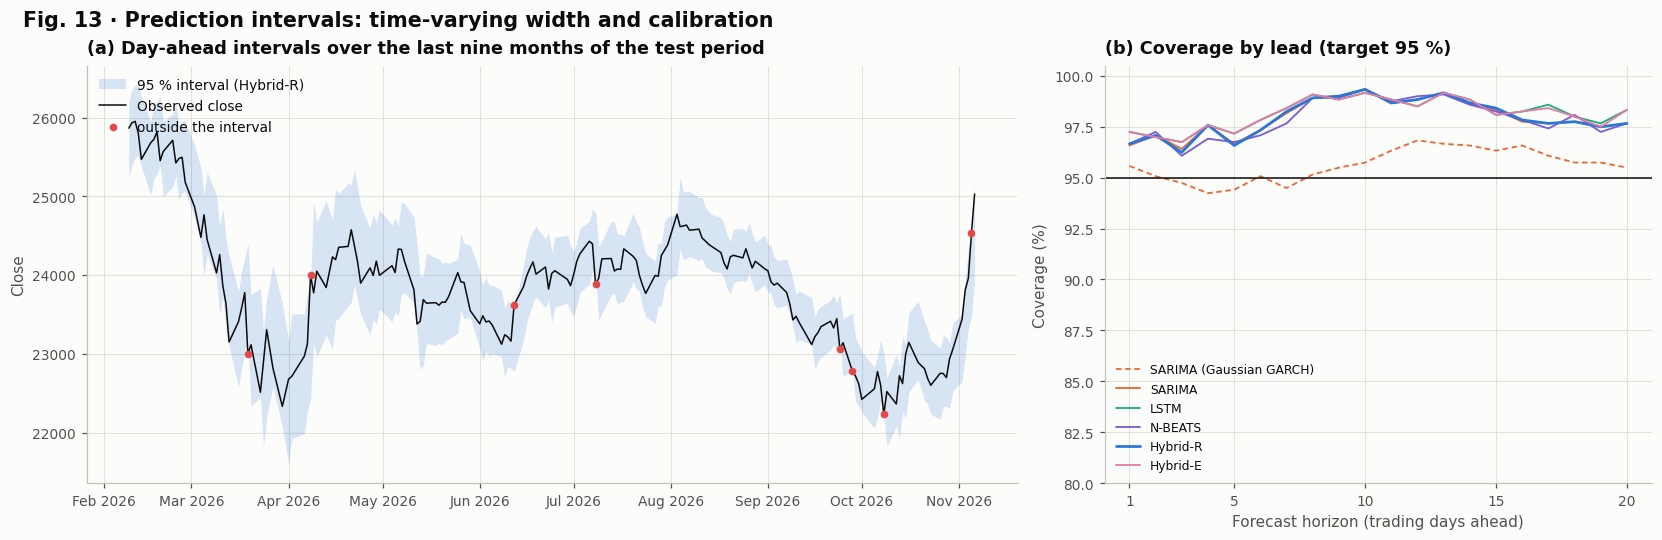

In [40]:
Z = stats.norm.ppf(1 - ALPHA / 2)

def scale_at(c, targets):
    return c.garch_cumsd[targets[:, None] - LEADS[None, :], LEADS - 1]

def compute_intervals(c):
    scale_val, scale_test = scale_at(c, c.val_targets), scale_at(c, c.test_targets)
    level = min(1.0, np.ceil((len(c.val_targets) + 1) * (1 - ALPHA)) / len(c.val_targets))
    c.half = {}
    for name in LEARNED:
        scores = np.abs(c.p[c.val_targets][:, None] - c.FC[name]["val"]) / scale_val
        q = np.quantile(scores, level, axis=0, method="higher")
        c.half[name] = {"model": name, "method": "GARCH-scaled conformal", "test": q[None, :] * scale_test,
                        "future": q * c.garch_cumsd[c.n - 1]}
    c.half["SARIMA (Gaussian GARCH)"] = {"model": "SARIMA", "method": "Gaussian GARCH", "test": Z * scale_test,
                                        "future": Z * c.garch_cumsd[c.n - 1]}

def coverage_table_for(c):
    rows = {}
    truth = c.p[c.test_targets][:, None]
    for label, info in c.half.items():
        inside = np.abs(truth - c.FC[info["model"]]["test"]) <= info["test"]
        rows[label] = {"Method": info["method"], "Coverage h = 1": 100 * inside[:, 0].mean(), "Coverage h = 5": 100 * inside[:, 4].mean(),
                       f"Coverage h = {H}": 100 * inside[:, H - 1].mean(), f"Coverage, all {H} leads": 100 * inside.mean(),
                       "Mean width h = 1 (%)": 200 * info["test"][:, 0].mean(), f"Mean width h = {H} (%)": 200 * info["test"][:, H - 1].mean()}
    return pd.DataFrame(rows).T

compute_intervals(ctx)
coverage_table = coverage_table_for(ctx)
show_table(coverage_table, 26, f"Calibration of {100 * (1 - ALPHA):.0f} % prediction intervals on the test period (width in % of price)",
           fmt={c: ("{}" if c == "Method" else "{:.1f}" if "Coverage" in c else "{:.2f}") for c in coverage_table.columns})

info = ctx.half["Hybrid-R"]
lower, upper = np.exp(ctx.FC["Hybrid-R"]["test"][:, 0] - info["test"][:, 0]), np.exp(ctx.FC["Hybrid-R"]["test"][:, 0] + info["test"][:, 0])
observed = np.exp(actual_logp)
outside = (observed < lower) | (observed > upper)
last = test_dates >= test_dates[-1] - pd.Timedelta(days=270)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.7, 1]})
ax = axes[0]
ax.fill_between(test_dates[last], lower[last], upper[last], color=COLORS["Hybrid-R"], alpha=0.18, lw=0, label="95 % interval (Hybrid-R)")
ax.plot(test_dates[last], observed[last], color=INK, lw=1.0, label="Observed close")
ax.scatter(test_dates[last & outside], observed[last & outside], s=16, color="#e34948", zorder=3, label="outside the interval")
ax.set_title("(a) Day-ahead intervals over the last nine months of the test period")
ax.set_ylabel("Close")
ax.legend(loc="upper left")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax = axes[1]
truth = ctx.p[ctx.test_targets][:, None]
lowest = 100.0
for label in ["SARIMA (Gaussian GARCH)", "SARIMA", "LSTM", "N-BEATS", "Hybrid-R", "Hybrid-E"]:
    info_l = ctx.half[label]
    cover = 100 * (np.abs(truth - ctx.FC[info_l["model"]]["test"]) <= info_l["test"]).mean(axis=0)
    lowest = min(lowest, float(cover.min()))
    ax.plot(LEADS, cover, color=COLORS[info_l["model"]], lw=1.8 if label == "Hybrid-R" else 1.2,
            linestyle=(0, (3, 2)) if label == "SARIMA (Gaussian GARCH)" else "-", label=label)
ax.axhline(100 * (1 - ALPHA), color=INK, lw=1)
ax.set_ylim(min(80.0, np.floor(lowest) - 2), 100.5)
ax.set_xticks([1, 5, 10, 15, 20])
ax.set_xlabel("Forecast horizon (trading days ahead)")
ax.set_ylabel("Coverage (%)")
ax.set_title("(b) Coverage by lead (target 95 %)")
ax.legend(loc="lower left", fontsize=8)
finish(fig, 13, "Prediction intervals: time-varying width and calibration", "prediction_intervals")

**Reading Table 26 and Fig. 13.** The intervals widen automatically when GARCH volatility rises and narrow in calm markets. Coverage close to 95 % means the stated uncertainty can be trusted. Gaussian intervals tend to undercover in fat-tailed markets, while the conformal version learns the tail behaviour from the validation years. Conformal validity assumes the test period behaves like the validation years; 2020 and 2021 contain an extreme crash, so the conformal intervals may be somewhat conservative later on.

### 14.2 How good is the volatility forecast?
GARCH is compared with two standard alternatives: **EWMA** (RiskMetrics, $\lambda = 0.94$) and the **21-day rolling variance**. Each forecasts tomorrow's variance; the squared return innovation $\varepsilon_{t+1}^2$ serves as the realised proxy. The **QLIKE** loss $\ln \hat\sigma^2 + \varepsilon^2 / \hat\sigma^2$ ranks forecasts correctly even with this noisy proxy (Patton, 2011); the Mincer-Zarnowitz $R^2$ measures how much of the proxy's variation a forecast explains.

In [41]:
def volatility_table_for(c):
    e = np.nan_to_num(c.innovations)
    s0 = float(e[1:c.n_train].var())
    ewma = lfilter([0.06], [1.0, -0.94], e ** 2, zi=[0.94 * s0])[0]
    rolling = pd.Series(e ** 2).rolling(21).mean().to_numpy()
    proxy = e[c.test_targets]
    rows = {}
    for label, forecast in [("GARCH(1,1)", c.garch_v1), ("EWMA (λ = 0.94)", ewma), ("21-day rolling variance", rolling)]:
        v = forecast[c.test_targets - 1]
        rows[label] = {"QLIKE": np.mean(np.log(v) + proxy ** 2 / v), "RMSE of variance (%²)": 1e4 * np.sqrt(np.mean((proxy ** 2 - v) ** 2)),
                       "Mincer-Zarnowitz R² (%)": 100 * np.corrcoef(v, proxy ** 2)[0, 1] ** 2}
    return pd.DataFrame(rows).T

volatility_table = volatility_table_for(ctx)
show_table(volatility_table, 27, "One-day-ahead volatility forecast evaluation on the test period (lower QLIKE is better)",
           fmt={"QLIKE": "{:.4f}", "RMSE of variance (%²)": "{:.4f}", "Mincer-Zarnowitz R² (%)": "{:.2f}"},
           low=["QLIKE", "RMSE of variance (%²)"], high=["Mincer-Zarnowitz R² (%)"])

,QLIKE,RMSE of variance (%²),Mincer-Zarnowitz R² (%)
"GARCH(1,1)",-8.6173,1.8350,4.70
EWMA (λ = 0.94),-8.6022,1.8388,4.27
21-day rolling variance,-8.5632,1.8694,3.23


## 15 · Multi-asset generalisation

One asset is one sample. To test whether the conclusions are a property of the *method* rather than of the NIFTY 50, the **identical pipeline** (same split, same protocol, same AIC-based order selection, the same random hyperparameter search run on each asset's own validation years, and the same ensemble size) is applied to four more assets:

| Asset | Why it is a useful test |
|---|---|
| NIFTY Bank | a sector index with higher volatility and strong sensitivity to interest rates |
| Reliance Industries | a single large stock with company-specific news and dividend adjustments |
| Tata Consultancy Services | a single IT stock driven by global technology demand and the rupee |
| S&P 500 | a different country, currency, trading calendar and volatility index |

`run_pipeline` chains every step of Sections 6 to 14 for one asset, including both hyperparameter searches. To stay within the memory of a free Colab runtime, the primary asset's networks are first saved to `outputs/models/`, and after each asset everything that later sections do not need (networks, Kalman-filter results, feature arrays) is released with `slim` and `release_memory`; the forecasts, intervals and selected settings are kept. This cell takes the longest; Table 32 lists what was selected for each asset.

In [42]:
HEAVY_ATTRIBUTES = ("lstm_members", "residual_members", "nbeats_members", "lstm_histories", "residual_histories",
                    "nbeats_histories", "X_all", "X_res", "R", "R_scaled", "r_scaled", "y", "innovations",
                    "arima_res", "arima_full", "sarima_res", "sarima_full", "F_arima", "F_sarima", "sarima_logp",
                    "garch_s2", "garch_cumsd", "nn_train", "nb_train")

def slim(c):
    for attr in HEAVY_ATTRIBUTES:
        if hasattr(c, attr):
            delattr(c, attr)

def release_memory():
    get_reusable_executor().shutdown(wait=True)
    keras.backend.clear_session()
    gc.collect()

def save_networks(c):
    (OUT_DIR / "models").mkdir(parents=True, exist_ok=True)
    for group, members in [("lstm", c.lstm_members), ("hybrid_residual", c.residual_members), ("nbeats", c.nbeats_members)]:
        for k, model in enumerate(members, start=1):
            model.save(OUT_DIR / "models" / f"{group}_member{k}.keras")

def run_pipeline(name):
    c = make_context(name)
    fit_baselines(c)
    fit_arima(c)
    fit_sarima(c)
    fit_garch(c)
    prepare_features(c)
    c.lstm_tuning = tune_lstm(c, verbose=False)
    fit_lstm(c, verbose=False)
    prepare_nbeats(c)
    c.nbeats_tuning = tune_nbeats(c, verbose=False)
    fit_nbeats(c, verbose=False)
    fit_hybrid_r(c, verbose=False)
    fit_hybrid_e(c)
    compute_intervals(c)
    return c

ctx.lstm_tuning, ctx.nbeats_tuning = lstm_tuning, nbeats_tuning
save_networks(ctx)
slim(ctx)
release_memory()
CONTEXTS = {PRIMARY_ASSET: ctx}
for name in ASSETS:
    if name == PRIMARY_ASSET:
        continue
    start = time.time()
    CONTEXTS[name] = run_pipeline(name)
    c = CONTEXTS[name]
    m = return_metrics(*model_returns(c, "Hybrid-R", 1))
    print(f"{name:<11} done in {time.time() - start:>4.0f} s · ARIMA{c.arima_order} · SARIMA{c.sarima_order}{c.seasonal_order} · "
          f"Hybrid-R day-ahead R²_OS {m['R²_OS vs random walk (%)']:+.2f} %, direction {m['Directional accuracy (%)']:.2f} %")
    slim(c)
    release_memory()

NIFTY Bank  done in  484 s · ARIMA(0, 1, 1) · SARIMA(0, 1, 0)(1, 0, 0, 5) · Hybrid-R day-ahead R²_OS +0.27 %, direction 53.34 %
Reliance    done in  369 s · ARIMA(2, 1, 2) · SARIMA(0, 1, 0)(1, 0, 0, 5) · Hybrid-R day-ahead R²_OS +0.03 %, direction 50.67 %
TCS         done in  447 s · ARIMA(2, 1, 2) · SARIMA(1, 1, 1)(1, 0, 1, 5) · Hybrid-R day-ahead R²_OS -1.62 %, direction 48.83 %
S&P 500     done in  471 s · ARIMA(3, 1, 0) · SARIMA(1, 1, 0)(0, 0, 1, 5) · Hybrid-R day-ahead R²_OS -2.01 %, direction 52.26 %


In [43]:
asset_r2 = pd.DataFrame({name: return_table_for(c)["R²_OS vs random walk (%)"] for name, c in CONTEXTS.items()}).T[MODEL_ORDER[1:]]
asset_da = pd.DataFrame({name: return_table_for(c)["Directional accuracy (%)"] for name, c in CONTEXTS.items()}).T[MODEL_ORDER[1:]]
asset_r2_mean = pd.DataFrame({name: horizon_tables(c)[0].mean() for name, c in CONTEXTS.items()}).T[MODEL_ORDER[1:]]
asset_sharpe = pd.DataFrame({name: backtest_for(c)[0]["Sharpe ratio"] for name, c in CONTEXTS.items()}).T
asset_coverage = pd.DataFrame({name: coverage_table_for(c)[f"Coverage, all {H} leads"] for name, c in CONTEXTS.items()}).T
for table in (asset_r2, asset_r2_mean):
    table.loc["Mean rank"] = table.loc[list(ASSETS)].rank(axis=1, ascending=False).mean()
show_table(asset_r2, 28, "Day-ahead R²_OS vs the random walk (%) by asset; last row: mean rank across assets (1 = best)",
           fmt="{:+.2f}", high=MODEL_ORDER[1:], axis=1, rows=list(ASSETS), rank_row="Mean rank")
show_table(asset_da, 29, "Day-ahead directional accuracy (%) by asset", fmt="{:.2f}", high=MODEL_ORDER[1:], axis=1)
show_table(asset_r2_mean, 30, f"Mean R²_OS (%) over all leads 1 to {H} by asset; last row: mean rank (1 = best)",
           fmt="{:+.2f}", high=MODEL_ORDER[1:], axis=1, rows=list(ASSETS), rank_row="Mean rank")
show_table(asset_sharpe, 31, "Sharpe ratio of the long-or-cash back-test by asset (after costs)", fmt="{:.3f}",
           high=list(asset_sharpe.columns), axis=1)
selected = pd.DataFrame({name: {"ARIMA order": str(c.arima_order), "SARIMA order": f"{c.sarima_order}{c.seasonal_order}",
                                "GARCH persistence": f"{c.garch['alpha'] + c.garch['beta']:.4f}",
                                **{f"LSTM {k}": v for k, v in format_cfg(c.lstm_cfg).items()},
                                "LSTM validation MSE ratio": f"{c.lstm_tuning['Validation MSE ratio vs random walk'].iloc[0]:.4f}",
                                **{f"N-BEATS {k}": v for k, v in c.nbeats_cfg.items()},
                                "N-BEATS validation MSE ratio": f"{c.nbeats_tuning['Validation MSE ratio vs random walk'].iloc[0]:.4f}",
                                f"Hybrid-R interval coverage, all {H} leads (%)": f"{asset_coverage.loc[name, 'Hybrid-R']:.1f}"}
                         for name, c in CONTEXTS.items()}).T
show_table(selected.astype(str), 32, "Model orders, volatility persistence and hyperparameters selected for each asset", fmt="{}")

,Drift,ARIMA,SARIMA,LSTM,N-BEATS,Hybrid-R,Hybrid-E
NIFTY 50,+0.12,-1.51,+0.20,+0.16,+0.28,+0.35,+0.16
NIFTY Bank,+0.16,-1.86,+0.28,+0.17,+0.23,+0.27,+0.17
Reliance,+0.00,-0.34,+0.03,+0.01,+0.13,+0.03,+0.01
TCS,-0.51,-2.01,-1.10,-1.04,-0.89,-1.62,-1.10
S&P 500,+0.11,-1.36,-0.75,-1.10,+0.07,-2.01,-0.75
Mean rank,+4.00,+6.80,+3.00,+4.30,+2.00,+3.60,+4.30


,Drift,ARIMA,SARIMA,LSTM,N-BEATS,Hybrid-R,Hybrid-E
NIFTY 50,52.46,51.55,52.55,52.46,52.46,53.22,52.46
NIFTY Bank,53.18,51.67,54.43,53.18,53.18,53.34,53.18
Reliance,50.58,51.50,50.67,50.58,49.50,50.67,50.58
TCS,47.58,48.08,48.75,47.58,47.58,48.83,48.75
S&P 500,52.83,51.19,51.11,52.42,52.59,52.26,51.11


,Drift,ARIMA,SARIMA,LSTM,N-BEATS,Hybrid-R,Hybrid-E
NIFTY 50,+0.95,+0.83,+1.00,+1.30,+1.63,+1.20,+1.34
NIFTY Bank,+1.19,+0.91,+1.32,+0.06,+1.63,+1.25,+0.06
Reliance,-0.19,+0.05,-0.12,+0.06,+0.20,-0.12,-0.12
TCS,-5.19,-5.78,-6.08,-7.55,-6.24,-6.40,-6.05
S&P 500,+1.53,+1.53,+1.77,-7.63,+2.46,+1.66,-6.52
Mean rank,+4.60,+4.20,+3.60,+5.10,+1.80,+4.40,+4.30


,Buy and hold,ARIMA,SARIMA,LSTM,N-BEATS,Hybrid-R,Hybrid-E
NIFTY 50,0.626,-0.103,0.581,0.626,0.626,0.671,0.626
NIFTY Bank,0.723,0.260,0.691,0.723,0.723,0.617,0.723
Reliance,0.305,0.713,0.307,0.305,0.049,0.307,0.305
TCS,-0.121,-0.426,-0.073,-0.121,-0.121,-0.006,-0.073
S&P 500,0.612,0.343,0.091,0.569,0.529,0.346,0.091


,ARIMA order,SARIMA order,GARCH persistence,LSTM lookback,LSTM units,LSTM dropout,LSTM learning_rate,LSTM batch_size,LSTM validation MSE ratio,N-BEATS lookback,N-BEATS dropout,N-BEATS learning_rate,N-BEATS validation MSE ratio,"Hybrid-R interval coverage, all 20 leads (%)"
NIFTY 50,"(2, 1, 1)","(0, 1, 0)(1, 0, 1, 5)",0.9940,20,128 / 64,0.3,0.0001,64,0.9937,120,0.1,0.0003,0.9870,98.0
NIFTY Bank,"(0, 1, 1)","(0, 1, 0)(1, 0, 0, 5)",0.9944,60,128 / 64,0.5,0.0001,32,0.9850,20,0.1,0.0001,1.0024,98.0
Reliance,"(2, 1, 2)","(0, 1, 0)(1, 0, 0, 5)",0.9811,60,32 / 16,0.3,0.0001,128,0.9995,120,0.1,0.0003,0.9914,98.7
TCS,"(2, 1, 2)","(1, 1, 1)(1, 0, 1, 5)",0.9627,60,128 / 64,0.5,0.0001,32,0.9574,120,0.1,0.0003,0.9565,96.2
S&P 500,"(3, 1, 0)","(1, 1, 0)(0, 0, 1, 5)",0.9804,20,128 / 64,0.3,0.0001,64,0.9331,60,0.1,0.0001,0.9697,96.1


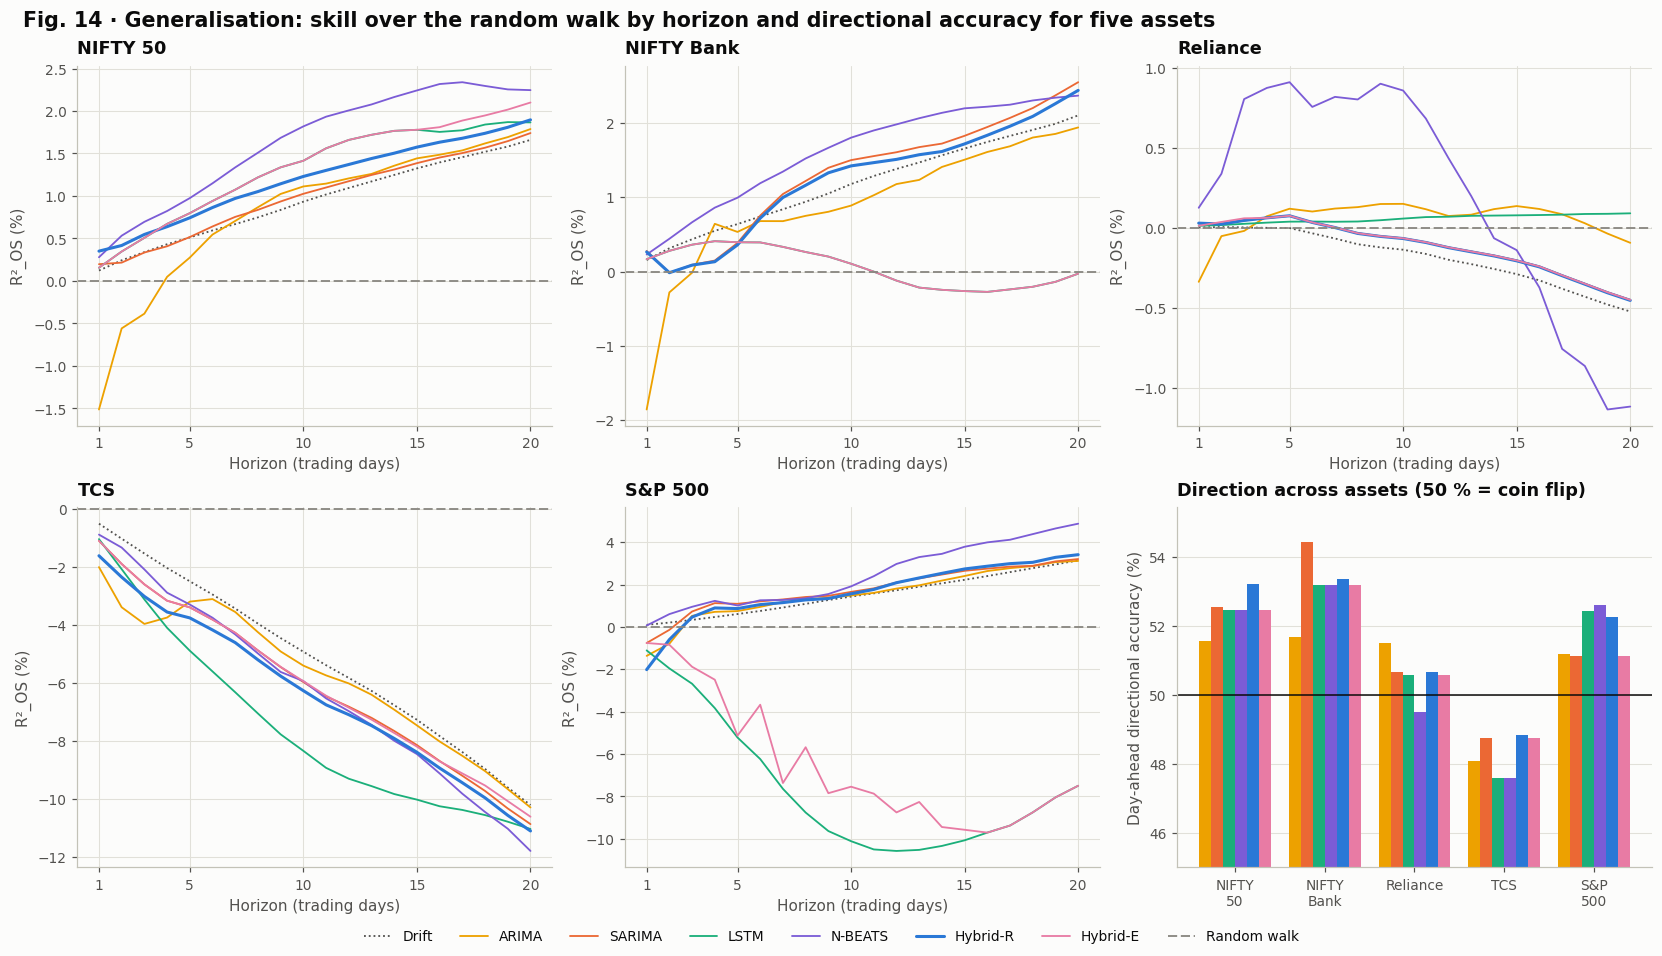

In [44]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8.6))
for ax, (name, c) in zip(axes.flat, CONTEXTS.items()):
    curves = horizon_tables(c)[0]
    for model in MODEL_ORDER[1:]:
        ax.plot(LEADS, curves[model], color=COLORS[model], lw=2.0 if model == "Hybrid-R" else 1.2,
                linestyle=LINESTYLES.get(model, "-"), label=model)
    ax.axhline(0, color=MUTED, lw=1.2, linestyle=LINESTYLES["Random walk"])
    ax.set_title(name)
    ax.set_xticks([1, 5, 10, 15, 20])
    ax.set_xlabel("Horizon (trading days)")
    ax.set_ylabel("R²_OS (%)")
for spare in axes.flat[len(CONTEXTS) + 1:]:
    spare.set_visible(False)
ax = axes.flat[len(CONTEXTS)]
x = np.arange(len(CONTEXTS))
width = 0.8 / len(LEARNED)
for i, model in enumerate(LEARNED):
    ax.bar(x + (i - (len(LEARNED) - 1) / 2) * width, asset_da[model], width=width, color=COLORS[model], label=model)
ax.axhline(50, color=INK, lw=1)
low = np.nanmin(asset_da[LEARNED].to_numpy())
high = np.nanmax(asset_da[LEARNED].to_numpy())
ax.set_ylim(min(45, low - 1), max(55, high + 1))
ax.set_xticks(x, [name.replace(" ", "\n") for name in CONTEXTS])
ax.set_ylabel("Day-ahead directional accuracy (%)")
ax.set_title("Direction across assets (50 % = coin flip)")
ax.grid(axis="x", visible=False)
handles, labels = axes.flat[0].get_legend_handles_labels()
handles.append(Line2D([], [], color=MUTED, lw=1.2, linestyle=LINESTYLES["Random walk"]))
labels.append("Random walk")
try:
    fig.legend(handles, labels, loc="outside lower center", ncol=8)
except (ValueError, TypeError):
    fig.legend(handles, labels, loc="lower center", ncol=8, bbox_to_anchor=(0.5, -0.04))
finish(fig, 14, "Generalisation: skill over the random walk by horizon and directional accuracy for five assets", "multi_asset")

## 16 · 20-day out-of-sample forecast

Finally, every model forecasts the next 20 trading days beyond the last observation (6 November 2026). Parameters stay frozen; the models' states have absorbed every observation up to the forecast origin, exactly as in an operational setting. The dates are approximate, because exchange holidays in the coming weeks are not modelled. The fan chart shows the central forecasts with GARCH-scaled conformal 95 % intervals, which widen with the horizon as uncertainty accumulates.

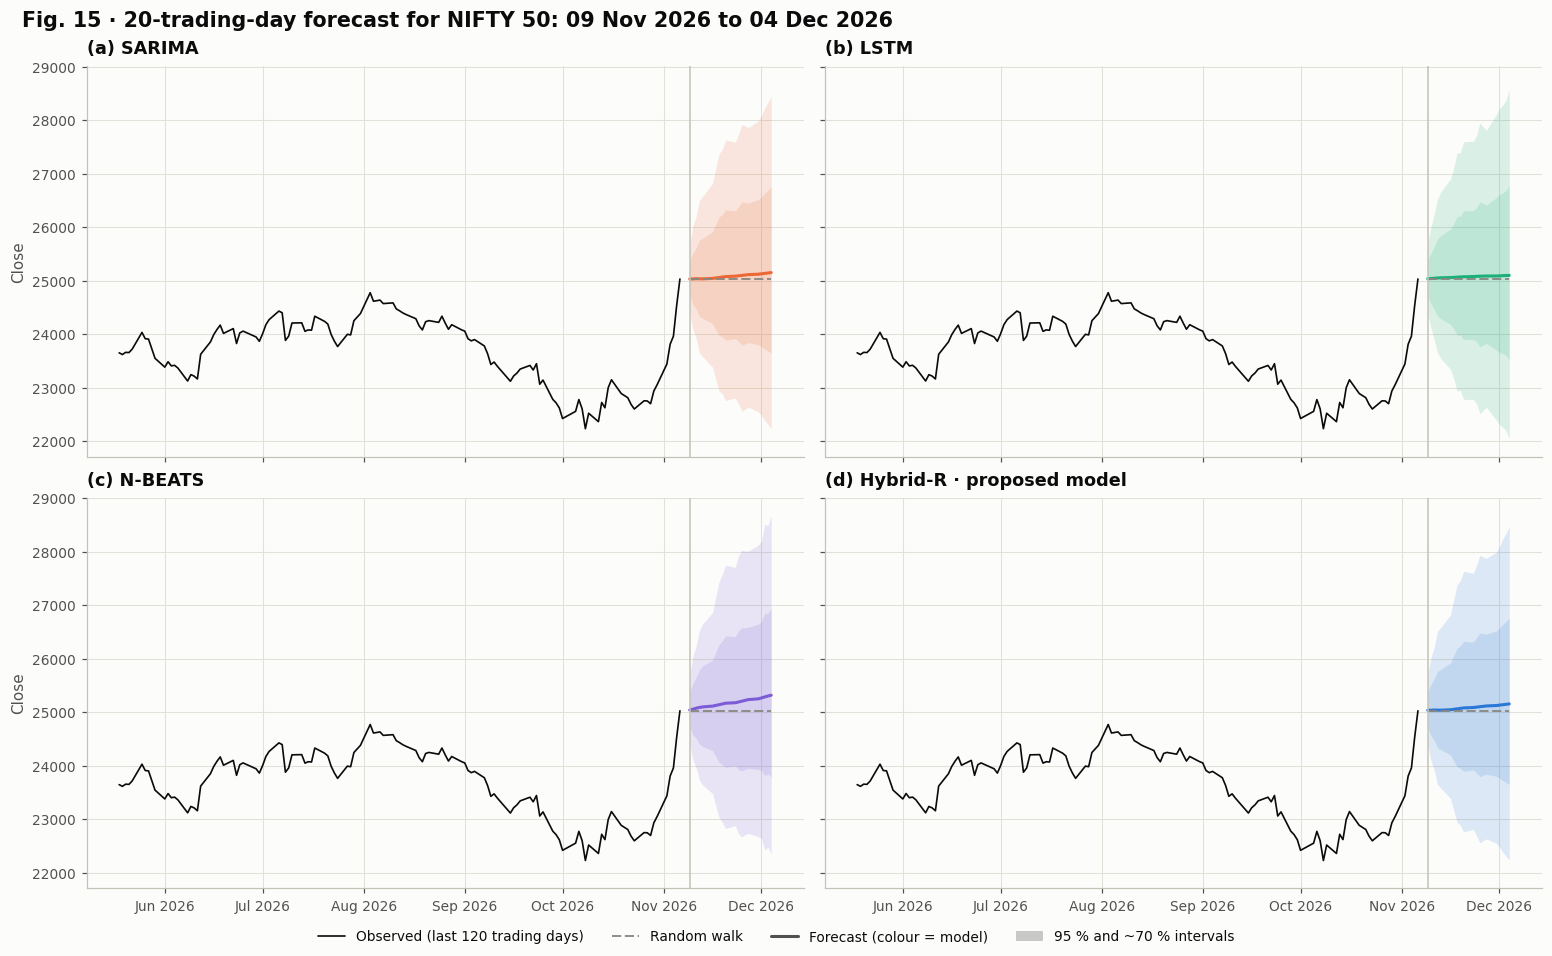

,Hybrid-R,SARIMA,LSTM,N-BEATS,Hybrid-E,Random walk
Day 1 · 09 Nov 2026,"25,039.9 [24,396.6, 25,700.2]","25,030.8 [24,386.4, 25,692.2]","25,034.4 [24,378.4, 25,708.1]","25,045.7 [24,402.0, 25,706.3]","25,034.4 [24,378.4, 25,708.1]","25,030.3"
Day 2 · 10 Nov 2026,"25,040.5 [24,094.6, 26,023.5]","25,031.4 [24,086.6, 26,013.3]","25,039.4 [24,110.6, 26,004.0]","25,060.8 [24,110.6, 26,048.5]","25,039.4 [24,110.6, 26,004.0]","25,030.3"
Day 5 · 13 Nov 2026,"25,041.7 [23,586.3, 26,586.8]","25,032.6 [23,578.3, 26,576.5]","25,052.5 [23,544.6, 26,657.0]","25,103.2 [23,639.6, 26,657.3]","25,052.5 [23,544.6, 26,657.0]","25,030.3"
Day 10 · 20 Nov 2026,"25,084.2 [22,767.2, 27,637.1]","25,075.3 [22,758.5, 27,627.9]","25,071.3 [22,779.0, 27,594.3]","25,172.0 [22,830.4, 27,753.7]","25,071.3 [22,779.0, 27,594.3]","25,030.3"
Day 20 · 04 Dec 2026,"25,158.7 [22,237.4, 28,463.8]","25,149.7 [22,229.8, 28,453.1]","25,097.7 [22,041.7, 28,577.4]","25,321.1 [22,353.6, 28,682.6]","25,110.1 [22,086.6, 28,547.6]","25,030.3"


In [45]:
history = ctx.df["close"].iloc[-120:]
outlook = ["SARIMA", "LSTM", "N-BEATS", "Hybrid-R"]
fig, axes = plt.subplots(2, 2, figsize=(14, 8.6), sharex=True, sharey=True)
for panel, (ax, name) in enumerate(zip(axes.flat, outlook)):
    centre, half = ctx.FC[name]["future"], ctx.half[name]["future"]
    ax.plot(history.index, history, color=INK, lw=1.1)
    ax.fill_between(ctx.future_index, np.exp(centre - half), np.exp(centre + half), color=COLORS[name], alpha=0.15, lw=0)
    ax.fill_between(ctx.future_index, np.exp(centre - half / 2), np.exp(centre + half / 2), color=COLORS[name], alpha=0.15, lw=0)
    ax.plot(ctx.future_index, np.exp(centre), color=COLORS[name], lw=2.0)
    ax.plot(ctx.future_index, np.exp(ctx.FC["Random walk"]["future"]), color=MUTED, lw=1.2, linestyle=LINESTYLES["Random walk"])
    ax.axvline(ctx.future_index[0], color=AXIS, lw=1)
    ax.set_title(f"({'abcd'[panel]}) {name}" + (" · proposed model" if name == "Hybrid-R" else ""))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
for ax in axes[:, 0]:
    ax.set_ylabel("Close")
legend_handles = [Line2D([], [], color=INK, lw=1.1, label="Observed (last 120 trading days)"),
                  Line2D([], [], color=MUTED, lw=1.2, linestyle=LINESTYLES["Random walk"], label="Random walk"),
                  Line2D([], [], color=INK_2, lw=2.0, label="Forecast (colour = model)"),
                  Patch(facecolor=INK_2, alpha=0.3, label="95 % and ~70 % intervals")]
try:
    fig.legend(handles=legend_handles, loc="outside lower center", ncol=4)
except (ValueError, TypeError):
    fig.legend(handles=legend_handles, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.04))
finish(fig, 15, f"{H}-trading-day forecast for {PRIMARY_ASSET}: {ctx.future_index[0]:%d %b %Y} to {ctx.future_index[-1]:%d %b %Y}",
       "future_forecast")

future = pd.DataFrame(index=pd.Index(ctx.future_index, name="date (approximate)"))
for name in LEARNED:
    future[name] = np.exp(ctx.FC[name]["future"])
    future[f"{name} lower"] = np.exp(ctx.FC[name]["future"] - ctx.half[name]["future"])
    future[f"{name} upper"] = np.exp(ctx.FC[name]["future"] + ctx.half[name]["future"])
future["Random walk"] = np.exp(ctx.FC["Random walk"]["future"])
snapshot = pd.DataFrame({name: [f"{future[name].iloc[h - 1]:,.1f}  [{future[f'{name} lower'].iloc[h - 1]:,.1f}, "
                                f"{future[f'{name} upper'].iloc[h - 1]:,.1f}]" for h in LEAD_CHECKPOINTS]
                         for name in ["Hybrid-R", "SARIMA", "LSTM", "N-BEATS", "Hybrid-E"]},
                        index=[f"Day {h} · {ctx.future_index[h - 1]:%d %b %Y}" for h in LEAD_CHECKPOINTS])
snapshot["Random walk"] = [f"{future['Random walk'].iloc[h - 1]:,.1f}" for h in LEAD_CHECKPOINTS]
show_table(snapshot, 33, f"{PRIMARY_ASSET} close forecasts with {100 * (1 - ALPHA):.0f} % intervals (last close "
           f"{ctx.close[-1]:,.1f} on {ctx.dates[-1]:%d %b %Y})", fmt="{}")

**Reading Fig. 15 and Table 33.** The central forecasts stay close to the last close, with a small drift, while the intervals widen roughly with the square root of the horizon. This is the honest shape of a market forecast: the expected path is nearly flat and the uncertainty is large. The forecast covers dates that had not happened when the data were frozen, so it can be checked later.

## 17 · Research summary

### 17.1 Methodology
1. **Data.** Daily prices from Yahoo Finance, 3 March 2008 to 6 November 2026, for the NIFTY 50, NIFTY Bank, Reliance Industries, Tata Consultancy Services and the S&P 500, plus India VIX and CBOE VIX, frozen in a snapshot for reproducibility. A data-quality audit checked duplicates, missing and invalid prices and OHLC consistency; prices were adjusted for dividends and splits, and causal technical features were computed (Tables 1 and 2).
2. **Diagnostics.** ADF and KPSS tests confirmed a unit root in log prices and stationary returns (Table 4), and the stylised facts (fat tails, negligible return autocorrelation, strong volatility clustering) motivated modelling returns, a random-walk benchmark and GARCH-scaled intervals.
3. **Models.** Random walk and drift baselines; ARIMA with AIC-selected orders and weekly SARIMA with orders selected on the validation years, both with exact vectorised multi-horizon forecasts; GARCH(1,1) for volatility; a multi-feature LSTM ensemble and an N-BEATS ensemble with direct 20-day output, both with hyperparameters optimised per asset by random search on the validation years; *Hybrid-R*, SARIMA plus an LSTM learner of its volatility-scaled one-step errors with the correction propagated through SARIMA's impulse response; and *Hybrid-E*, a per-horizon validation-optimal combination of SARIMA and the LSTM. Both networks are trained on GARCH-scaled targets and start from the random walk.
4. **Protocol.** Chronological split (2008 to 2019 training, 2020 and 2021 validation, January 2022 to November 2026 test), frozen parameters, and every test day forecast at every lead from 1 to 20 trading days. Evaluation uses price-level errors, return-level errors, the out-of-sample R² against the random walk, directional accuracy with the Pesaran-Timmermann test, Diebold-Mariano tests, a long-or-cash back-test after costs, year-wise and volatility-regime analysis, residual diagnostics, interval coverage and volatility-forecast losses, first for the NIFTY 50 and then for four more assets. Improvements are reported with paired block-bootstrap confidence intervals and Holm-corrected significance tests, and an ablation study isolates every component of Hybrid-R.

### 17.2 Results of this run
The cell below writes the findings from the numbers computed above, so they stay correct if the notebook is re-run or re-configured.

In [46]:
d = day_ahead
r2 = d["R²_OS vs random walk (%)"].astype(float)
da = d["Directional accuracy (%)"].astype(float)
best_r2_model = r2.drop("Random walk").idxmax()
beats_rw = [m for m in LEARNED if r2[m] > 0]
significant_dir = [m for m in LEARNED if np.isfinite(d.loc[m, "Pesaran-Timmermann p"]) and d.loc[m, "Pesaran-Timmermann p"] < 0.05 and da[m] > 50]
hr = d.loc["Hybrid-R"]
dm_rw_p, dm_rw_stat = dm_table.loc["Random walk", "p (h=1)"], dm_table.loc["Random walk", "DM (h=1)"]
dm_base_p, dm_base_stat = dm_table.loc["SARIMA", "p (h=1)"], dm_table.loc["SARIMA", "DM (h=1)"]
mean_r2 = r2_table[f"Mean 1 to {H}"].drop("Random walk").astype(float)
bt = backtest_table
best_sharpe = bt["Sharpe ratio"].astype(float).idxmax()
strategies_beating = [m for m in LEARNED if bt.loc[m, "Sharpe ratio"] > bt.loc["Buy and hold", "Sharpe ratio"]]
cov = coverage_table[f"Coverage, all {H} leads"].astype(float)
vol_best = volatility_table["QLIKE"].astype(float).idxmin()
assets_beating = int((asset_r2.loc[list(ASSETS), "Hybrid-R"] > 0).sum())
assets_dir = int((asset_da.loc[list(ASSETS), "Hybrid-R"] > 50).sum())
rank_day = asset_r2.loc["Mean rank"].sort_values()
rank_mean = asset_r2_mean.loc["Mean rank"].sort_values()
price_r2_min = price_table["Price R²"].astype(float).min()

def verdict(stat, p, better="Hybrid-R"):
    if p >= 0.05:
        return f"not significant (DM {stat:+.2f}, p = {p:.3f})"
    return f"significant, {better} {'better' if stat < 0 else 'worse'} (DM {stat:+.2f}, p = {p:.4f})"

def calibration(coverage):
    nominal = 100 * (1 - ALPHA)
    if abs(coverage - nominal) <= 2.5:
        return "well calibrated"
    return "conservative" if coverage > nominal else "over-confident"

def gain_text(table, other):
    row = table.loc[other]
    return (f"**{row['Return RMSE reduction h = 1 (%)']:+.2f} %** vs {other} (95 % CI {row['95 % CI low']:+.2f} to "
            f"{row['95 % CI high']:+.2f} %, {row['Verdict (5 %, Holm)']})")

imp = improvement["Hybrid-R"]
best_hybrid = ("Hybrid-R" if float(d.loc["Hybrid-R", "R²_OS vs random walk (%)"]) >= float(d.loc["Hybrid-E", "R²_OS vs random walk (%)"])
               else "Hybrid-E")
headline = (f"**Headline result.** Day-ahead return RMSE reduction achieved by the proposed Hybrid-R on {len(ctx.test_targets):,} unseen "
            f"test days of the {PRIMARY_ASSET} (positive = Hybrid-R better): "
            + "; ".join(gain_text(imp, m) for m in ["Random walk", "Drift", "ARIMA", "SARIMA", "LSTM", "N-BEATS"])
            + f". Its day-ahead R²_OS against the random walk is {hr['R²_OS vs random walk (%)']:+.2f} % and its mean R²_OS over all {H} "
            f"leads is {float(r2_table.loc['Hybrid-R', f'Mean 1 to {H}']):+.2f} %. The best hybrid one day ahead is **{best_hybrid}**. "
            f"In the ablation, removing the neural correction changes the day-ahead R²_OS by "
            f"{ablation.loc['SARIMA alone (no neural correction)', 'Change vs full, h = 1 (points)']:+.2f} points and removing the "
            f"auxiliary targets by {ablation.loc['Single-task residual network (no auxiliary targets)', 'Change vs full, h = 1 (points)']:+.2f} "
            f"points (negative = the component helps).")

text = f"""
{headline}

**Price accuracy.** One day ahead, every model's price forecast has an R² of at least {price_r2_min:.4f} on the
{len(ctx.test_targets):,} test days (Table 13), including the random walk. Price-level errors therefore confirm that the forecasts are
well-behaved but cannot separate the models, exactly as expected in an efficient market.

**Return accuracy (RQ1).** The decisive out-of-sample R² against the random walk ranges from {r2.drop('Random walk').min():+.2f} % to
{r2.drop('Random walk').max():+.2f} %; the best day-ahead model is **{best_r2_model}**. Models with a positive R²_OS (beating the random
walk): {', '.join(beats_rw) if beats_rw else 'none'}. Hybrid-R reaches R²_OS {hr['R²_OS vs random walk (%)']:+.2f} % with a return RMSE of
{hr['Return RMSE (%)']:.4f} %. Against the random walk the difference in squared error is {verdict(dm_rw_stat, dm_rw_p)}; against its linear base SARIMA it is
{verdict(dm_base_stat, dm_base_p)}.

**Direction and economic value (RQ2).** Day-ahead directional accuracy ranges from {da.drop(['Random walk']).min():.2f} % to
{da.drop(['Random walk']).max():.2f} % (50 % is a coin flip). Better than chance at the 5 % level (Pesaran-Timmermann):
{', '.join(significant_dir) if significant_dir else 'no model'}. In the long-or-cash back-test after {100 * COST:.2f} % costs, the highest Sharpe
ratio belongs to **{best_sharpe}** ({bt.loc[best_sharpe, 'Sharpe ratio']:.3f}) against {bt.loc['Buy and hold', 'Sharpe ratio']:.3f} for buy and
hold; strategies with a higher Sharpe ratio than buy and hold: {', '.join(strategies_beating) if strategies_beating else 'none'}.

**Horizon (RQ3).** Averaged over leads 1 to {H}, the best mean R²_OS is {mean_r2.max():+.2f} % (**{mean_r2.idxmax()}**) and the worst is
{mean_r2.min():+.2f} % (**{mean_r2.idxmin()}**).

**Uncertainty and risk (RQ4).** Hybrid-R's GARCH-scaled conformal intervals cover **{cov['Hybrid-R']:.1f} %** of outcomes over all {H} leads
({calibration(cov['Hybrid-R'])}), against {cov['SARIMA (Gaussian GARCH)']:.1f} % for SARIMA's Gaussian GARCH intervals
({calibration(cov['SARIMA (Gaussian GARCH)'])}); the nominal level is {100 * (1 - ALPHA):.0f} %. For one-day volatility the best forecast by QLIKE is
**{vol_best}** (Table 27), with GARCH persistence {ctx.garch['alpha'] + ctx.garch['beta']:.4f}.

**Generalisation (RQ5).** Across the five assets Hybrid-R has a positive day-ahead R²_OS in **{assets_beating} of {len(ASSETS)}** and a directional
accuracy above 50 % in **{assets_dir} of {len(ASSETS)}**. Mean rank across assets, day-ahead R²_OS: {', '.join(f'{m} {v:.1f}' for m, v in rank_day.items())};
over all leads: {', '.join(f'{m} {v:.1f}' for m, v in rank_mean.items())}.

**Take-away.** Prices are almost perfectly tracked, returns are barely predictable and volatility is strongly predictable. The honest
contribution of the learned models is therefore measured in fractions of a percent of explained return variance, a small but real edge only
where the significance tests above confirm it. The risk side (GARCH-scaled intervals and volatility forecasts) is where forecasting delivers
clear, reliable value.
"""
display(Markdown(text))


**Headline result.** Day-ahead return RMSE reduction achieved by the proposed Hybrid-R on 1,197 unseen test days of the NIFTY 50 (positive = Hybrid-R better): **+0.18 %** vs Random walk (95 % CI -0.25 to +0.58 %, no significant difference); **+0.11 %** vs Drift (95 % CI -0.14 to +0.37 %, no significant difference); **+0.92 %** vs ARIMA (95 % CI +0.11 to +1.72 %, no significant difference); **+0.08 %** vs SARIMA (95 % CI -0.15 to +0.27 %, no significant difference); **+0.10 %** vs LSTM (95 % CI -0.24 to +0.41 %, no significant difference); **+0.04 %** vs N-BEATS (95 % CI -0.12 to +0.23 %, no significant difference). Its day-ahead R²_OS against the random walk is +0.35 % and its mean R²_OS over all 20 leads is +1.20 %. The best hybrid one day ahead is **Hybrid-R**. In the ablation, removing the neural correction changes the day-ahead R²_OS by -0.15 points and removing the auxiliary targets by +0.01 points (negative = the component helps).

**Price accuracy.** One day ahead, every model's price forecast has an R² of at least 0.9966 on the
1,197 test days (Table 13), including the random walk. Price-level errors therefore confirm that the forecasts are
well-behaved but cannot separate the models, exactly as expected in an efficient market.

**Return accuracy (RQ1).** The decisive out-of-sample R² against the random walk ranges from -1.51 % to
+0.35 %; the best day-ahead model is **Hybrid-R**. Models with a positive R²_OS (beating the random
walk): SARIMA, LSTM, N-BEATS, Hybrid-R, Hybrid-E. Hybrid-R reaches R²_OS +0.35 % with a return RMSE of
0.8717 %. Against the random walk the difference in squared error is not significant (DM -0.80, p = 0.422); against its linear base SARIMA it is
not significant (DM -0.66, p = 0.508).

**Direction and economic value (RQ2).** Day-ahead directional accuracy ranges from 51.55 % to
53.22 % (50 % is a coin flip). Better than chance at the 5 % level (Pesaran-Timmermann):
Hybrid-R. In the long-or-cash back-test after 0.05 % costs, the highest Sharpe
ratio belongs to **Hybrid-R** (0.671) against 0.626 for buy and
hold; strategies with a higher Sharpe ratio than buy and hold: Hybrid-R.

**Horizon (RQ3).** Averaged over leads 1 to 20, the best mean R²_OS is +1.63 % (**N-BEATS**) and the worst is
+0.83 % (**ARIMA**).

**Uncertainty and risk (RQ4).** Hybrid-R's GARCH-scaled conformal intervals cover **98.0 %** of outcomes over all 20 leads
(conservative), against 95.6 % for SARIMA's Gaussian GARCH intervals
(well calibrated); the nominal level is 95 %. For one-day volatility the best forecast by QLIKE is
**GARCH(1,1)** (Table 27), with GARCH persistence 0.9940.

**Generalisation (RQ5).** Across the five assets Hybrid-R has a positive day-ahead R²_OS in **3 of 5** and a directional
accuracy above 50 % in **4 of 5**. Mean rank across assets, day-ahead R²_OS: N-BEATS 2.0, SARIMA 3.0, Hybrid-R 3.6, Drift 4.0, Hybrid-E 4.3, LSTM 4.3, ARIMA 6.8;
over all leads: N-BEATS 1.8, SARIMA 3.6, ARIMA 4.2, Hybrid-E 4.3, Hybrid-R 4.4, Drift 4.6, LSTM 5.1.

**Take-away.** Prices are almost perfectly tracked, returns are barely predictable and volatility is strongly predictable. The honest
contribution of the learned models is therefore measured in fractions of a percent of explained return variance, a small but real edge only
where the significance tests above confirm it. The risk side (GARCH-scaled intervals and volatility forecasts) is where forecasting delivers
clear, reliable value.


### 17.3 Contributions
1. **A leakage-free, multi-horizon, multi-asset benchmark.** Eight models, including a modern N-BEATS baseline, evaluated under one rolling-origin protocol in which every lead from 1 to 20 trading days is scored on the same test days, for five assets over almost five test years, with price, return, directional, statistical and economic metrics side by side.
2. **Honest evaluation against the random walk.** Price-level metrics are reported but shown to be uninformative; conclusions rest on the out-of-sample R², the Pesaran-Timmermann and Diebold-Mariano tests and a back-test after costs, the standards of the empirical finance literature.
3. **A stabilised residual hybrid.** Hybrid-R adds *multi-task auxiliary targets*, which give the residual network a dense learning signal even though SARIMA's errors are close to white noise, *ψ-weight propagation*, which ties the neural correction to SARIMA's impulse response, and *GARCH-scaled targets with a random-walk start*, which keep training stable across calm and turbulent markets.
4. **Volatility-aware, distribution-free uncertainty.** GARCH-scaled split-conformal intervals combine time-varying width with robustness to fat tails, validated by coverage on unseen data.
5. **Exact vectorised state-space forecasting.** Multi-step ARIMA and SARIMA forecasts from every origin in one Kalman-filter pass, verified to machine precision.
6. **Quantified, uncertainty-aware gains and honest model selection.** Every improvement is stated as a percentage with a 95 % paired block-bootstrap interval and a Holm-corrected significance test, an ablation study isolates each component of the proposed hybrid, model size and run time are reported next to accuracy, and the linear base is selected out of sample rather than by in-sample AIC.

### 17.4 Limitations
* **Daily closing data only.** Intraday dynamics, order-book information, news and fundamentals are not used; information of this kind is where any remaining predictability is most likely to be found.
* **Frozen parameters.** Models are not re-estimated during the test period. Markets change their behaviour over time, and periodic refitting would be more realistic.
* **Simplified back-test.** A single long-or-cash rule with a flat cost; no short selling, slippage, taxes or position sizing, and a zero risk-free rate in the Sharpe ratio. Results indicate economic relevance, not a deployable trading system.
* **Finite search budget.** Each asset's neural hyperparameters come from a random search of 10 LSTM and 5 N-BEATS configurations scored with a single seed.
* **Regime shifts.** The validation years contain the COVID-19 crash, which influences early stopping, hybrid weights and conformal calibration.
* **Approximate weekly seasonality.** SARIMA uses a fixed period of 5 trading days, which holidays make slightly irregular.

### 17.5 Future work
* Add news and social-media sentiment, macro-economic variables and order-flow data as exogenous inputs.
* Compare with Temporal Fusion Transformers, PatchTST and foundation models for time series.
* Use rolling re-estimation, adaptive conformal inference and realised-volatility models (HAR-RV) with intraday data.
* Extend the back-test to long-short portfolios across many stocks, with realistic execution costs.

### 17.6 References
1. Bates, J. M., & Granger, C. W. J. (1969). The combination of forecasts. *Operational Research Quarterly*, 20(4), 451-468.
2. Bergstra, J., & Bengio, Y. (2012). Random search for hyper-parameter optimization. *Journal of Machine Learning Research*, 13, 281-305.
3. Bollerslev, T. (1986). Generalized autoregressive conditional heteroskedasticity. *Journal of Econometrics*, 31(3), 307-327.
4. Box, G. E. P., & Jenkins, G. M. (1970). *Time Series Analysis: Forecasting and Control*. Holden-Day.
5. Campbell, J. Y., & Thompson, S. B. (2008). Predicting excess stock returns out of sample: Can anything beat the historical average? *Review of Financial Studies*, 21(4), 1509-1531.
6. Cont, R. (2001). Empirical properties of asset returns: stylized facts and statistical issues. *Quantitative Finance*, 1(2), 223-236.
7. Diebold, F. X., & Mariano, R. S. (1995). Comparing predictive accuracy. *Journal of Business & Economic Statistics*, 13(3), 253-263.
8. Fama, E. F. (1970). Efficient capital markets: A review of theory and empirical work. *Journal of Finance*, 25(2), 383-417.
9. French, K. R. (1980). Stock returns and the weekend effect. *Journal of Financial Economics*, 8(1), 55-69.
10. Harvey, D., Leybourne, S., & Newbold, P. (1997). Testing the equality of prediction mean squared errors. *International Journal of Forecasting*, 13(2), 281-291.
11. Hochreiter, S., & Schmidhuber, J. (1997). Long short-term memory. *Neural Computation*, 9(8), 1735-1780.
12. Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics*, 6(2), 65-70.
13. Künsch, H. R. (1989). The jackknife and the bootstrap for general stationary observations. *The Annals of Statistics*, 17(3), 1217-1241.
14. Lakshminarayanan, B., Pritzel, A., & Blundell, C. (2017). Simple and scalable predictive uncertainty estimation using deep ensembles. *Advances in Neural Information Processing Systems*, 30.
15. Lei, J., G'Sell, M., Rinaldo, A., Tibshirani, R. J., & Wasserman, L. (2018). Distribution-free predictive inference for regression. *Journal of the American Statistical Association*, 113(523), 1094-1111.
16. Meese, R. A., & Rogoff, K. (1983). Empirical exchange rate models of the seventies: Do they fit out of sample? *Journal of International Economics*, 14(1-2), 3-24.
17. Oreshkin, B. N., Carpov, D., Chapados, N., & Bengio, Y. (2020). N-BEATS: Neural basis expansion analysis for interpretable time series forecasting. *International Conference on Learning Representations (ICLR)*.
18. Patton, A. J. (2011). Volatility forecast comparison using imperfect volatility proxies. *Journal of Econometrics*, 160(1), 246-256.
19. Pesaran, M. H., & Timmermann, A. (1992). A simple nonparametric test of predictive performance. *Journal of Business & Economic Statistics*, 10(4), 461-465.
20. Wilder, J. W. (1978). *New Concepts in Technical Trading Systems*. Trend Research.
21. Zhang, G. P. (2003). Time series forecasting using a hybrid ARIMA and neural network model. *Neurocomputing*, 50, 159-175.

## 18 · Export
All figures (300 dpi), tables (CSV), test-period predictions, the 20-day forecast, the multi-asset results, the market data and the trained networks for the primary asset are written to `outputs/` and bundled into `outputs.zip`. In Colab, open the *Files* panel on the left to download it.

In [47]:
(OUT_DIR / "models").mkdir(parents=True, exist_ok=True)
tables = {"table01_data_quality": QUALITY[PRIMARY_ASSET], "table02_data_quality_all_assets": audit, "table03_return_statistics": describe,
          "table04_stationarity": stationarity_table, "table06_arima_search": arima_search,
          "table08_sarima_search": sarima_search, "table10_garch": garch_table,
          "table11_lstm_tuning": lstm_tuning, "table12_nbeats_tuning": nbeats_tuning, "table13_price_accuracy": price_table,
          "table14_return_accuracy": day_ahead, "table15_diebold_mariano": dm_table, "table16_improvement_hybrid_r": improvement["Hybrid-R"],
          "table17_improvement_hybrid_e": improvement["Hybrid-E"], "table18_r2os_by_horizon": r2_table,
          "table19_direction_by_horizon": da_table, "table20_backtest": backtest_table, "table21_r2os_by_year": year_r2,
          "table22_regimes": regime_table, "table23_error_diagnostics": diag, "table24_ablation": ablation, "table25_cost": cost, "table26_interval_coverage": coverage_table,
          "table27_volatility_forecasts": volatility_table, "table28_asset_r2os": asset_r2, "table29_asset_direction": asset_da,
          "table30_asset_mean_r2os": asset_r2_mean, "table31_asset_sharpe": asset_sharpe, "table32_selected_hyperparameters": selected,
          "table33_future_forecast": future}
for name, table in tables.items():
    table.to_csv(OUT_DIR / f"{name}.csv")

predictions = pd.DataFrame({"observed_close": np.exp(actual_logp), **{m: np.exp(ctx.FC[m]["test"][:, 0]) for m in MODEL_ORDER}},
                           index=pd.Index(test_dates, name="date"))
predictions.to_csv(OUT_DIR / "test_day_ahead_price_predictions.csv")
for slug in RAW:
    shutil.copy(DATA_DIR / f"{slug}.csv", OUT_DIR / f"market_{slug}.csv")

config = {"seed": SEED, "assets": {k: list(v) for k, v in ASSETS.items()}, "primary_asset": PRIMARY_ASSET, "start_date": START_DATE,
          "end_date": END_DATE, "train_end": TRAIN_END, "val_end": VAL_END, "forecast_horizon": H, "cost_per_trade": COST,
          "n_ensemble": N_ENSEMBLE, "alpha": ALPHA, "lstm_space": {k: list(v) for k, v in LSTM_SPACE.items()}, "lstm_trials": LSTM_TRIALS,
          "nbeats_space": {k: list(v) for k, v in NBEATS_SPACE.items()}, "nbeats_trials": NBEATS_TRIALS,
          "nbeats_architecture": {"blocks": NB_BLOCKS, "units": NB_UNITS},
          "lstm_selected": {n: format_cfg(x.lstm_cfg) for n, x in CONTEXTS.items()}, "nbeats_selected": {n: x.nbeats_cfg for n, x in CONTEXTS.items()},
          "arima_order": {n: list(x.arima_order) for n, x in CONTEXTS.items()},
          "sarima_order": {n: [list(x.sarima_order), list(x.seasonal_order)] for n, x in CONTEXTS.items()},
          "garch": {n: x.garch for n, x in CONTEXTS.items()},
          "versions": {"numpy": np.__version__, "pandas": pd.__version__, "statsmodels": statsmodels.__version__, "tensorflow": tf.__version__}}
(OUT_DIR / "run_config.json").write_text(json.dumps(config, indent=2, default=float))
shutil.make_archive("outputs", "zip", OUT_DIR)

files = sorted(p for p in OUT_DIR.rglob("*") if p.is_file())
print(f"{len(files)} files written to {OUT_DIR.as_posix()}/  ·  bundle: outputs.zip ({Path('outputs.zip').stat().st_size / 1e6:.1f} MB)")
print(f"Total notebook runtime: {(time.time() - NOTEBOOK_START) / 60:.1f} min")

63 files written to outputs/  ·  bundle: outputs.zip (24.9 MB)
Total notebook runtime: 37.4 min


---
*End of notebook.* To reproduce the results exactly, keep `SEED = 42` and the frozen data snapshot in `data/market/`. Results on a GPU can differ in the last decimal places because cuDNN kernels are non-deterministic. Market data: Yahoo Finance, accessed through its public chart API. This notebook is a research study, not investment advice.